# PRISM: Prior-Informed Structural Repayment Modeling with Empirical-Bayes Markov Chains for 90-DPD Credit Default Prediction
**Notebook training (full pipeline): EDA → Preprocessing → Feature Engineering → Modeling → Evaluasi → Ensemble → Submission → Ekspor bobot**

**Data Science Competition Logika UI 2026** · Tim **Datadataan** (Telkom University)

Anggota tim:
1. Adison Simanullang
2. Farhan Hamzah
3. Nazal Putra Pindha Dharmawara

---

### Ringkasan
Notebook ini menjalankan seluruh proses dari 8 tabel CSV kompetisi (plus `sample_submission.csv`) sampai submission final,
dalam satu alur dari atas ke bawah (*Run All*). Semua kode ada di sini, tanpa skrip eksternal. Notebook pendamping
`logika_ui_2026_inference.ipynb` memuat bobot model yang disimpan di bagian 10 dan menghasilkan submission yang sama tanpa
melatih ulang.

Ide PRISM dalam tiga langkah:
1. **Mekanisme target** (EDA): gagal bayar 90 DPD dibangkitkan oleh keputusan bulanan *bayar / lewati* yang sama dengan yang
   terlihat di riwayat cicilan lama.
2. **Model struktural** (bagian 3.5–3.6): GLM skip per event cicilan dengan random intercept nasabah θ (empirical Bayes),
   prior θ dari kovariat yang tersedia untuk semua nasabah, lalu rantai Markov backlog yang menyimulasikan 12 jatuh tempo
   pinjaman baru → P(90 DPD).
3. **Ensemble** (bagian 4–6): 21 model LightGBM / XGBoost / CatBoost / LR di atas PD struktural dan fitur perilaku, digabung
   dengan bobot z-rank non-negatif yang dinilai nested CV.

Set fitur dengan prior θ versi pertama tetap dihitung sebagai pembanding, sehingga efek perbaikan prior terukur di run yang
sama (bagian 6.5).

### Kompetisi
- Satu baris = satu pinjaman baru. **Target 1** = pinjaman mencapai DPD ≥ 90 dalam 12 bulan kalender.
- Metrik **KS** (Kolmogorov–Smirnov) = jarak maksimum distribusi skor nasabah *bad* dan *good*; hanya urutan skor yang berpengaruh.
- Train 70.000 baris (bad rate 13,58%), test 30.000 baris; submission `application_id, default_probability`.

### Hasil (OOF, fold `StratifiedKFold(5, shuffle=True, random_state=42)`)

| Tahap | OOF KS | OOF AUC |
|---|---|---|
| LightGBM leaves7, fitur dasar A–J (284 fitur) | ≈ 0,521 | ≈ 0,843 |
| + fitur perilaku K/N (set KN45, 423 fitur) | ≈ 0,524 | ≈ 0,846 |
| + model struktural proses cicilan (set FIN lama, 462 fitur) | 0,5292 | 0,8488 |
| + prior θ dari kovariat yang tersedia untuk semua nasabah (set `fin_sh2`, 462 fitur) | 0,5327 | 0,8493 |
| Ensemble 21 model dengan prior lama, bobot dinilai nested CV (`sub_fin_kn17_mix`, pembanding) | 0,5317 | 0,8500 |
| **Ensemble final 21 model, bobot dinilai nested CV (`sub_final_inference.csv`)** | **0,5346** | **0,8506** |

Skor public leaderboard (30% test) submission final `sub_final_inference.csv`: **0,57449**. File ini adalah ensemble yang
sama dengan `sub_finsh_kn17sh_mix.csv` (public 0,57487), dilatih ulang di bagian 10 sambil menyimpan bobot (korelasi rank
0,999999). Semua submission mendapat skor publik ≈ OOF + 0,04 karena subset publik kebetulan "mudah" untuk semua model
(bagian 6.6), jadi final dipilih dari OOF nested, bukan dari skor publik. Bootstrap SE OOF KS ≈ 0,005: selisih KS < 0,003
antar model adalah noise, karena itu perbaikan juga dinilai dengan AUC, seed fold lain, dan bootstrap berpasangan.

### Isi notebook

| Bagian | Isi |
|---|---|
| 0 | konfigurasi, cache CSV → parquet, tabel kunci `key` |
| 1 | **EDA**: struktur tabel, target, train vs test, cek cutoff/leakage, kualitas data, sinyal univariat, perilaku menjelang keputusan, segmen |
| 2 | **Preprocessing**: aturan cutoff, deduplikasi, encoding, missing value, transformasi untuk LR |
| 3 | **Feature engineering**: blok A–J, K1–K4, N2–N9, tabel event cicilan, model struktural N16–N18c, **perbaikan prior θ (N17sh, N18sh, N18csh)**, katalog fitur, validasi adversarial |
| 4 | **Modeling**: harness CV, zoo LightGBM / XGBoost / CatBoost / LR pada set fitur lama dan baru |
| 5 | **Evaluasi model**: leaderboard, progres set fitur, ROC & kurva KS, desil & kalibrasi, segmen, importance, ablasi sumber data, interval bootstrap |
| 6 | **Ensemble**: blend z-rank non-negatif, nested CV, korelasi model, bobot, uji bootstrap, **sebelum vs sesudah perbaikan prior**, **skor publik dan pemilihan final** |
| 7 | **Submission**: cek kewajaran file blend |
| 8 | Alat uji ide baru + rangkuman eksperimen |
| 9 | Kesimpulan dan catatan |
| 10 | **Ekspor bobot model** (*Inference-Only*): latih ulang 21 model final dengan bobot disimpan, bundle untuk `logika_ui_2026_inference.ipynb`, submission final `sub_final_inference.csv` |

Waktu jalan di Colab L4 (12 CPU + GPU L4): tanpa cache ±2–2,5 jam (dua versi prior θ masing-masing ±20 menit, zoo ±50 model
× ±75 detik). Dengan cache `WORK_DIR` yang sudah terisi, bagian 0–9 sekitar 30–40 menit dan bagian 10 sekitar 20 menit.
Hampir semua komputasi berjalan di CPU, jadi GPU yang lebih besar tidak banyak mempercepat.

### Aturan yang dipegang
- Tanpa data eksternal, tanpa AutoML, tanpa AutoFE: setiap fitur dirancang manual dengan alasan yang jelas.
- Tanpa leakage: target tidak pernah dipakai untuk membangun fitur. Model bantu di dalam fitur (prior θ di N17/N18)
  dilatih pada label event cicilan lama, bukan target, dan out-of-fold per nasabah. Kovariat prior di N17sh/N18sh dipilih
  hanya dari pola ketersediaan data (bagian 3.6), tanpa melihat target.
- Semua keputusan model dinilai dengan OOF pada fold yang sama; bobot ensemble dinilai dengan nested CV.

## 0. Konfigurasi
Ubah `DATA_DIR` kalau deteksi otomatis gagal (folder yang berisi `train_applications.csv` dan CSV lainnya).
`WORK_DIR` menampung cache parquet, blok fitur, prediksi OOF/test, log, dan file submission.
`RUN_ABLATION` mengaktifkan ablasi per sumber data di bagian 5 (~5 menit); `RUN_DEMO` menjalankan contoh di bagian 8.
`RUN_EXPORT` menjalankan bagian 10: latih ulang 21 model final + simpan bobot + bundle inference (±20 menit, GPU).
Paket `catboost` di-install otomatis kalau GPU tersedia tetapi paketnya belum ada (image Colab tidak menyertakannya).

In [1]:
import os
if os.path.isdir('/content') and not os.path.isdir('/content/drive/MyDrive'):   # Google Colab: mount Drive once
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, sys, gc, glob, json, time, warnings, subprocess
import numpy as np, pandas as pd
import lightgbm as lgb
import statsmodels, statsmodels.api as sm
import pyarrow.parquet as papq
from scipy.special import expit
from scipy.stats import rankdata, norm
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60)

# ============================== configuration ==============================
DATA_DIR = "/content/drive/MyDrive/Dataset Logika UI"             # folder with the competition CSVs (None = auto-detect below)
WORK_DIR = "/content/drive/MyDrive/Dataset Logika UI/WORK" # writable: parquet cache, feature blocks, OOF/test predictions, logs, submissions
THREADS_MODEL = min(6, os.cpu_count())     # LightGBM threads for the target models (reference run: 6)
THREADS_PRIOR = min(12, os.cpu_count())    # LightGBM threads for the event-level prior of N17/N18 (reference run: 12)
ZOO_MODE = 'full'           # 'full' = reference zoo incl. XGBoost + CatBoost; 'quick' = LightGBM + LR only
RUN_DEMO = False            # section 8: run the example quick_eval / verify_seeds calls (~4 min)
RUN_ABLATION = True         # section 5.7: drop-one-data-source ablation (~5 min)
RUN_EXPORT = True           # section 10: retrain the 21 final-mix models with saved weights + inference bundle (~35 min, GPU)
FORCE = set()               # block / prediction names to rebuild even if cached, e.g. {'N18_sprior3'}


def _has_cuda():
    try:
        return subprocess.run(['nvidia-smi', '-L'], capture_output=True, timeout=30).returncode == 0
    except Exception:
        return False


HAS_GPU = _has_cuda()
RUN_XGB = ZOO_MODE == 'full'
RUN_CAT = ZOO_MODE == 'full' and HAS_GPU     # CatBoost on CPU takes ~10 min per fold here: skipped without a GPU
if RUN_CAT:
    try:
        import catboost
    except ImportError:                       # Colab images do not ship catboost
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'], check=False)
        try:
            import catboost
        except ImportError:
            RUN_CAT = False
print(f'DATA_DIR = {os.path.abspath(DATA_DIR)}\nWORK_DIR = {os.path.abspath(WORK_DIR)}')
print(f'cpus {os.cpu_count()} | gpu {HAS_GPU} | xgb {RUN_XGB} | catboost {RUN_CAT}')
print('pandas', pd.__version__, '| numpy', np.__version__, '| lightgbm', lgb.__version__, '| statsmodels', statsmodels.__version__)

DATA_DIR = /content/drive/MyDrive/Dataset Logika UI
WORK_DIR = /content/drive/MyDrive/Dataset Logika UI/WORK
cpus 12 | gpu True | xgb True | catboost True
pandas 2.2.3 | numpy 2.1.3 | lightgbm 4.6.0 | statsmodels 0.15.0


In [3]:
CACHE, FEAT, PRED, LOGS = (os.path.join(WORK_DIR, d) for d in ['cache', 'feat', 'preds', 'logs'])
for d in [CACHE, FEAT, PRED, LOGS]: os.makedirs(d, exist_ok=True)
DT_COLS = ['application_datetime', 'decision_datetime', 'due_date', 'last_payment_datetime', 'month',
           'report_datetime', 'available_datetime', 'transaction_datetime']
RAW_TABLES = ['train_applications', 'test_applications', 'customer_profiles', 'previous_applications', 'repayment_history',
              'account_behavior', 'bureau_observations', 'ecommerce_transactions', 'sample_submission']


def cache_raw(name):
    """CSV -> parquet cache once, with the datetime columns parsed."""
    pq = os.path.join(CACHE, name + '.parquet')
    if not os.path.exists(pq):
        t0 = time.time()
        df = pd.read_csv(os.path.join(DATA_DIR, name + '.csv'), low_memory=False)
        for c in DT_COLS:
            if c in df.columns: df[c] = pd.to_datetime(df[c])
        df.to_parquet(pq, index=False)
        print(f'  cached {name:24s} {str(df.shape):16s} {time.time() - t0:.0f}s', flush=True)
    return pq


def read_raw(name, columns=None):
    return pd.read_parquet(cache_raw(name), columns=columns)


for t in RAW_TABLES: cache_raw(t)

# key: one row per application, train rows first then test rows (file order). Every feature block is aligned to it.
_tr = read_raw('train_applications'); _te = read_raw('test_applications')
_te['target'] = np.nan; _tr['is_test'] = 0; _te['is_test'] = 1
key = pd.concat([_tr, _te], ignore_index=True)[['application_id', 'customer_id', 'target', 'is_test', 'decision_datetime']]
assert key.customer_id.is_unique and key.application_id.is_unique
idx = key.customer_id                                    # customer order of every block
cut = key.set_index('customer_id').decision_datetime     # decision time per customer (all tables are cut here)
is_tr = (key.is_test == 0).values
y = key.target.values[is_tr].astype(int)
print('train', int(is_tr.sum()), '| test', int((~is_tr).sum()), '| bad rate', round(y.mean(), 4))

train 70000 | test 30000 | bad rate 0.1358


In [4]:
def block_path(name): return os.path.join(FEAT, name + '.parquet')
def have_block(name): return os.path.exists(block_path(name)) and name not in FORCE


def check_block(out, name):
    """Fail loudly instead of caching a broken block: no feature of any block is legitimately empty for every customer."""
    empty = [c for c in out.columns if c != 'application_id' and out[c].isna().all()]
    assert not empty, f'{name}: columns empty for every row {empty} - rebuild the block (add it to FORCE)'


def save_cust(df, name):
    """Customer-level frame with a customer_id column -> block file aligned to key."""
    out = key[['application_id', 'customer_id']].merge(df, on='customer_id', how='left').drop(columns='customer_id')
    check_block(out, name); out.to_parquet(block_path(name), index=False); print(' ', name, out.shape, flush=True)


def save_idx(df, name):
    """Customer-level frame indexed by customer_id -> block file aligned to key."""
    out = df.reindex(idx).reset_index(drop=True)
    out.insert(0, 'application_id', key.application_id.values)
    check_block(out, name); out.to_parquet(block_path(name), index=False); print(' ', name, out.shape, flush=True)


def load_blocks(blocks):
    """Feature matrix (float32, +-inf -> NaN) of the given blocks, rows in key order."""
    parts = []
    for b in blocks:
        d = pd.read_parquet(block_path(b))
        assert (d.application_id.values == key.application_id.values).all(), b
        parts.append(d.drop(columns='application_id'))
    return pd.concat(parts, axis=1).replace([np.inf, -np.inf], np.nan).astype('float32')


def run_block(names, builder):
    """Build the blocks unless all are cached (delete the parquet or add the name to FORCE to rebuild)."""
    names = [names] if isinstance(names, str) else list(names)
    if all(have_block(n) for n in names):
        print('cached:', ', '.join(names)); return
    t0 = time.time(); builder(); gc.collect()
    for n in names: FORCE.discard(n)
    print(f'built {", ".join(names)} in {time.time() - t0:.0f}s', flush=True)


def auc_table(N, has=None):
    """Univariate train AUC of every column of a block frame (index = customers in key order). Printing only:
    the target never enters a feature."""
    rows = []
    for c in N.columns:
        v = N[c].values[is_tr].astype(float); m = ~np.isnan(v)
        r = dict(feature=c, auc=roc_auc_score(y[m], v[m]) if m.sum() > 100 and np.std(v[m]) > 0 else np.nan)
        if has is not None:
            for nm, sel in [('history', has & m), ('none', ~has & m)]:
                r[nm] = roc_auc_score(y[sel], v[sel]) if sel.sum() > 100 and np.std(v[sel]) > 0 else np.nan
        rows.append(r)
    print(pd.DataFrame(rows).round(4).to_string(index=False))

In [5]:
# ---- plotting style and small EDA helpers ----
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from IPython.display import display, Markdown

C_GOOD, C_BAD = '#2a78d6', '#eb6834'          # target 0 / target 1 (colour-blind-safe pair)
C_MAIN, C_INK, C_INK2, C_GRID, C_SURF = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.dpi': 100, 'figure.facecolor': C_SURF, 'axes.facecolor': C_SURF, 'savefig.facecolor': C_SURF,
    'axes.edgecolor': C_GRID, 'axes.labelcolor': C_INK2, 'axes.titlecolor': C_INK, 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'xtick.color': C_INK2, 'ytick.color': C_INK2,
    'axes.grid': True, 'grid.color': C_GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9})
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
BAD_RATE = y.mean()
lab = key.loc[is_tr, ['customer_id', 'target']].reset_index(drop=True)   # train labels by customer (EDA only)


def ks_auc(yy, x):
    """KS and AUC of one numeric column against the target (NaN rows dropped)."""
    x = np.asarray(x, dtype=float); m = ~np.isnan(x)
    if m.sum() < 100 or np.nanstd(x) == 0: return np.nan, np.nan
    f, t, _ = roc_curve(np.asarray(yy)[m], x[m])
    return float(np.max(np.abs(t - f))), roc_auc_score(np.asarray(yy)[m], x[m])


def signal_table(df, cols, table=None):
    rows = []
    for c in cols:
        k, a = ks_auc(df.target, df[c])
        rows.append(dict(table=table, feature=c, coverage=df[c].notna().mean(), KS=k, AUC=a,
                         direction='higher = riskier' if a > 0.5 else 'higher = safer'))
    return pd.DataFrame(rows).sort_values('KS', ascending=False).reset_index(drop=True)


def rate_plot(ax, df, col, bins=10, title=None, order=None):
    """Bad rate per bin (bars) with the overall bad rate as a dashed reference; n per bin in the tick labels."""
    d = df[[col, 'target']].copy()
    if order is None and pd.api.types.is_numeric_dtype(d[col]) and d[col].nunique() > bins:
        d['bin'] = pd.qcut(d[col], bins, duplicates='drop')
    else:
        d['bin'] = d[col].astype(str) if order is None else pd.Categorical(d[col].astype(str), order, ordered=True)
    g = d.groupby('bin', observed=True).target.agg(['mean', 'size'])
    x = np.arange(len(g))
    ax.bar(x, g['mean'], color=C_MAIN, width=0.7)
    ax.axhline(BAD_RATE, ls='--', lw=1, color=C_INK2)
    lbl = [f'{str(i)[:16]}\nn={n:,}' for i, n in zip(g.index, g['size'])]
    ax.set_xticks(x); ax.set_xticklabels(lbl, rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('bad rate'); ax.set_title(title or col)
    return g

## 1. Exploratory Data Analysis (EDA)
Tujuan EDA di sini: memahami **grain** tiap tabel, memastikan **tidak ada kebocoran waktu**, mengecek **kualitas data**,
dan menemukan **mekanisme** yang membangkitkan target. Mekanisme itu yang kemudian dijadikan fitur di bagian 3.

Struktur data: satu nasabah = satu aplikasi (train atau test). `decision_datetime` adalah **cutoff**. Tabel lain berisi
riwayat nasabah sebelum cutoff:

```
customer_profiles (1 baris/nasabah)
train/test_applications ── customer_id ──┬── previous_applications ── loan_id ──► repayment_history (1 baris/cicilan)
                                         ├── account_behavior        (1 baris/nasabah/bulan)
                                         ├── bureau_observations     (1 baris/aplikasi/provider biro)
                                         └── ecommerce_transactions  (1 baris/item order)
```

### 1.1 Ukuran, grain, dan cakupan tiap tabel

In [6]:
GRAIN = {'train_applications': '1 aplikasi (punya target)', 'test_applications': '1 aplikasi (diprediksi)',
         'customer_profiles': '1 nasabah', 'previous_applications': '1 pengajuan lama',
         'repayment_history': '1 cicilan pinjaman lama', 'account_behavior': '1 nasabah x 1 bulan',
         'bureau_observations': '1 laporan biro (aplikasi x provider)', 'ecommerce_transactions': '1 item order',
         'sample_submission': '1 aplikasi test'}
rows = []
for t in RAW_TABLES:
    names = papq.read_schema(cache_raw(t)).names
    n = papq.ParquetFile(cache_raw(t)).metadata.num_rows
    r = dict(table=t, rows=n, columns=len(names), grain=GRAIN[t])
    if 'customer_id' in names and t not in ('train_applications', 'test_applications'):
        cu = pd.Index(read_raw(t, ['customer_id']).customer_id.unique())
        r.update(customers=len(cu), rows_per_customer=n / len(cu),
                 coverage_train=key.customer_id[is_tr].isin(cu).mean(), coverage_test=key.customer_id[~is_tr].isin(cu).mean())
    rows.append(r)
display(pd.DataFrame(rows))

,table,rows,columns,grain,customers,rows_per_customer,coverage_train,coverage_test
0,train_applications,70000,10,1 aplikasi (punya target),NaN,NaN,NaN,NaN
1,test_applications,30000,9,1 aplikasi (diprediksi),NaN,NaN,NaN,NaN
2,customer_profiles,100000,8,1 nasabah,"100,000.0000",1.0000,1.0000,1.0000
3,previous_applications,201984,11,1 pengajuan lama,"70,000.0000",2.8855,0.7000,0.7000
4,repayment_history,1361341,9,1 cicilan pinjaman lama,"66,157.0000",20.5774,0.6616,0.6615
5,account_behavior,1084418,10,1 nasabah x 1 bulan,"70,000.0000",15.4917,0.7000,0.7000
6,bureau_observations,797563,14,1 laporan biro (aplikasi x provider),"100,000.0000",7.9756,1.0000,1.0000
7,ecommerce_transactions,4359817,10,1 item order,"100,000.0000",43.5982,1.0000,1.0000
8,sample_submission,30000,2,1 aplikasi test,NaN,NaN,NaN,NaN


Profil, biro, dan e-commerce tersedia untuk 100% nasabah. Pengajuan lama dan rekening untuk ~70%, riwayat cicilan
untuk ~66%. Cakupan train dan test sama, konsisten dengan pembagian acak.

### 1.2 Target

bad rate train = 0.1358  (9,507 bad dari 70,000)


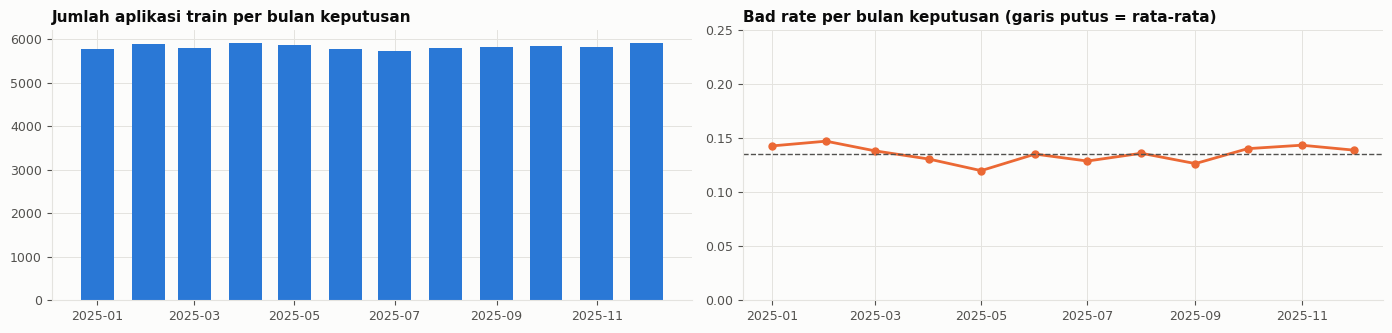

term_months: {12: 70000}


In [7]:
tr = read_raw('train_applications'); te = read_raw('test_applications')
print(f'bad rate train = {BAD_RATE:.4f}  ({int(y.sum()):,} bad dari {len(y):,})')
tr['dec_month'] = tr.decision_datetime.dt.to_period('M').dt.to_timestamp()
m = tr.groupby('dec_month').target.agg(['mean', 'size'])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
axes[0].bar(m.index, m['size'], width=20, color=C_MAIN); axes[0].set_title('Jumlah aplikasi train per bulan keputusan')
axes[1].plot(m.index, m['mean'], marker='o', color=C_BAD); axes[1].axhline(BAD_RATE, ls='--', lw=1, color=C_INK2)
axes[1].set_ylim(0, 0.25); axes[1].set_title('Bad rate per bulan keputusan (garis putus = rata-rata)')
plt.tight_layout(); plt.show()
print('term_months:', tr.term_months.value_counts().to_dict())

Bad rate per bulan stabil di 12–15% sepanjang 2025, jadi tidak ada drift waktu yang perlu ditangani. Semua pinjaman
bertenor 12 bulan. KS hanya bergantung pada urutan skor, jadi ketidakseimbangan kelas tidak perlu di-resample.

### 1.3 Train vs test

In [8]:
print('nasabah sama di train & test:', len(set(tr.customer_id) & set(te.customer_id)))
for c in ['decision_datetime']:
    print(f'{c}: train {tr[c].min()} .. {tr[c].max()} | test {te[c].min()} .. {te[c].max()}')
for d in (tr, te):
    d['dec_hours'] = (d.decision_datetime - d.application_datetime).dt.total_seconds() / 3600
rows = [dict(column=c, mean_train=tr[c].mean(), mean_test=te[c].mean(), ks_2samp=ks_2samp(tr[c], te[c]).statistic)
        for c in ['loan_amount', 'annual_interest_rate', 'proposed_monthly_installment', 'dec_hours']]
display(pd.DataFrame(rows))
display(pd.concat([tr.loan_purpose.value_counts(normalize=True).rename('train'),
                   te.loan_purpose.value_counts(normalize=True).rename('test')], axis=1).T)
smp = read_raw('sample_submission')
print('sample_submission: id sama dengan test =', set(smp.application_id) == set(te.application_id),
      '| urutan sama =', bool((smp.application_id.values == te.application_id.values).all()))

nasabah sama di train & test: 0
decision_datetime: train 2025-01-01 08:00:00 .. 2025-12-28 20:59:00 | test 2025-01-01 08:07:00 .. 2025-12-28 20:52:00


,column,mean_train,mean_test,ks_2samp
0,loan_amount,"23,866,790.0000","23,744,580.0000",0.0036
1,annual_interest_rate,0.2118,0.2119,0.0023
2,proposed_monthly_installment,"2,226,584.7435","2,215,537.4236",0.0033
3,dec_hours,22.6684,23.0869,0.0084


loan_purpose,home_improvement,household,medical,working_capital,education
train,0.2020,0.2001,0.2000,0.1993,0.1986
test,0.2009,0.1996,0.1948,0.2007,0.2040


sample_submission: id sama dengan test = True | urutan sama = False


Train dan test berasal dari periode yang sama dan distribusinya hampir identik (statistik KS dua sampel sangat kecil), jadi
**stratified K-fold acak** adalah validasi yang tepat. Validasi adversarial dengan semua fitur ada di bagian 3.8.
Urutan `sample_submission` berbeda dari file test, jadi submission harus digabung berdasarkan `application_id`.

### 1.4 Cek cutoff / leakage
Semua informasi yang dipakai harus terjadi **sebelum** `decision_datetime` nasabah. Sel ini menghitung baris yang
melanggar di setiap tabel.

In [9]:
cutm = cut.dt.to_period('M').dt.to_timestamp()
pa = read_raw('previous_applications'); rh = read_raw('repayment_history')
ab = read_raw('account_behavior'); bu = read_raw('bureau_observations')
ec_t = read_raw('ecommerce_transactions', ['customer_id', 'transaction_datetime'])
checks = {
    'previous_applications: decision >= cutoff': (pa.decision_datetime >= pa.customer_id.map(cut)).sum(),
    'repayment_history: due_date >= cutoff': (rh.due_date >= rh.customer_id.map(cut)).sum(),
    'repayment_history: last_payment >= cutoff': (rh.last_payment_datetime >= rh.customer_id.map(cut)).sum(),
    'account_behavior: month >= decision month': (ab.month >= ab.customer_id.map(cutm)).sum(),
    'bureau_observations: report >= cutoff': (bu.report_datetime >= bu.customer_id.map(cut)).sum(),
    'bureau_observations: available >= cutoff': (bu.available_datetime >= bu.customer_id.map(cut)).sum(),
    'ecommerce_transactions: transaction >= cutoff': (ec_t.transaction_datetime >= ec_t.customer_id.map(cut)).sum(),
}
display(pd.Series(checks, name='rows violating cutoff').to_frame())
del ec_t; _ = gc.collect()

,rows violating cutoff
previous_applications: decision >= cutoff,0
repayment_history: due_date >= cutoff,0
repayment_history: last_payment >= cutoff,0
account_behavior: month >= decision month,0
bureau_observations: report >= cutoff,0
bureau_observations: available >= cutoff,0
ecommerce_transactions: transaction >= cutoff,0


Nol pelanggaran di semua tabel: penyedia data sudah memotong setiap tabel di cutoff masing-masing nasabah. Risiko
leakage tinggal pada **cara membuat fitur** (target tidak boleh masuk ke fitur; agregat lintas nasabah harus out-of-fold).

### 1.5 Kualitas dan konsistensi data

In [10]:
q = {}
r_ = tr.annual_interest_rate / 12
ann = tr.loan_amount * r_ / (1 - (1 + r_) ** -tr.term_months)
q['cicilan = rumus anuitas (|rasio-1| < 0,1%)'] = ((tr.proposed_monthly_installment / ann - 1).abs() < 1e-3).mean()
q['rekening: opening + inflows - outflows = closing'] = ((ab.opening_balance + ab.inflows - ab.outflows) == ab.closing_balance).mean()
abs_ = ab.sort_values(['customer_id', 'month']); nxt = abs_.groupby('customer_id').opening_balance.shift(-1)
q['rekening: closing(t) = opening(t+1)'] = (nxt.dropna() == abs_.closing_balance[nxt.notna()]).mean()
q['rekening: income_like_credits <= inflows'] = (ab.income_like_credits <= ab.inflows).mean()
ok = bu.dropna(subset=['utilization'])
q['biro: utilization = revolving_outstanding / limit'] = ((ok.utilization - ok.revolving_outstanding_balance / ok.revolving_credit_limit).abs() < 1e-6).mean()
q['biro: utilization kosong <=> limit = 0'] = (bu.utilization.isna() == (bu.revolving_credit_limit == 0)).mean()
q['cicilan: amount_paid = 0 atau = amount_due (tanpa bayar sebagian)'] = ((rh.amount_paid == 0) | (rh.amount_paid >= rh.amount_due)).mean()
display(pd.Series(q, name='share of rows OK').to_frame())
print('Pola NULL di previous_applications per keputusan (share NULL):')
display(pa.groupby('decision')[['loan_id', 'approved_amount', 'annual_interest_rate', 'scheduled_monthly_installment']]
        .apply(lambda g: g.isna().mean()).round(3))
sc = bu.pivot_table(index='application_id', columns='bureau_provider', values='score', aggfunc='mean')
print('Korelasi skor antar provider biro (aplikasi yang sama):'); display(sc.corr().round(3))

,share of rows OK
"cicilan = rumus anuitas (|rasio-1| < 0,1%)",1.0000
rekening: opening + inflows - outflows = closing,1.0000
rekening: closing(t) = opening(t+1),1.0000
rekening: income_like_credits <= inflows,1.0000
biro: utilization = revolving_outstanding / limit,1.0000
biro: utilization kosong <=> limit = 0,1.0000
cicilan: amount_paid = 0 atau = amount_due (tanpa bayar sebagian),0.9801


Pola NULL di previous_applications per keputusan (share NULL):


,loan_id,approved_amount,annual_interest_rate,scheduled_monthly_installment
decision,,,,
approved,0.0000,0.0000,0.0000,0.0000
cancelled,1.0000,1.0000,1.0000,1.0000
rejected,1.0000,1.0000,1.0000,1.0000


Korelasi skor antar provider biro (aplikasi yang sama):


bureau_provider,Bureau_A,Bureau_B,Bureau_C
bureau_provider,,,
Bureau_A,1.0000,0.8130,0.8140
Bureau_B,0.8130,1.0000,0.8140
Bureau_C,0.8140,0.8140,1.0000


Data sangat bersih: identitas saldo rekening berlaku 100%, cicilan mengikuti rumus anuitas, `utilization` konsisten,
dan NULL di `previous_applications` sepenuhnya dijelaskan oleh keputusan (pengajuan ditolak/dibatalkan tidak punya
pinjaman). 98% cicilan **dibayar penuh atau tidak sama sekali**; 2% sisanya dibayar sebagian dan hampir semuanya (98,5%)
masih menunggak saat cutoff, yaitu pembayaran parsial atas tunggakan yang sedang berjalan. Tiga provider biro
memberi bacaan bernoise dari trait yang sama (korelasi ~0,8). Jadi preprocessing tidak perlu imputasi atau pembersihan
outlier; nilai kosong adalah informasi ("tidak punya riwayat").

### 1.6 Riwayat pembayaran: proses bayar/lewati bulanan
Keterlambatan bayar mengelompok di kelipatan satu bulan (0, 28–31, 59–61, … hari) karena pembayaran selalu jatuh tepat di
salah satu tanggal jatuh tempo: setiap bulan nasabah membayar (satu cicilan, atau beberapa sekaligus untuk mengejar
tunggakan) atau melewatkan bulan itu. Pengamatan ini menjadi dasar model struktural di bagian 3.5.

Nilai keterlambatan bayar (hari) yang paling sering:


,0.0000,28.0000,29.0000,30.0000,31.0000,59.0000,60.0000,61.0000
n_installments,914737,12219,8711,84657,144896,9376,5563,60753


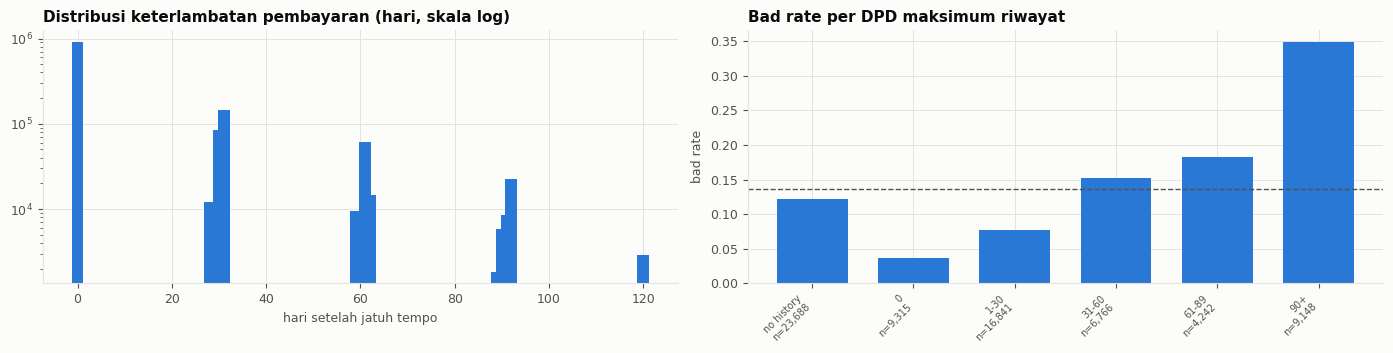

In [11]:
paid = rh.dropna(subset=['last_payment_datetime'])
delay = ((paid.last_payment_datetime - paid.due_date).dt.total_seconds() / 86400).round()
vc = delay.value_counts().sort_index()
print('Nilai keterlambatan bayar (hari) yang paling sering:'); display(vc.head(8).to_frame('n_installments').T)
g = rh.groupby('customer_id')
R = pd.DataFrame({'rh_max_dpd': g.max_days_past_due.max(), 'rh_late_share': (rh.max_days_past_due > 0).groupby(rh.customer_id).mean(),
                  'rh_n_inst': g.size()})
dr = lab.merge(R, left_on='customer_id', right_index=True, how='left')
dr['max_dpd_bucket'] = pd.cut(dr.rh_max_dpd, [-1, 0, 30, 60, 89, 1e9], labels=['0', '1-30', '31-60', '61-89', '90+']).astype(str).replace('nan', 'no history')
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
top = vc[vc.index.isin(range(0, 121))]
axes[0].bar(top.index, top.values, width=2.5, color=C_MAIN); axes[0].set_yscale('log')
axes[0].set_title('Distribusi keterlambatan pembayaran (hari, skala log)'); axes[0].set_xlabel('hari setelah jatuh tempo')
rate_plot(axes[1], dr, 'max_dpd_bucket', order=['no history', '0', '1-30', '31-60', '61-89', '90+'], title='Bad rate per DPD maksimum riwayat')
plt.tight_layout(); plt.show()
del paid, delay; _ = gc.collect()

### 1.7 Sinyal univariat dari setiap tabel
Agregat sederhana per nasabah dibandingkan dengan target (KS dan AUC satu fitur). Ini hanya untuk memahami data;
fitur model dibangun di bagian 3.

,table,feature,coverage,KS,AUC,direction
0,repayment_history,rh_late_share,0.6616,0.4391,0.7840,higher = riskier
1,repayment_history,rh_max_dpd,0.6616,0.3709,0.7443,higher = riskier
2,ecommerce_transactions,ec_days_since_last,1.0000,0.2813,0.3112,higher = safer
3,ecommerce_transactions,ec_orders_7d,1.0000,0.2774,0.6647,higher = riskier
4,bureau_observations,bu_score,0.9990,0.2530,0.3254,higher = safer
5,application/profile,annual_interest_rate,1.0000,0.2301,0.6464,higher = riskier
6,ecommerce_transactions,ec_spend_30d_vs_365d,0.7430,0.1975,0.6315,higher = riskier
7,previous_applications,pa_rate_mean,0.6652,0.1955,0.6328,higher = riskier
8,bureau_observations,bu_utilization,0.4801,0.1485,0.6000,higher = riskier
9,account_behavior,ab_outflow_trend,0.7000,0.1274,0.5865,higher = riskier


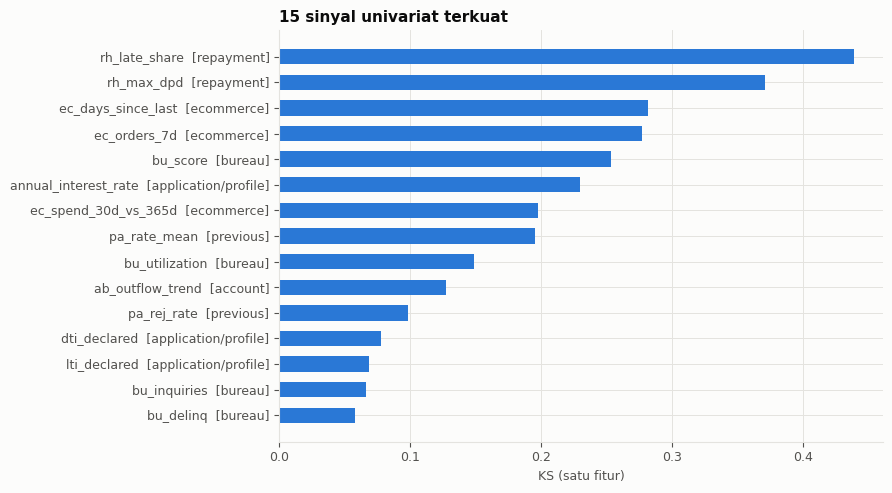

In [12]:
cp = read_raw('customer_profiles')
A = tr[['customer_id', 'target', 'annual_interest_rate', 'loan_amount', 'proposed_monthly_installment', 'dec_hours']].merge(cp, on='customer_id')
A['dti_declared'] = A.proposed_monthly_installment / A.declared_monthly_income
A['lti_declared'] = A.loan_amount / A.declared_monthly_income
sig = [signal_table(A, ['annual_interest_rate', 'dti_declared', 'lti_declared', 'loan_amount', 'age', 'employment_tenure_months',
                        'declared_monthly_income', 'dependents', 'dec_hours'], 'application/profile')]
g = pa.groupby('customer_id')
P = pd.DataFrame({'pa_n': g.size(), 'pa_rej_rate': (pa.decision == 'rejected').groupby(pa.customer_id).mean(),
                  'pa_rate_mean': g.annual_interest_rate.mean()})
sig.append(signal_table(lab.merge(P, left_on='customer_id', right_index=True, how='left'), list(P.columns), 'previous_applications'))
sig.append(signal_table(dr, ['rh_late_share', 'rh_max_dpd', 'rh_n_inst'], 'repayment_history'))
abm = ab.copy(); abm['mb'] = (abm.customer_id.map(cutm).dt.year * 12 + abm.customer_id.map(cutm).dt.month) - (abm.month.dt.year * 12 + abm.month.dt.month)
g = abm.groupby('customer_id'); l3 = abm[abm.mb <= 3].groupby('customer_id'); pr = abm[(abm.mb > 3) & (abm.mb <= 9)].groupby('customer_id')
Ac = pd.DataFrame({'ab_outflow_trend': l3.outflows.mean() / pr.outflows.mean(), 'ab_low_bal_days': g.low_balance_days.mean(),
                   'ab_avg_balance': g.average_balance.mean(), 'ab_income_like': g.income_like_credits.mean()})
sig.append(signal_table(lab.merge(Ac, left_on='customer_id', right_index=True, how='left'), list(Ac.columns), 'account_behavior'))
lat = bu.sort_values('report_datetime').groupby(['customer_id', 'bureau_provider']).tail(1).groupby('customer_id')
Bu = pd.DataFrame({'bu_score': lat.score.mean(), 'bu_delinq': lat.delinquent_accounts_last_12m.max(),
                   'bu_inquiries': lat.inquiries_last_6m.max(), 'bu_utilization': lat.utilization.max()})
sig.append(signal_table(lab.merge(Bu, left_on='customer_id', right_index=True, how='left'), list(Bu.columns), 'bureau_observations'))
ec = read_raw('ecommerce_transactions', ['customer_id', 'order_id', 'transaction_datetime', 'order_total', 'order_status', 'payment_method'])
od = ec.drop_duplicates('order_id').copy(); del ec
od['days_before'] = (od.customer_id.map(cut) - od.transaction_datetime).dt.total_seconds() / 86400
od['spend'] = np.where(od.order_status == 'completed', od.order_total, 0)
g = od.groupby('customer_id')
Ec = pd.DataFrame({'ec_orders_7d': od[od.days_before <= 7].groupby('customer_id').size(),
                   'ec_spend_30d_vs_365d': od[od.days_before <= 30].groupby('customer_id').spend.sum()
                                           / (od[od.days_before <= 365].groupby('customer_id').spend.sum() / 12),
                   'ec_days_since_last': g.days_before.min(), 'ec_cancel_rate': (od.order_status == 'cancelled').groupby(od.customer_id).mean(),
                   'ec_n_orders': g.size()})
Ec['ec_orders_7d'] = Ec.ec_orders_7d.fillna(0)
sig.append(signal_table(lab.merge(Ec, left_on='customer_id', right_index=True, how='left'), list(Ec.columns), 'ecommerce_transactions'))
SIG = pd.concat(sig, ignore_index=True).sort_values('KS', ascending=False).reset_index(drop=True)
display(SIG)
top = SIG.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.feature + '  [' + top.table.str.split('_').str[0] + ']', top.KS, color=C_MAIN, height=0.6)
ax.set_xlabel('KS (satu fitur)'); ax.set_title('15 sinyal univariat terkuat'); plt.tight_layout(); plt.show()

Urutan kekuatan: **riwayat cicilan** (share terlambat, KS 0,44, dihitung pada 66% nasabah yang punya riwayat) >
**aktivitas e-commerce menjelang keputusan** (hari sejak order terakhir dan jumlah order 7 hari terakhir, KS ≈ 0,28) >
**skor biro** (0,25) > **suku bunga** (0,23; *risk-based pricing*: lender sudah memakai riwayat bayar) > tren arus keluar
rekening (0,13). Profil statis (umur, pendapatan, tanggungan) hampir tidak bersinyal sendirian; rasio beban DTI/LTI sedikit
lebih baik (KS 0,07–0,08). Jumlah order total tidak bersinyal (KS 0,02): yang penting adalah **kapan** order terjadi.

### 1.8 Perilaku menjelang keputusan
Nasabah *bad* dan *good* dibandingkan per minggu (e-commerce) dan per bulan (rekening) sebelum keputusan.

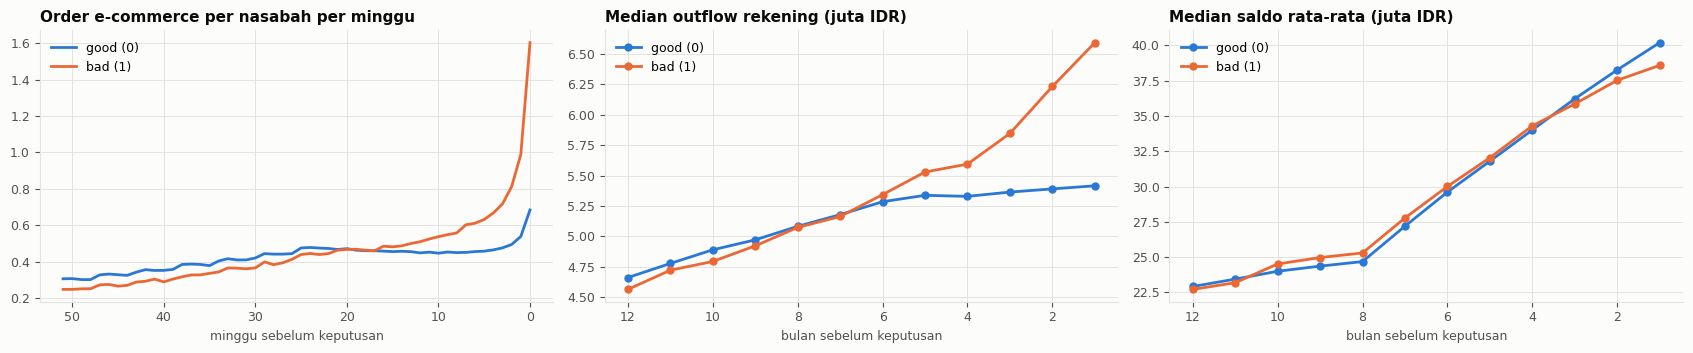

order 7 hari terakhir per nasabah: bad 1.60 vs good 0.68


In [13]:
ot = od.merge(lab, on='customer_id'); ot['week'] = (ot.days_before // 7).astype(int)
n_cust = lab.groupby('target').size()
wk = ot[ot.week < 52].groupby(['week', 'target']).size().unstack() / n_cust
abt = abm.merge(lab, on='customer_id'); abt = abt[abt.mb <= 12]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for t_, c_, nm in [(0, C_GOOD, 'good (0)'), (1, C_BAD, 'bad (1)')]:
    axes[0].plot(wk.index, wk[t_], color=c_, label=nm)
    p = abt[abt.target == t_].groupby('mb')
    axes[1].plot(p.outflows.median().index, p.outflows.median() / 1e6, marker='o', color=c_, label=nm)
    axes[2].plot(p.average_balance.median().index, p.average_balance.median() / 1e6, marker='o', color=c_, label=nm)
axes[0].set_title('Order e-commerce per nasabah per minggu'); axes[0].set_xlabel('minggu sebelum keputusan')
axes[1].set_title('Median outflow rekening (juta IDR)'); axes[2].set_title('Median saldo rata-rata (juta IDR)')
for ax in axes: ax.invert_xaxis(); ax.legend()
axes[1].set_xlabel('bulan sebelum keputusan'); axes[2].set_xlabel('bulan sebelum keputusan')
plt.tight_layout(); plt.show()
print('order 7 hari terakhir per nasabah: bad %.2f vs good %.2f' % tuple(Ec.reindex(lab.customer_id).ec_orders_7d.fillna(0).groupby(lab.target.values).mean()[[1, 0]]))

Nasabah *bad* berbelanja jauh lebih banyak di minggu-minggu terakhir sebelum keputusan (seminggu terakhir 1,60 vs 0,68
order), padahal sepanjang tahun jumlah ordernya mirip: order mereka bergeser mendekati keputusan. Outflow rekening *bad*
mulai menjauh dari *good* sekitar 6 bulan sebelum keputusan lalu naik tajam, sedangkan saldo rata-ratanya setara *good*
sampai ±4 bulan sebelumnya dan tertinggal pada 2–3 bulan terakhir. Pola "perubahan menjelang keputusan" ini lebih
informatif daripada level rata-rata, jadi fitur dibuat relatif terhadap baseline nasabah sendiri (blok H, N3, N5).

### 1.9 Segmen ketersediaan data

In [14]:
seg = lab.copy()
for nm, t in [('prev_app', pa), ('repayment', rh), ('account', ab)]:
    seg[f'has_{nm}'] = seg.customer_id.isin(t.customer_id.unique()).astype(int)
seg['segment'] = np.select([seg.has_repayment == 1, seg.has_prev_app == 1, seg.has_account == 1],
                           ['ada riwayat cicilan', 'pengajuan lama tanpa cicilan', 'hanya rekening'], 'nasabah baru (profil+biro+ecom)')
display(seg.groupby('segment').target.agg(bad_rate='mean', n='size').assign(share=lambda d: d.n / d.n.sum()))
del abm, abt, ot, od, abs_, nxt, ok, sc; _ = gc.collect()

,bad_rate,n,share
segment,,,
ada riwayat cicilan,0.1431,46312,0.6616
nasabah baru (profil+biro+ecom),0.1172,21000,0.3000
pengajuan lama tanpa cicilan,0.1551,2688,0.0384


Tiga segmen dengan ketersediaan data berbeda: 66% nasabah punya riwayat cicilan (bad rate 14,3%), 30% nasabah baru tanpa
pengajuan lama sama sekali (11,7%), dan 4% punya pengajuan lama tetapi tanpa cicilan karena pengajuannya ditolak atau
dibatalkan (15,5%). Nasabah baru hanya punya aplikasi, profil, biro, dan e-commerce, jadi risikonya harus ditebak tanpa
riwayat bayar. Segmen ini dipakai lagi di evaluasi (bagian 5.5 dan 6.5).

### 1.10 Ringkasan EDA → keputusan desain
- **Validasi**: train/test satu periode dan berdistribusi sama → `StratifiedKFold(5)` acak. KS antar fold bervariasi cukup
  besar (SD 0,004–0,012, bagian 5.1), jadi ide baru dinilai juga dengan AUC dan dicek ulang di seed fold lain.
- **Leakage**: data mentah sudah terpotong di cutoff; semua jendela waktu dihitung mundur dari `decision_datetime`.
- **Missing bermakna**: ~34% nasabah tanpa riwayat cicilan; jangan imputasi, biarkan NaN (GBDT) + indikator missing (LR).
- **Mekanisme target**: target = proses bayar/lewati bulanan yang sama dengan riwayat cicilan lama → model struktural
  proses cicilan (N16–N18) yang menyimulasikan 12 bulan pinjaman baru.
- **Perilaku menjelang keputusan** (lonjakan belanja, kenaikan arus keluar rekening, tren laporan biro) → fitur relatif
  terhadap baseline nasabah sendiri.

## 2. Preprocessing
Data mentah sudah bersih (bagian 1.5), jadi preprocessing berfokus pada **ketepatan waktu** dan **representasi**:

| Langkah | Implementasi |
|---|---|
| Parsing & cache | CSV → parquet dengan kolom tanggal di-parse (`cache_raw`, bagian 0) |
| Grain & urutan baris | semua blok fitur disejajarkan ke tabel `key` (train lalu test, 1 baris per nasabah) |
| Cutoff waktu | semua jendela ("30 hari terakhir", "3 bulan terakhir") dihitung mundur dari `decision_datetime` nasabah |
| Deduplikasi | `order_total` diulang di setiap item → agregat order memakai `drop_duplicates('order_id')`; order `cancelled` bukan belanja |
| Encoding kategori | kode integer (`cat.codes`) untuk `loan_purpose`, `region`, `employment_type`, `housing_status` (GBDT memotongnya seperti numerik) |
| Missing value | GBDT: NaN dibiarkan (LightGBM/XGBoost/CatBoost menangani NaN secara native) · LR: indikator missing + NaN → 0 setelah transformasi |
| Nilai tak hingga | rasio dengan penyebut 0 → `inf` diganti NaN di `load_blocks` |
| Skala & outlier | GBDT tidak peka skala/monotonic transform; LR memakai `QuantileTransformer(output='normal')` per fold lalu `StandardScaler` |
| Imbalance | tidak di-resample (KS berbasis urutan; `scale_pos_weight` terbukti merusak, −0,038 KS) |
| Tipe data | `float32` untuk semua fitur model |

Transformasi yang dipelajari dari data (quantile transformer LR, kalibrasi offset, prior θ) **di-fit di dalam fold**,
jadi OOF tetap jujur. Contoh efek deduplikasi order:

In [15]:
ec = read_raw('ecommerce_transactions', ['order_id', 'order_total', 'item_total', 'order_status'])
comp = ec[ec.order_status == 'completed']
print(f'items {len(ec):,} | orders {ec.order_id.nunique():,} | item per order {len(ec) / ec.order_id.nunique():.2f}')
print(f'total belanja salah (jumlah order_total per item) : {comp.order_total.sum() / 1e12:,.2f} triliun IDR')
print(f'total belanja benar (order_total per order unik)    : {comp.drop_duplicates("order_id").order_total.sum() / 1e12:,.2f} triliun IDR')
print(f'cek: jumlah item_total                               : {comp.item_total.sum() / 1e12:,.2f} triliun IDR')
del ec, comp, pa, rh, ab, bu; _ = gc.collect()

items 4,359,817 | orders 2,986,855 | item per order 1.46
total belanja salah (jumlah order_total per item) : 2.23 triliun IDR
total belanja benar (order_total per order unik)    : 1.28 triliun IDR
cek: jumlah item_total                               : 1.28 triliun IDR


## 3. Feature Engineering
Semua fitur dirancang manual dari mekanisme yang terlihat di data mentah. Set final `fin_sh2` berisi **462 fitur**:

| Set fitur | Blok | Jumlah fitur |
|---|---|---|
| base | A–J | 284 |
| KN45 | base + K1–K4 + N23_sel + N4 + N5 | 423 |
| KN16 | KN45 + N16 + N16b (model struktural) | 443 |
| KN17 (lama) | KN16 + N17 (prior θ dari fitur non-cicilan) | 450 |
| FIN (lama) | KN17 + N18 + N18c (guncangan pendapatan, integrasi ketidakpastian) | 462 |
| `kn17_sh` | KN16 + N17sh (prior θ dari kovariat yang tersedia untuk semua nasabah) | 450 |
| **`fin_sh2` (final)** | KN16 + N17sh + N18sh + N18csh | **462** |

Set `kn17_sh` / `fin_sh2` identik dengan KN17 / FIN kecuali kovariat prior θ (bagian 3.6); nama kolomnya pun sama.
Setiap blok disimpan sebagai `WORK_DIR/feat/<blok>.parquet`, dibangun sekali lalu di-cache.

### 3.1 Blok fitur dasar A–J (284 fitur)
Fitur dasar dari iterasi pertama pipeline. Semua jendela waktu ("30 hari terakhir", "bulan ke-0") dihitung mundur dari
`decision_datetime` masing-masing nasabah, jadi agregat hanya memakai informasi yang ada saat keputusan.

| Blok | Isi |
|---|---|
| A | data aplikasi (jumlah, bunga, cicilan, tujuan, waktu) |
| B | profil (umur, masa kerja, pendapatan, tanggungan, DTI deklarasi) |
| C | pengajuan lama (jumlah, penolakan, bunga lama vs sekarang) |
| D | riwayat cicilan (keterlambatan, DPD, beban pinjaman aktif) |
| E | rekening bulanan (saldo, arus kas, tren) |
| F | biro kredit (laporan terbaru per provider, histori skor) |
| G | e-commerce (order, pembatalan, metode bayar, porsi kategori) |
| H | lonjakan belanja / arus keluar terhadap baseline nasabah sendiri |
| I | harga per unit |
| J | **price premium** `log(harga unit) − log(median harga unit kategori)`: sinyal terkuat yang tersedia untuk semua nasabah (AUC univariat 0,751) |

In [16]:
def build_AG():
    """Blocks A-G: application, profile, previous applications, repayment history, account, bureau, e-commerce."""
    tr = read_raw('train_applications'); te = read_raw('test_applications')
    te['target'] = np.nan; tr['is_test'] = 0; te['is_test'] = 1
    app = pd.concat([tr, te], ignore_index=True)
    for c in ['application_datetime', 'decision_datetime']: app[c] = pd.to_datetime(app[c])
    cut = app.set_index('customer_id').decision_datetime
    cp = read_raw('customer_profiles')
    app = app.merge(cp, on='customer_id', how='left')

    # ---------------- A. application ----------------
    A = app[['customer_id']].copy()
    A['loan_amount'] = app.loan_amount
    A['annual_interest_rate'] = app.annual_interest_rate
    A['installment'] = app.proposed_monthly_installment
    A['loan_purpose'] = app.loan_purpose.astype('category').cat.codes
    A['app_to_dec_hours'] = (app.decision_datetime - app.application_datetime).dt.total_seconds()/3600
    A['dec_month'] = app.decision_datetime.dt.month
    A['dec_dow'] = app.decision_datetime.dt.dayofweek
    A['dec_hour'] = app.decision_datetime.dt.hour
    save_cust(A, 'A_app')

    # ---------------- B. profile ----------------
    B = app[['customer_id', 'age', 'employment_tenure_months', 'declared_monthly_income', 'dependents']].copy()
    for c in ['region', 'employment_type', 'housing_status']: B[c] = app[c].astype('category').cat.codes
    B['tenure_to_age'] = app.employment_tenure_months / (app.age*12)
    B['income_per_dep'] = app.declared_monthly_income / (app.dependents+1)
    B['dti_declared'] = app.proposed_monthly_installment / app.declared_monthly_income
    B['lti_declared'] = app.loan_amount / app.declared_monthly_income
    save_cust(B, 'B_profile')

    # ---------------- C. previous applications ----------------
    pa = read_raw('previous_applications')
    for c in ['application_datetime', 'decision_datetime']: pa[c] = pd.to_datetime(pa[c])
    pa['cut'] = pa.customer_id.map(cut)
    pa['days_ago'] = (pa.cut - pa.decision_datetime).dt.total_seconds()/86400
    pa['appr'] = (pa.decision == 'approved').astype(int)
    pa['rej'] = (pa.decision == 'rejected').astype(int)
    pa['canc'] = (pa.decision == 'cancelled').astype(int)
    pa['proc_hours'] = (pa.decision_datetime - pa.application_datetime).dt.total_seconds()/3600
    g = pa.groupby('customer_id')
    C = pd.DataFrame({
        'pa_n': g.size(), 'pa_n_appr': g.appr.sum(), 'pa_n_rej': g.rej.sum(), 'pa_n_canc': g.canc.sum(),
        'pa_rej_rate': g.rej.mean(), 'pa_canc_rate': g.canc.mean(),
        'pa_days_since_last': g.days_ago.min(), 'pa_days_since_first': g.days_ago.max(),
        'pa_req_mean': g.requested_amount.mean(), 'pa_req_max': g.requested_amount.max(),
        'pa_rate_mean': g.annual_interest_rate.mean(), 'pa_rate_max': g.annual_interest_rate.max(), 'pa_rate_min': g.annual_interest_rate.min(),
        'pa_appr_amt_sum': g.approved_amount.sum(),
        'pa_proc_hours_mean': g.proc_hours.mean(),
    })
    for w in [90, 180, 365]:
        s = pa[pa.days_ago <= w].groupby('customer_id')
        C[f'pa_n_{w}d'] = s.size(); C[f'pa_rej_{w}d'] = s.rej.sum()
    last = pa.sort_values('decision_datetime').groupby('customer_id').tail(1).set_index('customer_id')
    C['pa_last_decision'] = last.decision.map({'approved': 0, 'rejected': 1, 'cancelled': 2})
    C['pa_last_rate'] = last.annual_interest_rate
    C['pa_last_req'] = last.requested_amount
    lastap = pa[pa.appr == 1].sort_values('decision_datetime').groupby('customer_id').tail(1).set_index('customer_id')
    C['pa_last_appr_rate'] = lastap.annual_interest_rate
    C['pa_last_appr_days'] = lastap.days_ago
    C = C.reset_index()
    for c in ['pa_n_90d', 'pa_rej_90d', 'pa_n_180d', 'pa_rej_180d', 'pa_n_365d', 'pa_rej_365d']: C[c] = C[c].fillna(0)
    cur = app.set_index('customer_id')
    C = C.merge(cur[['loan_amount', 'annual_interest_rate']].reset_index(), on='customer_id', how='left')
    C['rate_vs_prev_mean'] = C.annual_interest_rate - C.pa_rate_mean
    C['rate_vs_last_appr'] = C.annual_interest_rate - C.pa_last_appr_rate
    C['amt_vs_prev_req'] = C.loan_amount / C.pa_req_mean
    C = C.drop(columns=['loan_amount', 'annual_interest_rate'])
    save_cust(C, 'C_prev')
    del C; gc.collect()

    # ---------------- D. repayment history ----------------
    rh = read_raw('repayment_history')
    for c in ['due_date', 'last_payment_datetime']: rh[c] = pd.to_datetime(rh[c])
    rh['cut'] = rh.customer_id.map(cut)
    rh['due_days_ago'] = (rh.cut - rh.due_date).dt.total_seconds()/86400
    rh['unpaid'] = rh.amount_due - rh.amount_paid
    rh['is_unpaid'] = (rh.amount_paid == 0).astype(int)
    rh['is_partial'] = ((rh.amount_paid > 0) & (rh.amount_paid < rh.amount_due)).astype(int)
    rh['pay_ratio'] = rh.amount_paid / rh.amount_due
    rh['pay_delay'] = (rh.last_payment_datetime - rh.due_date).dt.total_seconds()/86400
    rh['late'] = (rh.max_days_past_due > 0).astype(int)
    for t in [5, 30, 60, 90]: rh[f'mdpd{t}'] = (rh.max_days_past_due >= t).astype(int)
    g = rh.groupby('customer_id')
    D = pd.DataFrame({
        'rh_n_inst': g.size(), 'rh_n_loans': g.loan_id.nunique(),
        'rh_max_dpd': g.max_days_past_due.max(), 'rh_mean_maxdpd': g.max_days_past_due.mean(),
        'rh_cur_dpd_max': g.days_past_due.max(), 'rh_cur_dpd_sum': g.days_past_due.sum(),
        'rh_late_rate': g.late.mean(), 'rh_n_late': g.late.sum(),
        'rh_mdpd5_rate': g.mdpd5.mean(), 'rh_mdpd30_rate': g.mdpd30.mean(), 'rh_mdpd60_n': g.mdpd60.sum(), 'rh_mdpd90_n': g.mdpd90.sum(),
        'rh_unpaid_amt': g.unpaid.sum(), 'rh_n_unpaid': g.is_unpaid.sum(), 'rh_n_partial': g.is_partial.sum(),
        'rh_pay_ratio_mean': g.pay_ratio.mean(), 'rh_pay_delay_mean': g.pay_delay.mean(), 'rh_pay_delay_max': g.pay_delay.max(),
        'rh_amount_due_mean': g.amount_due.mean(),
    })
    D['rh_unpaid_rate'] = D.rh_n_unpaid / D.rh_n_inst
    for w in [90, 180, 365]:
        s = rh[rh.due_days_ago <= w].groupby('customer_id')
        D[f'rh_maxdpd_{w}d'] = s.max_days_past_due.max(); D[f'rh_late_rate_{w}d'] = s.late.mean()
        D[f'rh_paydelay_{w}d'] = s.pay_delay.mean(); D[f'rh_n_{w}d'] = s.size()
    old = rh[rh.due_days_ago > 180].groupby('customer_id').late.mean()
    D['rh_late_trend'] = D['rh_late_rate_180d'] - old
    # last installment behaviour
    lastinst = rh.sort_values('due_date').groupby('customer_id').tail(3).groupby('customer_id')
    D['rh_last3_maxdpd'] = lastinst.max_days_past_due.max(); D['rh_last3_paydelay'] = lastinst.pay_delay.mean()
    # active-loan burden at cutoff (from prev apps: term - installments already due)
    lo = rh.groupby('loan_id').agg(customer_id=('customer_id', 'first'), n_due=('installment_id', 'size'), inst=('amount_due', 'median'),
                                    cur_dpd=('days_past_due', 'max'), mx=('max_days_past_due', 'max'), unpaid=('unpaid', 'sum'))
    lo = lo.join(pa.dropna(subset=['loan_id']).set_index('loan_id')[['term_months', 'approved_amount']])
    lo['remaining'] = (lo.term_months - lo.n_due).clip(lower=0)
    lo['active'] = (lo.remaining > 0).astype(int)
    lo['remaining_amt'] = lo.remaining * lo.inst
    lo['loan_ever90'] = (lo.mx >= 90).astype(int)
    gl = lo.groupby('customer_id')
    D['rh_active_loans'] = gl.active.sum(); D['rh_remaining_inst_amt'] = gl.remaining_amt.sum()
    D['rh_active_monthly_inst'] = lo[lo.active == 1].groupby('customer_id').inst.sum()
    D['rh_n_loans_ever90'] = gl.loan_ever90.sum(); D['rh_frac_loans_ever90'] = gl.loan_ever90.mean()
    D['rh_loans_in_arrears_now'] = (lo.cur_dpd > 0).groupby(lo.customer_id).sum()
    D = D.reset_index()
    D['rh_active_monthly_inst'] = D.rh_active_monthly_inst.fillna(0)
    D = D.merge(app[['customer_id', 'proposed_monthly_installment', 'declared_monthly_income']], on='customer_id', how='left')
    D['total_inst_to_income'] = (D.rh_active_monthly_inst + D.proposed_monthly_installment) / D.declared_monthly_income
    D = D.drop(columns=['proposed_monthly_installment', 'declared_monthly_income'])
    save_cust(D, 'D_repay')
    del rh, D, lo; gc.collect()

    # ---------------- E. account behaviour ----------------
    ab = read_raw('account_behavior')
    ab['month'] = pd.to_datetime(ab.month)
    ab = ab.sort_values(['customer_id', 'month'])
    ab['k'] = ab.groupby('customer_id').cumcount(ascending=False)  # 0 = most recent full month
    ab['net'] = ab.inflows - ab.outflows
    ab['out_in'] = ab.outflows / ab.inflows
    ab['lowflag'] = (ab.low_balance_days > 0).astype(int)
    ab['zero_min'] = (ab.minimum_balance == 0).astype(int)
    cols = ['closing_balance', 'inflows', 'outflows', 'income_like_credits', 'average_balance', 'minimum_balance', 'low_balance_days', 'net', 'out_in']
    E = pd.DataFrame(index=ab.customer_id.unique())
    g = ab.groupby('customer_id')
    E['ab_n_months'] = g.size()
    for w in [1, 3, 6]:
        s = ab[ab.k < w].groupby('customer_id')[cols].mean(); s.columns = [f'ab_{c}_l{w}' for c in cols]; E = E.join(s)
    s = g[cols].mean(); s.columns = [f'ab_{c}_all' for c in cols]; E = E.join(s)
    E['ab_income_std'] = g.income_like_credits.std(); E['ab_income_cv'] = E.ab_income_std / E.ab_income_like_credits_all
    E['ab_lowflag_rate'] = g.lowflag.mean(); E['ab_zero_min_n'] = g.zero_min.sum()
    E['ab_lowdays_max'] = g.low_balance_days.max()
    E['ab_bal_trend'] = E.ab_average_balance_l3 / (E.ab_average_balance_all + 1)
    E['ab_inc_trend'] = E.ab_income_like_credits_l3 / (E.ab_income_like_credits_all + 1)
    E['ab_out_trend'] = E.ab_outflows_l3 / (E.ab_outflows_all + 1)
    # slope of avg balance over last 6 months
    l6 = ab[ab.k < 6]
    xm = l6.groupby('customer_id').k.transform('mean'); ym = l6.groupby('customer_id').average_balance.transform('mean')
    num = ((-l6.k + xm) * (l6.average_balance - ym)).groupby(l6.customer_id).sum()
    den = ((-l6.k + xm)**2).groupby(l6.customer_id).sum()
    E['ab_bal_slope6'] = num/den
    E.index.name = 'customer_id'; E = E.reset_index()
    E = E.merge(app[['customer_id', 'proposed_monthly_installment', 'declared_monthly_income', 'loan_amount']], on='customer_id', how='left')
    E['inst_to_obs_income'] = E.proposed_monthly_installment / E.ab_income_like_credits_l6
    E['inst_to_net_l6'] = E.proposed_monthly_installment / E.ab_net_l6
    E['obs_vs_declared_income'] = E.ab_income_like_credits_l6 / E.declared_monthly_income
    E['inst_to_avgbal_l3'] = E.proposed_monthly_installment / (E.ab_average_balance_l3 + 1)
    E['loan_to_avgbal_l3'] = E.loan_amount / (E.ab_average_balance_l3 + 1)
    E['inst_to_minbal_l3'] = E.proposed_monthly_installment / (E.ab_minimum_balance_l3 + 1)
    E = E.drop(columns=['proposed_monthly_installment', 'declared_monthly_income', 'loan_amount'])
    save_cust(E, 'E_acct')
    del ab, E; gc.collect()

    # ---------------- F. bureau ----------------
    bo = read_raw('bureau_observations')
    for c in ['report_datetime', 'available_datetime']: bo[c] = pd.to_datetime(bo[c])
    bo['cut'] = bo.customer_id.map(cut)
    bo['report_age'] = (bo.cut - bo.report_datetime).dt.total_seconds()/86400
    bo['is_sel'] = bo.application_id.isin(set(app.application_id)).astype(int)
    bo['scored'] = bo.score.notna().astype(int)
    bo['has_rev'] = (bo.revolving_credit_limit > 0).astype(int)
    # latest available obs per provider
    lat = bo.sort_values('report_datetime').groupby(['customer_id', 'bureau_provider']).tail(1)
    num = ['score', 'active_accounts', 'outstanding_balance', 'revolving_credit_limit', 'revolving_outstanding_balance', 'utilization',
           'inquiries_last_6m', 'delinquent_accounts_last_12m', 'report_age']
    g = lat.groupby('customer_id')
    Fb = pd.DataFrame(index=lat.customer_id.unique())
    for c in num:
        Fb[f'bu_{c}_mean'] = g[c].mean(); Fb[f'bu_{c}_max'] = g[c].max(); Fb[f'bu_{c}_min'] = g[c].min()
    Fb['bu_n_providers'] = g.size(); Fb['bu_n_unscored'] = g.scored.apply(lambda s: (1-s).sum())
    # per-provider latest score (providers may differ in scale)
    pv = lat.pivot_table(index='customer_id', columns='bureau_provider', values=['score', 'delinquent_accounts_last_12m', 'utilization', 'inquiries_last_6m'])
    pv.columns = [f'bu_{a}_{b}' for a, b in pv.columns]; Fb = Fb.join(pv)
    # history across all obs
    ga = bo.groupby('customer_id')
    Fb['bu_hist_n_obs'] = ga.size(); Fb['bu_hist_score_mean'] = ga.score.mean(); Fb['bu_hist_score_min'] = ga.score.min()
    Fb['bu_hist_delinq_max'] = ga.delinquent_accounts_last_12m.max(); Fb['bu_hist_inq_max'] = ga.inquiries_last_6m.max()
    old = bo[bo.is_sel == 0].groupby(['customer_id', 'bureau_provider']).score.mean()
    new = bo[bo.is_sel == 1].groupby(['customer_id', 'bureau_provider']).score.mean()
    Fb['bu_score_delta'] = (new - old).groupby('customer_id').mean()
    Fb.index.name = 'customer_id'; Fb = Fb.reset_index()
    Fb = Fb.merge(app[['customer_id', 'declared_monthly_income', 'proposed_monthly_installment']], on='customer_id', how='left')
    Fb['bu_debt_to_income'] = Fb.bu_outstanding_balance_max / Fb.declared_monthly_income
    Fb = Fb.drop(columns=['declared_monthly_income', 'proposed_monthly_installment'])
    save_cust(Fb, 'F_bureau')
    del bo, Fb; gc.collect()

    # ---------------- G. ecommerce ----------------
    ec = read_raw('ecommerce_transactions')
    ec['transaction_datetime'] = pd.to_datetime(ec.transaction_datetime)
    ec['cut'] = ec.customer_id.map(cut)
    ec['days_ago'] = (ec.cut - ec.transaction_datetime).dt.total_seconds()/86400
    ec['comp'] = (ec.order_status == 'completed').astype(int)
    # category spend (completed only)
    ecc = ec[ec.comp == 1]
    cat = ecc.pivot_table(index='customer_id', columns='product_category', values='item_total', aggfunc='sum', fill_value=0)
    cat = cat.div(cat.sum(axis=1), axis=0); cat.columns = [f'ec_share_{c}' for c in cat.columns]
    del ecc
    o = ec.drop_duplicates('order_id')[['order_id', 'customer_id', 'transaction_datetime', 'order_total', 'payment_method', 'comp', 'days_ago']]
    del ec; gc.collect()
    o['spend'] = o.order_total * o.comp
    g = o.groupby('customer_id')
    G = pd.DataFrame({'ec_n_orders': g.size(), 'ec_cancel_rate': 1 - g.comp.mean(), 'ec_spend_total': g.spend.sum(),
                      'ec_order_mean': g.order_total.mean(), 'ec_order_max': g.order_total.max(),
                      'ec_days_since_last': g.days_ago.min(), 'ec_days_since_first': g.days_ago.max()})
    pm = o.pivot_table(index='customer_id', columns='payment_method', values='order_id', aggfunc='count', fill_value=0)
    pm = pm.div(pm.sum(axis=1), axis=0); pm.columns = [f'ec_pm_{c}' for c in pm.columns]
    G = G.join(pm).join(cat)
    for w in [30, 90, 180]:
        s = o[o.days_ago <= w].groupby('customer_id')
        G[f'ec_n_{w}d'] = s.size(); G[f'ec_spend_{w}d'] = s.spend.sum(); G[f'ec_cancel_{w}d'] = 1 - s.comp.mean()
        G[f'ec_cod_{w}d'] = (o[o.days_ago <= w].payment_method == 'COD').groupby(o[o.days_ago <= w].customer_id).mean()
    for c in ['ec_n_30d', 'ec_spend_30d', 'ec_n_90d', 'ec_spend_90d', 'ec_n_180d', 'ec_spend_180d']: G[c] = G[c].fillna(0)
    G['ec_spend_trend'] = G.ec_spend_90d / (G.ec_spend_total * 90 / G.ec_days_since_first.clip(lower=90))
    G['ec_cancel_trend'] = G.ec_cancel_90d - G.ec_cancel_rate
    G['ec_cod_trend'] = G.ec_cod_90d - G.ec_pm_COD
    G.index.name = 'customer_id'; G = G.reset_index()
    G = G.merge(app[['customer_id', 'declared_monthly_income']], on='customer_id', how='left')
    G['ec_spend90_to_income'] = G.ec_spend_90d / (3*G.declared_monthly_income)
    G = G.drop(columns=['declared_monthly_income'])
    save_cust(G, 'G_ecom')


run_block(['A_app', 'B_profile', 'C_prev', 'D_repay', 'E_acct', 'F_bureau', 'G_ecom'], build_AG)

cached: A_app, B_profile, C_prev, D_repay, E_acct, F_bureau, G_ecom


In [17]:
def build_H():
    """Refined 'surge' features: short-window e-commerce intensity and outflow surge relative to customer's own baseline."""
    ec = read_raw('ecommerce_transactions', columns=['order_id', 'customer_id', 'transaction_datetime', 'order_total', 'order_status', 'payment_method'])
    ec = ec.drop_duplicates('order_id')
    ec['days_ago'] = (ec.customer_id.map(cut) - pd.to_datetime(ec.transaction_datetime)).dt.total_seconds()/86400
    ec['spend'] = np.where(ec.order_status == 'completed', ec.order_total, 0)
    H = pd.DataFrame(index=key.customer_id)
    base = ec[(ec.days_ago > 180) & (ec.days_ago <= 545)].groupby('customer_id')
    bn = base.size().reindex(H.index).fillna(0)/365; bs = base.spend.sum().reindex(H.index).fillna(0)/365
    H['ec_base_orders_per_day'] = bn
    for w in [3, 7, 14, 30, 60]:
        s = ec[ec.days_ago <= w].groupby('customer_id')
        n = s.size().reindex(H.index).fillna(0); sp = s.spend.sum().reindex(H.index).fillna(0)
        H[f'ec_n_{w}d_s'] = n; H[f'ec_spend_{w}d_s'] = sp
        H[f'ec_surge_n_{w}d'] = (n/w+0.01)/(bn+0.01)
        H[f'ec_surge_spend_{w}d'] = (sp/w+1000)/(bs+1000)
    H['ec_accel_7_30'] = (H.ec_n_7d_s/7+0.01)/(H.ec_n_30d_s/30+0.01)
    H['ec_accel_30_180'] = (H.ec_n_30d_s/30+0.01)/(ec[ec.days_ago <= 180].groupby('customer_id').size().reindex(H.index).fillna(0)/180+0.01)
    # outflow surge
    ab = read_raw('account_behavior'); ab['month'] = pd.to_datetime(ab.month); ab = ab.sort_values(['customer_id', 'month'])
    ab['k'] = ab.groupby('customer_id').cumcount(ascending=False)
    bo = ab[ab.k >= 6].groupby('customer_id')[['outflows', 'inflows', 'low_balance_days', 'average_balance']].mean()
    for k in [0, 1, 2]:
        s = ab[ab.k == k].set_index('customer_id')
        H[f'ab_out_surge_k{k}'] = (s.outflows/bo.outflows).reindex(H.index)
    H['ab_out_surge_l3'] = (ab[ab.k < 3].groupby('customer_id').outflows.mean()/bo.outflows).reindex(H.index)
    H['ab_low_days_surge_l3'] = (ab[ab.k < 3].groupby('customer_id').low_balance_days.mean()-bo.low_balance_days).reindex(H.index)
    H['ab_net_l3_to_inflow'] = ((ab[ab.k < 3].groupby('customer_id').inflows.sum()-ab[ab.k < 3].groupby('customer_id').outflows.sum())/ab[ab.k < 3].groupby('customer_id').inflows.sum()).reindex(H.index)
    H['ab_out_slope6'] = np.nan
    l6 = ab[ab.k < 6].copy(); l6['x'] = -l6.k; l6['y'] = l6.outflows/l6.customer_id.map(bo.outflows)
    xm = l6.groupby('customer_id').x.transform('mean'); ym = l6.groupby('customer_id').y.transform('mean')
    H['ab_out_slope6'] = (((l6.x-xm)*(l6.y-ym)).groupby(l6.customer_id).sum()/((l6.x-xm)**2).groupby(l6.customer_id).sum()).reindex(H.index)
    save_cust(H.reset_index(), 'H_surge')


def build_I():
    """Unit price per item: medians in recent windows vs the customer's own >365-day baseline, electronics spend."""
    ec = read_raw('ecommerce_transactions', columns=['customer_id', 'transaction_datetime', 'item_total', 'order_status', 'quantity', 'product_category'])
    ec = ec[ec.order_status == 'completed']
    ec['days_ago'] = (ec.customer_id.map(cut) - pd.to_datetime(ec.transaction_datetime)).dt.total_seconds()/86400
    ec['unit'] = ec.item_total/ec.quantity.clip(lower=1)
    I = pd.DataFrame(index=key.customer_id)
    base = ec[ec.days_ago > 365].groupby('customer_id')
    I['ec_unit_med_base'] = base.unit.median(); I['ec_item_med_base'] = base.item_total.median()
    for w in [30, 90, 365]:
        s = ec[ec.days_ago <= w].groupby('customer_id')
        I[f'ec_unit_med_{w}d'] = s.unit.median(); I[f'ec_item_med_{w}d'] = s.item_total.median(); I[f'ec_qty_mean_{w}d'] = s.quantity.mean()
        I[f'ec_unit_ratio_{w}d'] = I[f'ec_unit_med_{w}d']/I.ec_unit_med_base
        el = ec[(ec.days_ago <= w) & (ec.product_category == 'electronics')].groupby('customer_id').item_total.sum()
        I[f'ec_electronics_spend_{w}d'] = el.reindex(I.index).fillna(0)
    save_cust(I.reset_index(), 'I_price')


def build_J():
    """Price premium: unit price relative to the category's typical unit price (removes category-mix effect)."""
    ec = read_raw('ecommerce_transactions', columns=['customer_id', 'transaction_datetime', 'item_total', 'order_status', 'quantity', 'product_category'])
    ec = ec[ec.order_status == 'completed'].copy()
    ec['days_ago'] = (ec.customer_id.map(cut) - pd.to_datetime(ec.transaction_datetime)).dt.total_seconds()/86400
    ec['unit'] = ec.item_total/ec.quantity.clip(lower=1)
    ec['lprem'] = np.log(ec.unit) - np.log(ec.groupby('product_category').unit.transform('median'))
    J = pd.DataFrame(index=key.customer_id)
    for w, lo in [(30, 0), (90, 0), (365, 0), (2000, 0), (2000, 365)]:
        s = ec[(ec.days_ago <= w) & (ec.days_ago > lo)].groupby('customer_id').lprem
        nm = f'{w}d' if lo == 0 else 'base'
        J[f'ec_prem_mean_{nm}'] = s.mean(); J[f'ec_prem_med_{nm}'] = s.median()
    J['ec_prem_shift_90'] = J.ec_prem_mean_90d - J.ec_prem_mean_base
    J['ec_prem_shift_365'] = J.ec_prem_mean_365d - J.ec_prem_mean_base
    save_cust(J.reset_index(), 'J_premium')


run_block('H_surge', build_H); run_block('I_price', build_I); run_block('J_premium', build_J)
BLOCKS = ['A_app', 'B_profile', 'C_prev', 'D_repay', 'E_acct', 'F_bureau', 'G_ecom', 'H_surge', 'I_price', 'J_premium']
print('A-J features:', load_blocks(BLOCKS).shape[1])

cached: H_surge
cached: I_price
cached: J_premium
A-J features: 284


### 3.2 Blok K1–K4
Variasi fitur yang lolos screening pada eksperimen awal: **K1** variasi price premium (z-score, persentil, porsi barang
mahal, per kategori, per metode bayar, 10/30 item terakhir, tren), **K2** gaya bayar cicilan (EWM keterlambatan, bayar lebih
awal, pinjaman terakhir, cicilan pertama), **K3** jam belanja dan isi keranjang, **K4** tren skor/inquiry/outstanding biro.

In [18]:
def build_K():
    """Candidate blocks K1-K4. Customer-level, keyed like the other blocks."""
    # ---------------- K1: price-premium variants ----------------
    ec = read_raw('ecommerce_transactions', columns=['order_id', 'customer_id', 'transaction_datetime', 'item_total', 'order_status',
                                                     'quantity', 'product_category', 'payment_method'])
    ec['ts'] = pd.to_datetime(ec.transaction_datetime)
    ec['days_ago'] = (ec.customer_id.map(cut) - ec.ts).dt.total_seconds()/86400
    ec['unit'] = ec.item_total / ec.quantity.clip(lower=1)
    ec['lu'] = np.log(ec.unit)
    # reference distribution per category from ALL items (completed+cancelled), no target used
    cs = ec.groupby('product_category').lu.agg(['median', 'mean', 'std'])
    ec['lprem'] = ec.lu - ec.product_category.map(cs['median'])
    ec['zprem'] = (ec.lu - ec.product_category.map(cs['mean'])) / ec.product_category.map(cs['std'])
    ec['comp'] = ec.order_status == 'completed'
    K1 = pd.DataFrame(index=idx)
    c = ec[ec.comp]
    for nm, sub in [('365', c[c.days_ago <= 365]), ('all', c)]:
        g = sub.groupby('customer_id')
        K1[f'pz_mean_{nm}'] = g.zprem.mean()
        K1[f'pp_p75_{nm}'] = g.lprem.quantile(.75); K1[f'pp_p25_{nm}'] = g.lprem.quantile(.25)
        K1[f'pp_std_{nm}'] = g.lprem.std(); K1[f'pp_max_{nm}'] = g.lprem.max(); K1[f'pp_min_{nm}'] = g.lprem.min()
        for th in [0, 0.5, 1.0]:
            K1[f'pp_frac_gt{th}_{nm}'] = (sub.lprem > th).groupby(sub.customer_id).mean()
        K1[f'pp_frac_lt-0.5_{nm}'] = (sub.lprem < -0.5).groupby(sub.customer_id).mean()
        K1[f'pp_spendw_{nm}'] = (sub.lprem*sub.item_total).groupby(sub.customer_id).sum() / g.item_total.sum()
        K1[f'pp_qtyw_{nm}'] = (sub.lprem*sub.quantity).groupby(sub.customer_id).sum() / g.quantity.sum()
        K1[f'pp_n_items_{nm}'] = g.size()
    # per category premium (all history, completed)
    pc = c.groupby(['customer_id', 'product_category']).lprem.mean().unstack()
    pc.columns = [f'pp_cat_{x}' for x in pc.columns]; K1 = K1.join(pc)
    K1['pp_cat_mean_of_cats'] = pc.mean(axis=1)            # equal weight per category
    K1['pp_cat_n'] = pc.notna().sum(axis=1)
    # cancelled items premium & all-status premium
    x = ec[~ec.comp].groupby('customer_id').lprem.mean(); K1['pp_cancelled_mean'] = x
    K1['pp_allstatus_mean'] = ec.groupby('customer_id').lprem.mean()
    # last N items premium
    srt = c.sort_values('ts')
    for n in [10, 30]:
        K1[f'pp_last{n}'] = srt.groupby('customer_id').tail(n).groupby('customer_id').lprem.mean()
    # premium trend: slope of lprem over time (per year)
    cc = c[['customer_id', 'days_ago', 'lprem']].copy(); cc['x'] = -cc.days_ago/365
    xm = cc.groupby('customer_id').x.transform('mean'); ym = cc.groupby('customer_id').lprem.transform('mean')
    K1['pp_slope'] = ((cc.x-xm)*(cc.lprem-ym)).groupby(cc.customer_id).sum() / ((cc.x-xm)**2).groupby(cc.customer_id).sum()
    # premium by payment method
    o = c.groupby(['customer_id', 'payment_method']).lprem.mean().unstack(); o.columns = [f'pp_pm_{x}' for x in o.columns]
    K1 = K1.join(o)
    save_idx(K1, 'K1_prem2'); del cc, srt, pc, o; gc.collect()

    # ---------------- K3: shopping time / basket patterns ----------------
    od = ec.drop_duplicates('order_id')[['order_id', 'customer_id', 'ts', 'days_ago', 'comp', 'payment_method']].copy()
    od['hour'] = od.ts.dt.hour; od['wkend'] = od.ts.dt.dayofweek >= 5
    od['night'] = (od.hour < 6) | (od.hour >= 23)
    basket = ec.groupby('order_id').agg(n_items=('item_total', 'size'), qty=('quantity', 'sum'), ncat=('product_category', 'nunique'))
    od = od.join(basket, on='order_id')
    K3 = pd.DataFrame(index=idx)
    g = od.groupby('customer_id')
    K3['tm_night_frac'] = g.night.mean(); K3['tm_wkend_frac'] = g.wkend.mean(); K3['tm_hour_mean'] = g.hour.mean(); K3['tm_hour_std'] = g.hour.std()
    K3['bk_items_mean'] = g.n_items.mean(); K3['bk_qty_mean'] = g.qty.mean(); K3['bk_ncat_mean'] = g.ncat.mean()
    r = od[od.days_ago <= 90].groupby('customer_id')
    K3['tm_night_frac_90'] = r.night.mean(); K3['bk_items_mean_90'] = r.n_items.mean()
    # inter-order gaps
    od = od.sort_values(['customer_id', 'ts']); od['gap'] = od.groupby('customer_id').ts.diff().dt.total_seconds()/86400
    g = od.groupby('customer_id')
    K3['gap_med'] = g.gap.median(); K3['gap_min_recent'] = od[od.days_ago <= 30].groupby('customer_id').gap.min()
    K3['gap_last'] = od.groupby('customer_id').gap.last()
    K3['cod_frac_last10'] = od.groupby('customer_id').tail(10).assign(cod=lambda d: d.payment_method == 'COD').groupby('customer_id').cod.mean()
    save_idx(K3, 'K3_shoptime'); del od, ec, c; gc.collect()

    # ---------------- K2: repayment recency / style ----------------
    rh = read_raw('repayment_history')
    for col in ['due_date', 'last_payment_datetime']: rh[col] = pd.to_datetime(rh[col])
    rh['dda'] = (rh.customer_id.map(cut) - rh.due_date).dt.total_seconds()/86400
    rh['late'] = (rh.max_days_past_due > 0).astype(float)
    rh['delay'] = (rh.last_payment_datetime - rh.due_date).dt.total_seconds()/86400
    K2 = pd.DataFrame(index=idx)
    for hl in [60, 180]:
        w = 0.5 ** (rh.dda / hl)
        K2[f'rp_ewm_late_{hl}'] = (w*rh.late).groupby(rh.customer_id).sum() / w.groupby(rh.customer_id).sum()
        K2[f'rp_ewm_mdpd_{hl}'] = (w*rh.max_days_past_due).groupby(rh.customer_id).sum() / w.groupby(rh.customer_id).sum()
    K2['rp_early_frac'] = (rh.delay < -0.5).groupby(rh.customer_id).mean()
    K2['rp_ontime_exact_frac'] = (rh.delay.abs() < 1/24).groupby(rh.customer_id).mean()
    K2['rp_delay_med'] = rh.groupby('customer_id').delay.median()
    K2['rp_delay_p90'] = rh.groupby('customer_id').delay.quantile(.9)
    K2['rp_mdpd_p75'] = rh.groupby('customer_id').max_days_past_due.quantile(.75)
    # most recent loan
    pa = read_raw('previous_applications', columns=['loan_id', 'decision_datetime'])
    pa = pa.dropna(subset=['loan_id']).set_index('loan_id')
    rh['loan_dec'] = rh.loan_id.map(pd.to_datetime(pa.decision_datetime))
    last_loan = rh.sort_values('loan_dec').groupby('customer_id').loan_id.last()
    ll = rh[rh.loan_id.isin(set(last_loan.values))].groupby('customer_id')
    K2['rp_lastloan_late'] = ll.late.mean(); K2['rp_lastloan_mdpd'] = ll.max_days_past_due.max(); K2['rp_lastloan_n'] = ll.size()
    # per-loan late rate dispersion
    pl = rh.groupby(['customer_id', 'loan_id']).late.mean()
    K2['rp_loan_late_max'] = pl.groupby('customer_id').max(); K2['rp_loan_late_min'] = pl.groupby('customer_id').min()
    K2['rp_frac_loans_any_late'] = (pl > 0).groupby('customer_id').mean()
    # first-installment behaviour
    fi = rh.sort_values('due_date').groupby('loan_id').head(1)
    K2['rp_first_inst_late'] = fi.groupby('customer_id').late.mean()
    save_idx(K2, 'K2_repay2'); del rh; gc.collect()

    # ---------------- K4: bureau trends ----------------
    bo = read_raw('bureau_observations')
    bo['rd'] = pd.to_datetime(bo.report_datetime); bo['age'] = (bo.customer_id.map(cut) - bo.rd).dt.total_seconds()/86400
    bo = bo.sort_values('rd')
    K4 = pd.DataFrame(index=idx)
    x = bo[['customer_id', 'bureau_provider', 'age', 'score', 'inquiries_last_6m', 'outstanding_balance', 'utilization', 'delinquent_accounts_last_12m']].dropna(subset=['score']).copy()
    x['t'] = -x.age/365
    gm = x.groupby(['customer_id', 'bureau_provider'])
    xm = gm.t.transform('mean'); ym = gm.score.transform('mean')
    num = ((x.t-xm)*(x.score-ym)).groupby([x.customer_id, x.bureau_provider]).sum(); den = ((x.t-xm)**2).groupby([x.customer_id, x.bureau_provider]).sum()
    K4['bt_score_slope'] = (num/den.replace(0, np.nan)).groupby('customer_id').mean()
    first = gm.first(); lastv = gm.last()
    d = (lastv - first)
    K4['bt_score_chg'] = d.score.groupby('customer_id').mean(); K4['bt_inq_chg'] = d.inquiries_last_6m.groupby('customer_id').mean()
    K4['bt_out_chg'] = d.outstanding_balance.groupby('customer_id').mean(); K4['bt_delinq_chg'] = d.delinquent_accounts_last_12m.groupby('customer_id').mean()
    K4['bt_score_range'] = (gm.score.max() - gm.score.min()).groupby('customer_id').mean()
    K4['bt_score_std_latest'] = bo.groupby(['customer_id', 'bureau_provider']).tail(1).groupby('customer_id').score.std()
    save_idx(K4, 'K4_bureau2')


run_block(['K1_prem2', 'K3_shoptime', 'K2_repay2', 'K4_bureau2'], build_K)

cached: K1_prem2, K3_shoptime, K2_repay2, K4_bureau2


### 3.3 Blok N2/N3 → N23_sel, N4, N5, N9 (set KN45)
- **N2** biro: provider bisa dipertukarkan dan setiap laporan adalah bacaan bernoise dari trait yang tetap
  (reliabilitas 0,81), jadi rata-rata *semua* laporan lebih efisien daripada laporan terbaru (blok F).
- **N3** posisi order di dalam histori nasabah sendiri: nasabah bad dan good punya jumlah order yang sama, tetapi
  order nasabah bad bergeser mendekati tanggal keputusan (median 181 vs 233 hari sebelum keputusan).
- **N23_sel** = kolom N2/N3 yang lolos screening (8 kolom).
- **N4** estimasi trait yang di-pool dan di-shrink: posterior Beta keterlambatan, bulan tanpa bayar sama sekali,
  porsi COD, likuiditas, grade bunga relatif terhadap skor biro.
- **N5** trajektori rekening dalam skala log terhadap baseline nasabah sendiri + struktur streak/backlog cicilan.
- **N9** variasi price premium. Tidak dipakai sebagai fitur model (tidak menambah), hanya sebagai kovariat prior N18.

KN45 = A–J + K1–K4 + N23_sel + N4 + N5 (423 fitur).

In [19]:
def build_N2():
    """N2: bureau fields averaged over ALL observations (every provider, every past report).

    Rationale (EDA): providers are exchangeable (same score distribution, cross-provider corr 0.813 equals
    same-provider-over-time corr 0.811), and the bad-vs-good gap of every field is flat over report age.
    So each report is an i.i.d. noisy reading of a fixed customer trait and the mean over all ~8 reports is
    the efficient estimate. Block F only has this for the score; for the other fields it uses the latest
    report per provider (1-3 readings) or a max.
    """
    bo = read_raw('bureau_observations')
    bo['age'] = (bo.customer_id.map(cut) - bo.report_datetime).dt.total_seconds() / 86400
    bo['l_out'] = np.log1p(bo.outstanding_balance)
    bo['l_rlim'] = np.log1p(bo.revolving_credit_limit)
    bo['l_rbal'] = np.log1p(bo.revolving_outstanding_balance)
    bo['has_rev'] = (bo.revolving_credit_limit > 0).astype(float)
    bo['unscored'] = bo.score.isna().astype(float)
    fields = ['score', 'inquiries_last_6m', 'delinquent_accounts_last_12m', 'utilization', 'active_accounts',
              'l_out', 'l_rlim', 'l_rbal', 'has_rev', 'unscored']
    g = bo.groupby('customer_id')
    N = pd.DataFrame(index=idx)
    for c in fields:
        N[f'bh_{c}_mean'] = g[c].mean()
    N['bh_delinq_any_frac'] = (bo.delinquent_accounts_last_12m > 0).groupby(bo.customer_id).mean()
    N['bh_inq_sum'] = g.inquiries_last_6m.sum()
    N['bh_score_std'] = g.score.std()
    N['bh_score_n'] = g.score.count()
    # precision-aware posterior mean of the score trait (reliability 0.81 per reading)
    r = 0.81; n = N.bh_score_n
    N['bh_score_post'] = 669 + (n * r / (1 + (n - 1) * r)) * (N.bh_score_mean - 669)
    save_idx(N, 'N2_bhist')


def build_N3():
    """N3: shape of the order-time distribution inside each customer's own e-commerce history.

    Rationale (EDA): bad and good customers place the same number of orders (29.5 vs 29.9) over histories
    of the same length (433 vs 441 days), but bad customers' orders are shifted toward the decision
    (median order 181 vs 233 days before). So the signal is WHERE the orders sit inside the history,
    not how many there are. Counts in fixed windows mix this with history length and total volume;
    here everything is normalised by the customer's own history.
    """
    ec = read_raw('ecommerce_transactions', columns=['order_id', 'customer_id', 'transaction_datetime', 'order_total', 'order_status'])
    o = ec.drop_duplicates('order_id').copy(); del ec
    o['da'] = (o.customer_id.map(cut) - o.transaction_datetime).dt.total_seconds() / 86400
    o['comp'] = (o.order_status == 'completed')
    g = o.groupby('customer_id').da
    L = g.max().clip(lower=7)                                  # observed history span (first order -> decision)
    o['L'] = o.customer_id.map(L)
    o['u'] = 1 - o.da / o.L                                     # 0 = first order, 1 = decision time
    N = pd.DataFrame(index=idx)
    N['ot_span'] = L
    N['ot_mean_da'] = g.mean(); N['ot_med_da'] = g.median()
    N['ot_q10_da'] = g.quantile(0.1); N['ot_q25_da'] = g.quantile(0.25)
    N['ot_u_mean'] = o.groupby('customer_id').u.mean()
    N['ot_u_med'] = o.groupby('customer_id').u.median()
    N['ot_u_mean_comp'] = o[o.comp].groupby('customer_id').u.mean()
    for w in [7, 14, 30, 60, 90, 180]:
        f = (o.da <= w).groupby(o.customer_id).mean()
        N[f'ot_frac_{w}'] = f
        N[f'ot_rel_{w}'] = f / np.minimum(w / L, 1)            # share of orders vs share of history time
    # spend-weighted time centre (completed spend only)
    c = o[o.comp]
    N['ot_u_spendw'] = (c.u * c.order_total).groupby(c.customer_id).sum() / c.order_total.groupby(c.customer_id).sum()
    # MLE of an exponential tilt lambda on u in [0,1]: density ~ exp(lam*u); solve mean(u) = E_lam[u] numerically
    lam_grid = np.linspace(-8, 8, 1601)
    Eu = np.where(np.abs(lam_grid) < 1e-6, 0.5, 1 / (1 - np.exp(-lam_grid)) - 1 / lam_grid)
    N['ot_tilt'] = np.interp(N.ot_u_mean.values, Eu, lam_grid)
    save_idx(N, 'N3_otime')


def build_N23():
    """N23_sel: the N3 order-timing and N2 bureau-history columns that screened positive."""
    a = pd.read_parquet(block_path('N3_otime'))[['application_id', 'ot_tilt', 'ot_u_mean_comp', 'ot_u_mean', 'ot_q25_da']]
    b = pd.read_parquet(block_path('N2_bhist'))[['bh_delinquent_accounts_last_12m_mean', 'bh_delinq_any_frac',
                                                 'bh_inquiries_last_6m_mean', 'bh_l_out_mean']]
    pd.concat([a, b], axis=1).to_parquet(block_path('N23_sel'), index=False)
    print('  N23_sel', a.shape[1] - 1 + b.shape[1], 'columns')


run_block('N2_bhist', build_N2); run_block('N3_otime', build_N3); run_block('N23_sel', build_N23)

cached: N2_bhist
cached: N3_otime
cached: N23_sel


In [20]:
def build_N4():
    """N4: pooled / shrunk estimates of the stable customer traits that several sources measure repeatedly.

    Rationale: the EDA shows each trait (payment discipline, lender risk grade, COD habit, liquidity) is read
    many times with independent noise (installments, past loans, orders, months). The efficient estimate pools
    all readings and shrinks short histories toward the population, which trees approximate only coarsely.
    - rates: mean grade over the current + all past approved loans; grade residual vs the bureau score.
    - repayment: Beta-binomial posterior late propensity (prior fitted by moments), loan-level averages,
      months in which no installment was paid although one was due.
    - e-commerce: COD share on completed orders / items, shrunk.
    - account: share of months with low-balance days, mean log minimum balance, shrunk.
    """
    tr = read_raw('train_applications'); te = read_raw('test_applications')
    app = pd.concat([tr, te]).set_index('customer_id').reindex(idx)
    N = pd.DataFrame(index=idx)

    # ---- risk grades over time ----
    pa = read_raw('previous_applications')
    ap = pa[pa.decision == 'approved']
    g = ap.groupby('customer_id').annual_interest_rate
    s = g.sum().reindex(idx).fillna(0); n = g.count().reindex(idx).fillna(0)
    N['rt_all_mean'] = (s + app.annual_interest_rate) / (n + 1)
    N['rt_n'] = n + 1
    base = load_blocks(BLOCKS); base.index = idx
    sc = base.bu_hist_score_mean
    ok = sc.notna()
    coef = np.polyfit(sc[ok], app.annual_interest_rate[ok], 2)
    N['rt_resid_vs_score'] = app.annual_interest_rate - np.polyval(coef, sc)
    N['rt_all_resid_vs_score'] = N.rt_all_mean - np.polyval(coef, sc)

    # ---- repayment propensity ----
    rh = read_raw('repayment_history')
    rh['late'] = (rh.max_days_past_due > 0).astype(float)
    gl = rh.groupby('customer_id').late
    k_ = gl.sum(); n_ = gl.count()
    p = k_ / n_
    m, v = p.mean(), p.var()
    # method of moments for Beta prior on per-customer late propensity (correct for binomial noise)
    mean_n = n_.mean(); v_true = max(v - m * (1 - m) / mean_n, 1e-4)
    ab = m * (1 - m) / v_true - 1
    a0, b0 = m * ab, (1 - m) * ab
    N['rp_post_late'] = ((k_ + a0) / (n_ + a0 + b0)).reindex(idx)
    for t in [30, 60]:
        kk = (rh.max_days_past_due >= t).groupby(rh.customer_id).sum()
        mm = (kk / n_).mean()
        N[f'rp_post_mdpd{t}'] = ((kk + mm * ab) / (n_ + ab)).reindex(idx)
    pl = rh.groupby(['customer_id', 'loan_id']).late.mean()
    N['rp_loan_mean_late'] = pl.groupby('customer_id').mean().reindex(idx)
    N['rp_loan_max_late'] = pl.groupby('customer_id').max().reindex(idx)
    # months with a due installment but no payment made on any loan in that month
    rh['due_m'] = rh.due_date.dt.to_period('M')
    paid_m = rh.dropna(subset=['last_payment_datetime']).assign(pm=lambda d: d.last_payment_datetime.dt.to_period('M'))
    paid_set = paid_m.groupby('customer_id').pm.apply(set)
    due = rh.groupby('customer_id').due_m.apply(lambda s: sorted(set(s)))
    def miss_frac(c):
        d = due[c]; ps = paid_set.get(c, set())
        return np.mean([x not in ps for x in d]) if len(d) else np.nan
    N['rp_miss_month_frac'] = pd.Series({c: miss_frac(c) for c in due.index}).reindex(idx)

    # ---- e-commerce COD habit ----
    ec = read_raw('ecommerce_transactions', columns=['order_id', 'customer_id', 'payment_method', 'order_status'])
    o = ec.drop_duplicates('order_id')
    oc = o[o.order_status == 'completed']
    gc_ = (oc.payment_method == 'COD').groupby(oc.customer_id)
    k2, n2 = gc_.sum(), gc_.count(); m2 = (k2 / n2).mean()
    N['ec_cod_comp_share'] = (k2 / n2).reindex(idx)
    N['ec_cod_post'] = ((k2 + 10 * m2) / (n2 + 10)).reindex(idx)
    gi = (ec.payment_method == 'COD').groupby(ec.customer_id)
    N['ec_cod_item_share'] = gi.mean().reindex(idx)
    canc = o[o.order_status == 'cancelled']
    N['ec_cod_share_cancelled'] = (canc.payment_method == 'COD').groupby(canc.customer_id).mean().reindex(idx)

    # ---- account liquidity ----
    acc = read_raw('account_behavior')
    acc['lowm'] = (acc.low_balance_days > 0).astype(float)
    ga = acc.groupby('customer_id')
    k3, n3 = ga.lowm.sum(), ga.lowm.count(); m3 = (k3 / n3).mean()
    N['ab_low_post'] = ((k3 + 5 * m3) / (n3 + 5)).reindex(idx)
    N['ab_lmin_mean'] = ga.minimum_balance.apply(lambda s: np.log1p(s.clip(lower=0)).mean()).reindex(idx)
    N['ab_lavg_mean'] = ga.average_balance.apply(lambda s: np.log1p(s.clip(lower=0)).mean()).reindex(idx)
    N['ab_lowdays_mean'] = ga.low_balance_days.mean().reindex(idx)
    save_idx(N, 'N4_pool')


def build_N5():
    """N5: account trajectory in log space + repayment streak / backlog structure.

    Rationale (EDA, account): bad customers start from a HIGHER balance a year before (min balance gap +0.15 log at
    k=7..11) and fall below good customers in the last 3 months (-0.47 log at k=0); outflows rise +0.19 log at k=0.
    So the drop from the customer's own baseline (log k0 - log mean k>=6) is the signal; block E uses raw-level
    ratios with +1 offsets that are dominated by the balance scale.
    Rationale (repayment): payments come in monthly 'pay / skip' decisions (delays are 0, ~30, ~61, ~90 days), so
    streaks of skipped installments and the current backlog describe the process better than averages.
    """
    N = pd.DataFrame(index=idx)
    ab = read_raw('account_behavior').sort_values(['customer_id', 'month'])
    ab['k'] = ab.groupby('customer_id').cumcount(ascending=False)
    for c in ['minimum_balance', 'average_balance', 'closing_balance', 'outflows', 'income_like_credits', 'inflows']:
        ab['l_' + c] = np.log1p(ab[c].clip(lower=0))
    ab['l_other_in'] = np.log1p((ab.inflows - ab.income_like_credits).clip(lower=0))
    base = ab[ab.k >= 6].groupby('customer_id')
    rec1 = ab[ab.k == 0].set_index('customer_id'); rec3 = ab[ab.k < 3].groupby('customer_id')
    for c in ['l_minimum_balance', 'l_average_balance', 'l_outflows', 'l_income_like_credits', 'l_other_in']:
        b = base[c].mean()
        N[f'at_{c}_d0'] = (rec1[c] - b).reindex(idx)
        N[f'at_{c}_d3'] = (rec3[c].mean() - b).reindex(idx)
        N[f'at_{c}_base'] = b.reindex(idx)
    N['at_lowdays_d3'] = (rec3.low_balance_days.mean() - base.low_balance_days.mean()).reindex(idx)
    # log-space slope over the last 6 months
    l6 = ab[ab.k < 6].copy(); l6['x'] = -l6.k
    for c in ['l_minimum_balance', 'l_average_balance', 'l_outflows']:
        xm = l6.groupby('customer_id').x.transform('mean'); ym = l6.groupby('customer_id')[c].transform('mean')
        N[f'at_{c}_slope6'] = (((l6.x - xm) * (l6[c] - ym)).groupby(l6.customer_id).sum()
                               / ((l6.x - xm) ** 2).groupby(l6.customer_id).sum()).reindex(idx)
    # peak-to-now drop of average balance in log space
    N['at_lavg_drop_from_peak'] = (ab.groupby('customer_id').l_average_balance.max() - rec1.l_average_balance).reindex(idx)

    rh = read_raw('repayment_history').sort_values(['customer_id', 'due_date'])
    rh['late'] = (rh.max_days_past_due > 0).astype(int)
    rh['open'] = (rh.amount_paid < rh.amount_due).astype(int)          # not fully paid at the cutoff
    g = rh.groupby('customer_id')
    N['rs_backlog_now'] = g.open.sum().reindex(idx)
    N['rs_backlog_amt_ratio'] = ((rh.amount_due - rh.amount_paid).groupby(rh.customer_id).sum()
                                 / rh.groupby('customer_id').amount_due.mean()).reindex(idx)
    # streaks of consecutive late installments within a loan
    rh = rh.sort_values(['loan_id', 'due_date'])
    rh['brk'] = (rh.late != rh.groupby('loan_id').late.shift()).cumsum()
    runs = rh[rh.late == 1].groupby(['customer_id', 'brk']).size()
    N['rs_max_late_streak'] = runs.groupby('customer_id').max().reindex(idx)
    N['rs_n_late_episodes'] = runs.groupby('customer_id').size().reindex(idx)
    N['rs_mean_late_streak'] = runs.groupby('customer_id').mean().reindex(idx)
    has = N.index.isin(rh.customer_id.unique())
    for c in ['rs_max_late_streak', 'rs_n_late_episodes']:
        N[c] = N[c].fillna(0).where(has)
    N['rs_episodes_per_inst'] = N.rs_n_late_episodes / g.size().reindex(idx)
    # last 3 / last 6 installments (customer level, by due date)
    rh = rh.sort_values(['customer_id', 'due_date'])
    for n in [3, 6]:
        t = rh.groupby('customer_id').tail(n).groupby('customer_id')
        N[f'rs_last{n}_late'] = t.late.mean().reindex(idx)
        N[f'rs_last{n}_mdpd'] = t.max_days_past_due.mean().reindex(idx)
    # catch-up behaviour: installments paid together (same payment timestamp) -> customer paid a backlog at once
    pp = rh.dropna(subset=['last_payment_datetime'])
    bundle = pp.groupby(['customer_id', 'last_payment_datetime']).size()
    N['rs_bundle_frac'] = ((bundle > 1).groupby('customer_id').sum() / bundle.groupby('customer_id').size()).reindex(idx)
    N['rs_bundle_max'] = bundle.groupby('customer_id').max().reindex(idx)
    save_idx(N, 'N5_traj')


def build_N9():
    """N9: more readings of the price-premium trait (used here only as covariates of the N18 prior).

    Rationale: in the KN45 model the premium averaged over ALL items incl. cancelled ones (pp_allstatus_mean) and
    over the last 30 items (pp_last30) are among the top-6 features: cancelled baskets still reveal the price tier a
    customer picks, and a fixed number of recent items gives equal precision to every customer whatever their
    shopping pace. This block spans that space: all-status windows, last-N items (all statuses / completed),
    z-scored premium on last-N, and premium of each order's most expensive item.
    """
    ec = read_raw('ecommerce_transactions', columns=['order_id', 'customer_id', 'transaction_datetime', 'item_total', 'order_status',
                                                     'quantity', 'product_category'])
    ec['da'] = (ec.customer_id.map(cut) - ec.transaction_datetime).dt.total_seconds() / 86400
    ec['lu'] = np.log(ec.item_total / ec.quantity.clip(lower=1))
    cs = ec.groupby('product_category').lu.agg(['median', 'mean', 'std'])
    ec['lp'] = ec.lu - ec.product_category.map(cs['median'])
    ec['zp'] = (ec.lu - ec.product_category.map(cs['mean'])) / ec.product_category.map(cs['std'])
    ec['comp'] = ec.order_status == 'completed'
    N = pd.DataFrame(index=idx)
    for w in [90, 180, 365, 730]:
        s = ec[ec.da <= w].groupby('customer_id')
        N[f'pa_all_{w}'] = s.lp.mean(); N[f'pz_all_{w}'] = s.zp.mean()
    ec = ec.sort_values(['customer_id', 'da'])                      # most recent first
    ec['rk'] = ec.groupby('customer_id').cumcount()
    c = ec[ec.comp].copy(); c['rk'] = c.groupby('customer_id').cumcount()
    for n in [5, 10, 20, 50, 100]:
        N[f'pl_all_last{n}'] = ec[ec.rk < n].groupby('customer_id').lp.mean()
        N[f'pz_all_last{n}'] = ec[ec.rk < n].groupby('customer_id').zp.mean()
        N[f'pl_comp_last{n}'] = c[c.rk < n].groupby('customer_id').lp.mean()
    # order level: most expensive item's premium, mean over orders (365d, all statuses)
    om = ec[ec.da <= 365].groupby(['customer_id', 'order_id']).lp.max()
    N['po_max_mean_365'] = om.groupby('customer_id').mean()
    N['po_max_p75_365'] = om.groupby('customer_id').quantile(0.75)
    N['p_n_items_all'] = ec.groupby('customer_id').size()
    save_idx(N, 'N9_prem3')


run_block('N4_pool', build_N4); run_block('N5_traj', build_N5); run_block('N9_prem3', build_N9)
KN45 = ['K1_prem2', 'K2_repay2', 'K3_shoptime', 'K4_bureau2', 'N23_sel', 'N4_pool', 'N5_traj']
print('KN45 features:', load_blocks(BLOCKS + KN45).shape[1])

cached: N4_pool
cached: N5_traj
cached: N9_prem3
KN45 features: 423


### 3.4 Tabel event cicilan
Pembayaran di data ini berupa keputusan bulanan *bayar / lewati*: keterlambatan hanya 0, ~30, ~61, ~90 hari, dan
pembayaran jatuh tepat di timestamp tanggal jatuh tempo. Jadi setiap (pinjaman, tanggal jatuh tempo) adalah satu
event: backlog `B` saat jatuh tempo tiba, jumlah cicilan yang dibayar saat itu (`npaid`, bisa > 1 kalau nasabah
mengejar tunggakan), dan **beban bulan itu** `tdti` = (cicilan pinjaman ini + cicilan terjadwal pinjaman lain yang
masih aktif) / pendapatan deklarasi. Hasilnya 1,36 juta event dari 66% nasabah. Target tidak dipakai.

In [21]:
EV_PATH = os.path.join(CACHE, 'events.parquet')


def events(rh):
    """One row per (loan, due date): backlog B when the due date arrives, installments paid then (npaid).
    A payment's timestamp equals some due date of the same loan; npaid counts the installments paid at it."""
    rh = rh[['loan_id', 'customer_id', 'due_date', 'last_payment_datetime']].sort_values(['loan_id', 'due_date']).reset_index(drop=True)
    rh['k'] = rh.groupby('loan_id').cumcount() + 1
    ev = rh[['loan_id', 'due_date', 'k']].rename(columns={'due_date': 'last_payment_datetime', 'k': 'p'})
    rh = rh.merge(ev, on=['loan_id', 'last_payment_datetime'], how='left')
    cnt = rh.dropna(subset=['p']).groupby(['loan_id', 'p']).size().rename('npaid').reset_index()
    E = rh[['loan_id', 'customer_id', 'k', 'due_date']].merge(cnt.rename(columns={'p': 'k'}), on=['loan_id', 'k'], how='left')
    E['npaid'] = E.npaid.fillna(0)
    E = E.sort_values(['loan_id', 'k'])
    E['B'] = (E.k - (E.groupby('loan_id').npaid.cumsum() - E.npaid)).clip(lower=1)
    E['Bc'] = E.B.clip(upper=3).astype(int)
    E['mc'] = np.minimum(E.npaid, 2).astype(int)
    return E


def build_events():
    """Repayment events with burden: this loan's scheduled installment + scheduled installments of the customer's
    OTHER loans active at that due date (decided before it, not yet past term), over declared income (tdti) and
    over mean observed income (tdtio)."""
    rh = read_raw('repayment_history')
    E = events(rh)
    E['skip'] = (E.npaid == 0).astype(float)
    pa = read_raw('previous_applications'); pa['decision_datetime'] = pd.to_datetime(pa.decision_datetime)
    pl = pa.dropna(subset=['loan_id']).set_index('loan_id')
    cp = read_raw('customer_profiles').set_index('customer_id')
    ab = read_raw('account_behavior')
    inc_obs = ab.groupby('customer_id').income_like_credits.mean()
    E['inst'] = E.loan_id.map(pl.scheduled_monthly_installment); E['inc'] = E.customer_id.map(cp.declared_monthly_income)
    E['inco'] = E.customer_id.map(inc_obs)
    E['due'] = pd.to_datetime(E.due_date)
    L = pl[['customer_id', 'decision_datetime', 'term_months', 'scheduled_monthly_installment']].copy()
    L['end'] = L.decision_datetime + pd.to_timedelta(L.term_months * 30.44 + 15, unit='D')
    ev = E[['loan_id', 'customer_id', 'due']].reset_index()
    mm = ev.merge(L.reset_index()[['loan_id', 'customer_id', 'decision_datetime', 'end', 'scheduled_monthly_installment']]
                  .rename(columns={'loan_id': 'oloan'}), on='customer_id')
    mm = mm[(mm.oloan != mm.loan_id) & (mm.decision_datetime < mm.due) & (mm.end > mm.due)]
    E['oth'] = mm.groupby('index').scheduled_monthly_installment.sum().reindex(E.index).fillna(0).values
    E['tot'] = E.inst + E.oth
    E['tdti'] = E.tot / E.inc; E['tdtio'] = E.tot / E.inco
    E.to_parquet(EV_PATH)
    print('  events', E.shape)


def load_events():
    E = pd.read_parquet(EV_PATH).reset_index(drop=True)
    E['skip'] = (E.npaid == 0).astype(float)
    E['b2'] = (E.Bc == 2).astype(float); E['b3'] = (E.Bc == 3).astype(float)
    E['k1'] = (E.k == 1).astype(float); E['k2'] = (E.k == 2).astype(float)
    E['dti'] = E.tdti.clip(upper=3.0)
    return E


if not os.path.exists(EV_PATH) or 'events' in FORCE:
    t0 = time.time(); build_events(); print(f'built events in {time.time() - t0:.0f}s')
_E = load_events()
print(f'{len(_E):,} events | {_E.customer_id.nunique():,} customers | skip rate {_E.skip.mean():.3f}')
print('skip rate by total DTI bin:', _E.groupby(pd.cut(_E.dti, [0, .1, .2, .3, .5, .8, 1.3, 3]), observed=True).skip.mean().round(3).to_dict())
del _E

1,361,341 events | 66,157 customers | skip rate 0.172
skip rate by total DTI bin: {Interval(0.0, 0.1, closed='right'): 0.119, Interval(0.1, 0.2, closed='right'): 0.128, Interval(0.2, 0.3, closed='right'): 0.141, Interval(0.3, 0.5, closed='right'): 0.162, Interval(0.5, 0.8, closed='right'): 0.192, Interval(0.8, 1.3, closed='right'): 0.228, Interval(1.3, 3.0, closed='right'): 0.276}


**Mekanisme utama (tanpa target).** Peluang melewatkan cicilan naik tajam dengan beban total cicilan terhadap pendapatan
(DTI bulan itu, termasuk pinjaman lain yang masih berjalan), dan berbeda besar antar nasabah (kecenderungan θ).

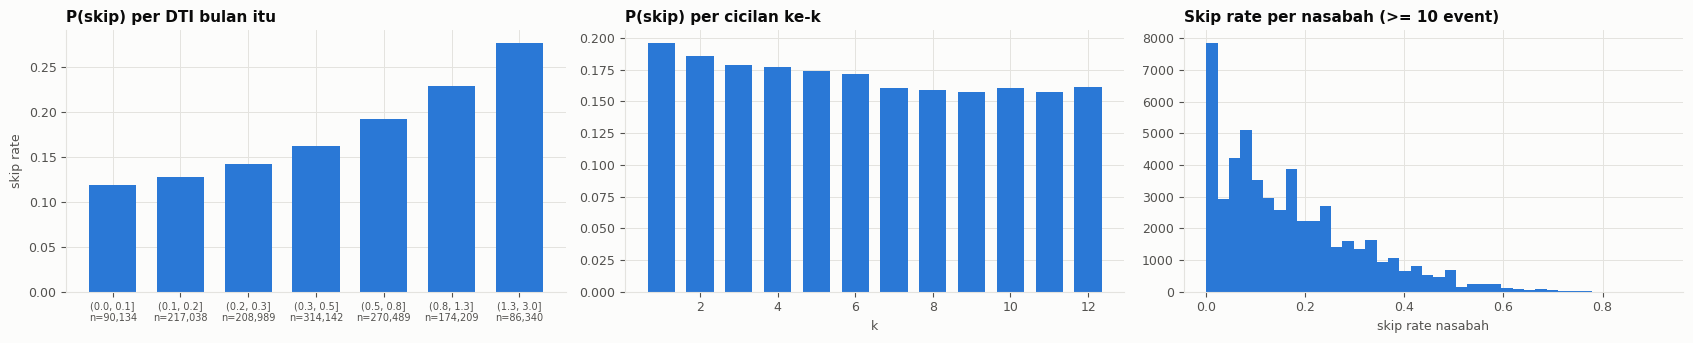

In [22]:
_E = load_events()
fig, axes = plt.subplots(1, 3, figsize=(17, 3.5))
b = _E.groupby(pd.cut(_E.dti, [0, .1, .2, .3, .5, .8, 1.3, 3]), observed=True).skip.agg(['mean', 'size'])
axes[0].bar(range(len(b)), b['mean'], color=C_MAIN, width=0.7)
axes[0].set_xticks(range(len(b))); axes[0].set_xticklabels([f'{i}\nn={n:,}' for i, n in zip(b.index.astype(str), b['size'])], fontsize=7)
axes[0].set_title('P(skip) per DTI bulan itu'); axes[0].set_ylabel('skip rate')
k = _E[_E.k <= 12].groupby('k').skip.mean()
axes[1].bar(k.index, k.values, color=C_MAIN, width=0.7); axes[1].set_title('P(skip) per cicilan ke-k'); axes[1].set_xlabel('k')
cs = _E.groupby('customer_id').skip.agg(['mean', 'size']); cs = cs[cs['size'] >= 10]
axes[2].hist(cs['mean'], bins=40, color=C_MAIN); axes[2].set_title('Skip rate per nasabah (>= 10 event)')
axes[2].set_xlabel('skip rate nasabah')
plt.tight_layout(); plt.show()
del _E, cs; _ = gc.collect()

### 3.5 Model struktural proses cicilan (N16, N16b, N17, N18, N18c)
Sumber kenaikan terbesar (blend +0,006 KS / +0,003 AUC di atas KN45). Idenya: target dibangkitkan oleh proses
bayar/lewati yang sama dengan riwayat cicilan lama, jadi modelkan proses itu lalu simulasikan ke 12 bulan
pinjaman baru.

1. **Model skip per event**: GLM logistik dengan random intercept nasabah θ (empirical Bayes, langkah GLM dan Newton bergantian)
   `logit P(skip) = θ_i + c + c_B + g·DTI + g2·DTI² + e1·[k=1] + e2·[k=2] + m·bulan_sebelum_keputusan [+ guncangan pendapatan]`.
   Skip rate naik dari 11,9% (DTI ≤ 0,1) ke 27,6% (DTI > 1,3) (bagian 3.4). Setelah θ dikontrol, efek "sedang menunggak" ~0.
   `bulan_sebelum_keputusan` adalah nuisance (efek seleksi persetujuan); pinjaman baru dinilai pada nilai 0.
2. **Model mengejar tunggakan**: P(bayar ≥ 2 | bayar, B ≥ 2) dari backlog, DTI, θ; q3/q4 = peluang bayar 3/4 sekaligus.
3. **Profil pinjaman baru**: 12 tanggal jatuh tempo kalender (keputusan + j bulan) dan DTI per bulan
   = (cicilan baru + cicilan pinjaman lama yang masih berjalan) / pendapatan deklarasi.
4. **Rantai Markov backlog** pada 12 jatuh tempo → P(90 DPD dalam 12 bulan), dengan aturan 90 DPD persis:
   cicilan mencapai 90 DPD jika masih belum dibayar di akhir hari jatuh tempo + 90.
5. **Prior θ dari fitur non-cicilan (N17, N18)**: LightGBM di level event (init score = bagian event GLM) belajar f(x)
   dari fitur nasabah yang tidak berasal dari tabel cicilan, out-of-fold per nasabah; posterior θ = f(x) + u_i.
   Nasabah tanpa riwayat cicilan (34%) kini juga mendapat θ yang informatif.
6. **Guncangan pendapatan bulanan (N18)**: skip jauh lebih sering di bulan dengan `income_like_credits` di bawah
   rata-rata nasabah sendiri (logit −0,76 per unit log; bulan sebelumnya −0,15; AR(1) ρ 0,29). Prior N18 dituning
   dengan log-loss event nasabah held-out (bukan target). **N18c** mengintegrasikan ketidakpastian pendapatan
   (aproksimasi probit) dan ketidakpastian θ (Gauss–Hermite 9 titik).

| Blok | Hasil saat ditambahkan (OOF seed 42) |
|---|---|
| N16 | blend l7+LR KS 0,5246 → 0,5311, AUC +0,0013 (naik 5/5 fold; seed 7/99/2024: AUC +0,0015) |
| N16b | ≈ N16 (+0,0002 di atasnya) |
| N17 | di atas N16: LR +0,0033 AUC, blend +0,0015 AUC (konsisten di seed 7/99/2024) |
| N18 + N18c | blend +0,0004 AUC, KS +0,0016 |

Catatan: prior θ versi ini dilatih hanya pada nasabah yang punya riwayat cicilan dan membaca kovariat yang kosong untuk
nasabah baru sebagai 0. Masalah itu diperbaiki di bagian 3.6 (N17sh, N18sh, N18csh).

In [23]:
def fit_ri(E, cols, n_iter=6, w=None, verbose=True, tau2=1.0, theta0=None):
    """Logistic GLM for P(skip) with a customer random intercept theta ~ N(0, tau^2): alternating GLM fit
    (theta as offset) / Newton steps for theta, empirical-Bayes tau^2."""
    cust = np.sort(E.customer_id.unique()); ci = pd.Series(np.arange(len(cust)), index=cust)
    cid = ci.reindex(E.customer_id).values; nC = len(cust)
    X = sm.add_constant(E[cols].values.astype(float)); yv = E.skip.values
    wv = np.ones(len(E)) if w is None else np.asarray(w, float)
    theta = np.zeros(nC) if theta0 is None else theta0.copy()
    for it in range(n_iter):
        glm = sm.GLM(yv, X, family=sm.families.Binomial(), offset=theta[cid], freq_weights=wv).fit()
        beta = glm.params; lin = X @ beta
        for _ in range(3):
            p = expit(lin + theta[cid])
            g = np.bincount(cid, wv * (yv - p), nC) - theta / tau2
            h = np.bincount(cid, wv * p * (1 - p), nC) + 1 / tau2
            theta = theta + g / h
        tau2 = max(np.var(theta) + np.mean(1 / h), 0.05)
        if verbose: print(it, 'beta', dict(zip(['const'] + cols, np.round(beta, 3))), 'tau2', round(tau2, 3), flush=True)
    ll = float(np.sum(wv * (yv * np.log(p + 1e-12) + (1 - yv) * np.log(1 - p + 1e-12))))
    return dict(beta=beta, theta=pd.Series(theta, index=cust), prec=pd.Series(h, index=cust), tau2=tau2, cols=cols, ll=ll)


COLS_B = ['b2', 'b3', 'dti', 'dti2', 'k1', 'k2', 'mbd']                 # N16b / N17 event model
COLS_S = COLS_B + ['linc_d', 'linc_d_prev', 'acct']                     # + monthly income shock (N18 / N18c)


def events_b():
    """Events with DTI^2 and months-before-decision (nuisance term, the new loan is scored at 0)."""
    E = load_events()
    E['mbd'] = (E.customer_id.map(cut) - E.due).dt.total_seconds() / 86400 / 30.44
    E['dti2'] = E.dti ** 2
    return E


def add_income_shock(E):
    """Monthly log-income deviation from the customer's own mean (due month and the month before), from account_behavior.
    Months without account data get deviation 0 and acct = 0. Also returns the account-side quantities the chain needs."""
    ab = read_raw('account_behavior'); ab['month'] = pd.to_datetime(ab.month)
    ab = ab.sort_values(['customer_id', 'month'])
    ab['linc'] = np.log(ab.income_like_credits.clip(lower=1e4))
    ab['linc_d'] = ab.linc - ab.groupby('customer_id').linc.transform('mean')
    E['m0'] = E.due.dt.to_period('M').dt.to_timestamp()
    E = E.merge(ab[['customer_id', 'month', 'linc_d']].rename(columns={'month': 'm0'}), on=['customer_id', 'm0'], how='left')
    a1 = ab[['customer_id', 'month', 'linc_d']].copy(); a1['m0'] = a1.month + pd.DateOffset(months=1)
    E = E.merge(a1.drop(columns='month').rename(columns={'linc_d': 'linc_d_prev'}), on=['customer_id', 'm0'], how='left')
    E['acct'] = E.linc_d.notna().astype(float)
    E['linc_d'] = E.linc_d.fillna(0.0); E['linc_d_prev'] = E.linc_d_prev.fillna(0.0)
    # AR(1) of monthly log income (pooled), last observed month, monthly log-income SD
    ab['lag1'] = ab.groupby('customer_id').linc_d.shift(1)
    m_ = ab.dropna(subset=['lag1']); rho = float(np.corrcoef(m_.linc_d, m_.lag1)[0, 1])
    last = ab.groupby('customer_id').tail(1).set_index('customer_id')
    gap = ((cut - last.month.reindex(key.customer_id).values).dt.days / 30.44).reindex(idx).values
    dev_last = last.linc_d.reindex(idx).values; has_acct = ~np.isnan(dev_last)
    cp = read_raw('customer_profiles').set_index('customer_id').reindex(idx)
    sd_c = ab.groupby('customer_id').linc_d.std()
    ab['emp'] = ab.customer_id.map(cp.employment_type)
    sd_emp = ab.groupby('emp').linc_d.std()
    sig = sd_c.reindex(idx).values
    sig = np.where(np.isnan(sig), cp.employment_type.map(sd_emp).values, sig)    # no / one account month: employment-type SD
    inc = dict(rho=rho, gapv=np.nan_to_num(gap, nan=1.0), dev_last=np.nan_to_num(dev_last), has_acct=has_acct, sig=sig)
    return E, inc


def structural_params(E, cols):
    """Skip GLM with customer random intercept + catch-up model while behind (pays >= 2 given pays, B >= 2) + q3/q4."""
    f = fit_ri(E, cols, verbose=False)
    beta = dict(zip(['c'] + cols, f['beta']))
    E['lin'] = sm.add_constant(E[cols].values.astype(float)) @ f['beta']   # population event part (incl. intercept)
    E['th'] = E.customer_id.map(f['theta'])
    P2 = E[(E.Bc >= 2) & (E.npaid >= 1)]
    bc = sm.GLM((P2.npaid >= 2).astype(float).values, sm.add_constant(np.column_stack([(P2.Bc == 3).astype(float), P2.dti, P2.th])),
                family=sm.families.Binomial()).fit().params
    q3 = float((E[(E.B >= 3) & (E.npaid >= 2)].npaid >= 3).mean())
    q4 = float((E[(E.B >= 4) & (E.npaid >= 3)].npaid >= 4).mean())
    print('  skip model', {k: round(float(v), 3) for k, v in beta.items()}, 'tau2', round(f['tau2'], 3),
          '| catch-up', np.round(bc, 3), 'q3', round(q3, 3), 'q4', round(q4, 3), flush=True)
    return dict(f=f, beta=beta, bc=bc, q3=q3, q4=q4)


_STRUCT = {}


def get_struct(kind):
    """kind 'b': N16b event model; 's': + monthly income shocks. Cached in memory: (events, params, income info)."""
    if kind not in _STRUCT:
        E = events_b(); inc = None
        if kind == 's': E, inc = add_income_shock(E)
        S = structural_params(E, COLS_B if kind == 'b' else COLS_S)
        _STRUCT[kind] = (E, S, inc)
    return _STRUCT[kind]


def new_loan_profile():
    """The new loan's 12 calendar due dates (day numbers, decision + j months, day clipped to month end) and its burden
    DTI_m = (new installment + installments of earlier loans still scheduled in month m) / declared income, clipped at 3."""
    tr_ = read_raw('train_applications'); te_ = read_raw('test_applications')
    app = pd.concat([tr_, te_]).set_index('customer_id').reindex(idx)
    cp = read_raw('customer_profiles').set_index('customer_id').reindex(idx)
    D = pd.to_datetime(app.decision_datetime); n = len(idx)
    due = np.zeros((n, 13), dtype='datetime64[ns]')
    for j in range(13): due[:, j] = (D + pd.DateOffset(months=j)).values
    dd = due.astype('datetime64[D]').astype(np.int64)
    pa = read_raw('previous_applications')
    pl = pa.dropna(subset=['loan_id']).copy(); pl['dd'] = pd.to_datetime(pl.decision_datetime)
    pl['lag_m'] = (pl.customer_id.map(D) - pl.dd).dt.total_seconds() / 86400 / 30.44     # months between old and new decision
    oth = np.zeros((n, 12)); pos = pd.Series(np.arange(n), index=idx.values); r = pos.reindex(pl.customer_id).values
    for j in range(12):
        d = pl.lag_m.values + j + 1                                                        # old-loan month index at new month j+1
        act = (d >= 0.5) & (d <= pl.term_months.values + 0.5)
        np.add.at(oth[:, j], r[act], pl.scheduled_monthly_installment.values[act])
    inc = cp.declared_monthly_income.values.astype(float)
    new_inst = app.proposed_monthly_installment.values.astype(float)
    dti_m = np.clip((new_inst[:, None] + oth) / inc[:, None], 0, 3.0)
    return dict(dd=dd, oth=oth, new_inst=new_inst, dti_m=dti_m)


NL = new_loan_profile()
print('new-loan DTI month 1: median', round(float(np.median(NL['dti_m'][:, 0])), 3), '| share with other active loans',
      round(float((NL['oth'][:, 0] > 0).mean()), 3))

new-loan DTI month 1: median 0.339 | share with other active loans 0.484


In [24]:
def chain(S, th, dti_m, dd, terms=None, var=None, exact=True, include_edge=True):
    """P(90 DPD within 12 months) of the new loan from the backlog Markov chain over its 12 due dates.
    State = unpaid installments after the latest due-date event (0..3); column 4 = 90 DPD reached.
    S: structural parameters (skip GLM beta, catch-up bc, q3, q4). th: propensity per customer (logit).
    terms(j): extra logit terms for due date j (income shock), added in order; var(j): variance of that part,
    integrated with the probit approximation sigmoid(m / sqrt(1 + pi v / 8)).
    exact: 90-DPD calendar rule - with 3 unpaid after an event, default happens before the next due date when that
    date is >= 91 days after the oldest unpaid due date, otherwise only if nothing is paid at that due date.
    include_edge=False drops the default that would need a skip at the 12th due date."""
    beta, bc, q3, q4 = S['beta'], S['bc'], S['q3'], S['q4']
    n = len(th); s = np.zeros((n, 5)); s[:, 0] = 1.0
    for j in range(1, 13):
        x = dti_m[:, j - 1]
        base = beta['c'] + th + beta['dti'] * x + beta['dti2'] * x * x + (beta['k1'] if j == 1 else 0) + (beta['k2'] if j == 2 else 0)
        if terms is not None:
            for t in terms(j): base = base + t
        v = None if var is None else var(j)
        P = (lambda lin: expit(lin)) if v is None else (lambda lin: expit(lin / np.sqrt(1 + np.pi * v / 8)))
        new = np.zeros_like(s); new[:, 4] = s[:, 4]
        # from 'after = 3': oldest unpaid is installment j-3
        if j >= 4:
            gone = (dd[:, j] - dd[:, j - 3] >= 91) if exact else np.zeros(n, bool)
            ps = P(base + beta['b3']); p2 = expit(bc[0] + bc[1] + bc[2] * x + bc[3] * th); s3 = s[:, 3]
            dflt = np.where(gone, s3, s3 * ps)
            if j == 12 and not include_edge: dflt = np.where(gone, s3, 0.0)
            new[:, 4] += dflt
            ok = np.where(gone, 0.0, s3 * (1 - ps))
            new[:, 3] += ok * (1 - p2)                                  # pays 1: still 3 behind (oldest = j-2)
            new[:, 2] += ok * p2 * (1 - q3)                             # pays 2
            new[:, 1] += ok * p2 * q3 * (1 - q4)                        # pays 3
            new[:, 0] += ok * p2 * q3 * q4                              # pays 4
        for a in range(3):
            B = a + 1; sa = s[:, a]
            ps = P(base + (beta['b2'] if B == 2 else 0) + (beta['b3'] if B == 3 else 0))
            if B == 1:
                new[:, 1] += sa * ps; new[:, 0] += sa * (1 - ps)
            elif B == 2:
                p2 = expit(bc[0] + bc[2] * x + bc[3] * th)
                new[:, 2] += sa * ps; new[:, 1] += sa * (1 - ps) * (1 - p2); new[:, 0] += sa * (1 - ps) * p2
            else:
                p2 = expit(bc[0] + bc[1] + bc[2] * x + bc[3] * th)
                new[:, 3] += sa * ps; new[:, 2] += sa * (1 - ps) * (1 - p2)
                new[:, 1] += sa * (1 - ps) * p2 * (1 - q3); new[:, 0] += sa * (1 - ps) * p2 * q3
        s = new
    return s[:, 4]


def logit_clip(p, eps):
    v = np.clip(p, eps, 1 - eps); return np.log(v / (1 - v))


def has_history():
    """Train rows whose customer has repayment events (for the AUC tables)."""
    return key.customer_id[is_tr].isin(pd.read_parquet(EV_PATH, columns=['customer_id']).customer_id.unique()).values

In [25]:
def build_N16():
    """N16: burden-aware structural repayment model (v1) -> default probability of the NEW loan.

    Model: logit P(skip) = theta_i + c_B + g * total_DTI + e1 * [k=1] + e2 * [k=2], theta_i ~ N(0, tau^2).
    Catch-up when paying while behind: logit P(pay >= 2 | pay, B >= 2) = d_B + h * DTI + r * theta_i (population fit).
    Approximate backlog chain over the 11 due dates that can still produce 90 DPD inside 12 months.
    Customers without history get theta = 0 (population) and only the burden part.
    """
    E = load_events()
    f = fit_ri(E, ['b2', 'b3', 'dti', 'k1', 'k2'])
    beta = f['beta']; theta = f['theta'].values; post_prec = f['prec'].values
    cust = f['theta'].index.values; ci = pd.Series(np.arange(len(cust)), index=cust)
    # catch-up model while behind
    P2 = E[(E.Bc >= 2) & (E.npaid >= 1)].copy()
    P2['two'] = (P2.npaid >= 2).astype(float); P2['th'] = theta[ci.reindex(P2.customer_id).values]
    bc = sm.GLM(P2.two.values, sm.add_constant(P2[['b3', 'dti', 'th']].values), family=sm.families.Binomial()).fit().params
    P3 = E[(E.Bc == 3) & (E.npaid >= 2)]
    q3 = (P3.npaid >= 3).mean()
    print('  catch-up beta', np.round(bc, 3), 'P(pay 3 | pay>=2, B3)', round(q3, 3))
    dti_m, oth, new_inst = NL['dti_m'], NL['oth'], NL['new_inst']
    th_all = pd.Series(theta, index=cust).reindex(idx).fillna(0).values
    prec_all = pd.Series(post_prec, index=cust).reindex(idx).values

    def pdefault(th, dti_m, n_dec=11, use_k=True):
        """Backlog chain: state = unpaid installments after the payment event (0,1,2); 3 = 90 DPD reached."""
        n = len(th); s = np.zeros((n, 4)); s[:, 0] = 1.0
        for t in range(n_dec):
            x = dti_m[:, t]
            kk1 = beta[4] if (use_k and t == 0) else 0.0
            kk2 = beta[5] if (use_k and t == 1) else 0.0
            new = np.zeros_like(s); new[:, 3] = s[:, 3]
            for st in range(3):
                B = st + 1
                lin = beta[0] + th + beta[3] * x + kk1 + kk2 + (beta[1] if B == 2 else 0) + (beta[2] if B == 3 else 0)
                ps = expit(lin)                                               # skip
                if B == 1:
                    new[:, 1] += s[:, st] * ps; new[:, 0] += s[:, st] * (1 - ps)
                else:
                    p2 = expit(bc[0] + bc[1] * (B == 3) + bc[2] * x + bc[3] * th)   # pays >= 2 given pays
                    if B == 2:
                        new[:, 2] += s[:, st] * ps; new[:, 1] += s[:, st] * (1 - ps) * (1 - p2); new[:, 0] += s[:, st] * (1 - ps) * p2
                    else:
                        new[:, 3] += s[:, st] * ps; new[:, 2] += s[:, st] * (1 - ps) * (1 - p2)
                        new[:, 1] += s[:, st] * (1 - ps) * p2 * (1 - q3); new[:, 0] += s[:, st] * (1 - ps) * p2 * q3
            s = new
        return s[:, 3]

    N = pd.DataFrame(index=idx)
    N['sb_theta'] = np.where(np.isnan(prec_all), np.nan, th_all)
    N['sb_theta_prec'] = prec_all
    N['sb_pd'] = pdefault(th_all, dti_m)
    N['sb_pd_nodti'] = pdefault(th_all, np.full_like(dti_m, np.median(E.dti)))
    N['sb_dti_new_mean'] = dti_m.mean(1)
    N['sb_dti_new_first4'] = dti_m[:, :4].mean(1)
    N['sb_oth_share_m1'] = oth[:, 0] / (oth[:, 0] + new_inst)
    # history burden: mean total DTI over the customer's past events (what inflated / deflated the late rate)
    N['sb_hist_dti_mean'] = E.groupby('customer_id').dti.mean().reindex(idx)
    N['sb_dti_new_vs_hist'] = N.sb_dti_new_mean - N.sb_hist_dti_mean
    for c in ['sb_pd', 'sb_pd_nodti']:
        N[c.replace('sb_pd', 'sb_lpd')] = np.log(N[c].clip(1e-6, 1 - 1e-6) / (1 - N[c].clip(1e-6, 1 - 1e-6)))
    save_idx(N, 'N16_sburden')
    auc_table(N, has_history())


def build_N16b():
    """N16b: v2 of the structural model, all choices made on the repayment events' likelihood (no target):
    burden as DTI + DTI^2 (concave), own and other-loan burden share one coefficient, a months-before-decision
    nuisance term, no calendar seasonality / customer drift, and the exact 90-DPD calendar rule on the new loan's
    real due dates."""
    E, S, _ = get_struct('b')
    th = S['f']['theta']; prec = S['f']['prec']
    th_all = th.reindex(idx).fillna(0).values
    dti_m, dd = NL['dti_m'], NL['dd']
    N = pd.DataFrame(index=idx)
    N['sb2_theta'] = th.reindex(idx).values
    N['sb2_prec'] = prec.reindex(idx).values
    N['sb2_pd'] = chain(S, th_all, dti_m, dd)
    N['sb2_pd_noedge'] = chain(S, th_all, dti_m, dd, include_edge=False)
    N['sb2_pd_simple'] = chain(S, th_all, dti_m, dd, exact=False)
    N['sb2_pd_flat'] = chain(S, th_all, np.full_like(dti_m, float(np.median(E.dti))), dd)
    N['sb2_span_short'] = sum((dd[:, j] - dd[:, j - 3] <= 90) for j in range(4, 13))       # calendar: 'safe' 3-month spans
    for c in ['sb2_pd', 'sb2_pd_simple']:
        N[c.replace('_pd', '_lpd')] = logit_clip(N[c], 1e-6)
    save_idx(N, 'N16b_sburden2')
    auc_table(N, has_history())


run_block('N16_sburden', build_N16); run_block('N16b_sburden2', build_N16b)

cached: N16_sburden
cached: N16b_sburden2


In [26]:
PRIOR_BLOCKS = BLOCKS + ['K1_prem2', 'K3_shoptime', 'K4_bureau2', 'N23_sel', 'N4_pool', 'N5_traj']


def prior_covariates(extra=()):
    """Customer covariates that do NOT come from the repayment table (prefixes rh_/rp_/rs_/total_inst dropped)."""
    Xc = load_blocks(PRIOR_BLOCKS + list(extra))
    Xc = Xc.loc[:, ~Xc.columns.duplicated()]
    Xc = Xc.drop(columns=[c for c in Xc.columns if c.startswith(('rh_', 'rp_', 'rs_', 'total_inst'))])
    Xc.index = idx.values
    return Xc


def fit_prior(E, Xc, params, n_trees):
    """theta prior f(x): LightGBM on the repayment EVENTS (label = skip, init score = GLM event part E.lin), fitted
    out-of-fold by customer (5 folds): customers with history get the prediction of the model that never saw their
    events; customers without history get the average of the 5 models."""
    cust_all = idx.values
    cf = pd.Series(np.random.RandomState(1).randint(0, 5, len(cust_all)), index=cust_all)
    ef = cf.reindex(E.customer_id).values
    fx = pd.Series(0.0, index=cust_all)
    has_hist = pd.Index(E.customer_id.unique())
    nh = cust_all[~pd.Index(cust_all).isin(has_hist)]
    for k in range(5):
        tr = ef != k
        m = lgb.train(params, lgb.Dataset(Xc.loc[E.customer_id.values[tr]].values, E.skip.values[tr], init_score=E.lin.values[tr]), n_trees)
        tgt = cust_all[(cf.values == k) & pd.Index(cust_all).isin(has_hist)]
        fx.loc[tgt] = m.predict(Xc.loc[tgt].values, raw_score=True)
        fx.loc[nh] += m.predict(Xc.loc[nh].values, raw_score=True) / 5
        print('  prior fold', k, 'trees', m.num_trees(), flush=True)
    return fx


def posterior(E, S, fx):
    """Customer deviation u_i ~ N(0, s^2) around the covariate prior (Newton steps, EB variance): theta_post = f(x) + u."""
    f = S['f']; cust_all = idx.values
    cust = f['theta'].index.values; ci = pd.Series(np.arange(len(cust)), index=cust)
    cid = ci.reindex(E.customer_id).values; nC = len(cust)
    off = E.lin.values + fx.reindex(E.customer_id).values
    yv = E.skip.values; u = np.zeros(nC); s2 = 0.5
    for it in range(8):
        for _ in range(3):
            p = expit(off + u[cid])
            g = np.bincount(cid, yv - p, nC) - u / s2
            h = np.bincount(cid, p * (1 - p), nC) + 1 / s2
            u = u + g / h
        s2 = max(np.var(u) + np.mean(1 / h), 0.02)
    print('  residual s2', round(s2, 3), 'vs tau2 without covariates', round(f['tau2'], 3))
    th_post = fx.copy(); th_post.loc[cust] = fx.loc[cust].values + u
    prec_post = pd.Series(1 / s2, index=cust_all); prec_post.loc[cust] = h
    return th_post, prec_post


def build_N17(shared=None, out='N17_sprior'):
    """N17: covariate-informed prior for theta (empirical Bayes) and the structural PD of the new loan for EVERY customer.
    theta is predictable from what the other sources measure (premium, order timing, bureau, pricing grade ...), so
    logit P(skip) = N16b event part + f(x_i) + u_i. The target is never used.
    shared / out: section 3.6 rebuilds the block with the prior learned from the shared covariates only."""
    E, S, _ = get_struct('b')
    Xc = prior_covariates()
    if shared is not None: Xc = Xc[[c for c in Xc.columns if c in set(shared)]]
    print('  covariates', Xc.shape[1], flush=True)
    P = dict(objective='binary', learning_rate=0.05, num_leaves=31, min_child_samples=2000, feature_fraction=0.7,
             bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0, verbose=-1, num_threads=THREADS_PRIOR, seed=0)
    fx = fit_prior(E, Xc, P, 600); del Xc; gc.collect()
    th_post, prec_post = posterior(E, S, fx)
    dti_m, dd = NL['dti_m'], NL['dd']
    N = pd.DataFrame(index=idx)
    N['sp_theta_prior'] = fx.reindex(idx).values
    N['sp_theta_post'] = th_post.reindex(idx).values
    N['sp_prec_post'] = prec_post.reindex(idx).values
    N['sp_pd_post'] = chain(S, th_post.reindex(idx).values, dti_m, dd)
    N['sp_pd_prior'] = chain(S, fx.reindex(idx).values, dti_m, dd)
    for c in ['sp_pd_post', 'sp_pd_prior']:
        N[c.replace('_pd', '_lpd')] = logit_clip(N[c], 1e-7)
    save_idx(N, out)
    auc_table(N, has_history())


run_block('N17_sprior', build_N17)

cached: N17_sprior


In [27]:
def shock_terms(S, inc, use_shock=True):
    """Expected income-shock part of the logit at due date j: rho^h * last deviation (h = months from the last account month)."""
    beta = S['beta']
    def terms(j):
        h_ = inc['gapv'] + j
        ev = (inc['rho'] ** h_) * inc['dev_last'] if use_shock else 0.0
        evp = (inc['rho'] ** (h_ - 1)) * inc['dev_last'] if use_shock else 0.0
        return [beta['linc_d'] * ev, beta['linc_d_prev'] * evp, beta['acct'] * inc['has_acct']]
    return terms


def build_N18(shared=None, out='N18_sprior3'):
    """N18 (= fe_n17b.py with the tuned prior): N17 with monthly income shocks in the event model, and the latest account
    month's deviation projected on the new loan's first due dates (AR(1)). Prior hyper-parameters (lr 0.03, 1100 trees,
    min_child 4000) and the extra covariate blocks (N9 premium variants, N3 order timing) were chosen by held-out-customer
    EVENT log-loss, not by the target. shared / out: section 3.6 (prior from the shared covariates only)."""
    E, S, inc = get_struct('s')
    Xc = prior_covariates(['N9_prem3', 'N3_otime'])
    if shared is not None: Xc = Xc[[c for c in Xc.columns if c in set(shared)]]
    print('  covariates', Xc.shape[1], flush=True)
    P = dict(objective='binary', learning_rate=0.03, num_leaves=31, min_child_samples=4000, feature_fraction=0.7,
             bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0, verbose=-1, num_threads=THREADS_PRIOR, seed=0)
    fx = fit_prior(E, Xc, P, 1100); del Xc; gc.collect()
    th_post, prec_post = posterior(E, S, fx)
    print('  income AR(1) rho', round(inc['rho'], 3))
    dti_m, dd = NL['dti_m'], NL['dd']
    tp = th_post.reindex(idx).values
    N = pd.DataFrame(index=idx)
    N['sq_theta_prior'] = fx.reindex(idx).values
    N['sq_theta_post'] = tp
    N['sq_prec_post'] = prec_post.reindex(idx).values
    N['sq_pd_post'] = chain(S, tp, dti_m, dd, terms=shock_terms(S, inc))
    N['sq_pd_post_noshock'] = chain(S, tp, dti_m, dd, terms=shock_terms(S, inc, use_shock=False))
    N['sq_inc_dev_last'] = np.where(inc['has_acct'], inc['dev_last'], np.nan)
    N['sq_lpd_post'] = logit_clip(N['sq_pd_post'], 1e-7)
    save_idx(N, out)
    auc_table(N, has_history())


def build_N18c(src_block='N18_sprior3', out='N18c_spint'):
    """N18c (= fe_n17c.py on N18): the structural PD with both uncertainties integrated out.
    - income: per due month the shock term b1*e_t + b2*e_{t-1}, e ~ AR(1) (rho) around the expected deviation, variance from
      the customer's own monthly log-income SD (no account data: employment-type average); probit approximation.
    - propensity: theta ~ N(theta_post, 1/precision) is shared by all months of the loan, so it is integrated over the whole
      chain with 9-node Gauss-Hermite quadrature, not per month.
    Rationale: for customers with >= 20 repayment events the structural PD leaves almost nothing for other features except
    income volatility - each month's skip depends on that month's income shock."""
    E, S, inc = get_struct('s')
    beta = S['beta']; b1, b2_ = beta['linc_d'], beta['linc_d_prev']
    rho, gapv, dev_last, has_acct, sig = inc['rho'], inc['gapv'], inc['dev_last'], inc['has_acct'], inc['sig']

    def mu(j):
        h = gapv + j
        return [b1 * (rho ** h) * dev_last + b2_ * (rho ** (h - 1)) * dev_last, beta['acct'] * has_acct]

    def var(j):
        h = gapv + j
        v1 = sig ** 2 * (1 - rho ** (2 * h)); v0 = sig ** 2 * (1 - rho ** (2 * (h - 1)))
        cov = rho * v0                                                   # cov(e_t, e_{t-1}) given the last observation
        return b1 ** 2 * v1 + b2_ ** 2 * v0 + 2 * b1 * b2_ * cov

    src = pd.read_parquet(block_path(src_block))
    th = src.sq_theta_post.values; prec = src.sq_prec_post.values
    dti_m, dd = NL['dti_m'], NL['dd']
    xs, ws = np.polynomial.hermite_e.hermegauss(9); ws = ws / ws.sum()
    N = pd.DataFrame(index=idx)
    N['si_pd_inc'] = chain(S, th, dti_m, dd, terms=mu, var=var)
    pd_full = np.zeros(len(th))
    for xk, wk in zip(xs, ws):
        pd_full += wk * chain(S, th + xk / np.sqrt(prec), dti_m, dd, terms=mu, var=var)
    N['si_pd_full'] = pd_full
    N['si_inc_sd'] = sig
    for c in ['si_pd_inc', 'si_pd_full']:
        N[c.replace('_pd', '_lpd')] = logit_clip(N[c], 1e-7)
    save_idx(N, out)
    auc_table(N, has_history())


run_block('N18_sprior3', build_N18); run_block('N18c_spint', build_N18c)
_STRUCT.clear(); _ = gc.collect()

cached: N18_sprior3
cached: N18c_spint


### 3.6 Perbaikan prior θ: hanya kovariat yang tersedia untuk semua nasabah (N17sh, N18sh, N18csh)
Prior θ di N17/N18 adalah LightGBM yang dilatih pada **event cicilan**, jadi hanya melihat nasabah yang punya riwayat cicilan.
Semua nasabah itu juga punya data pengajuan lama dan rekening. Sebaliknya, 30.000 nasabah baru tidak punya keduanya, padahal
bagi mereka prior inilah hampir seluruh PD struktural. Dua masalah muncul:

1. **Pola kosong yang tidak pernah dilihat saat training.** Sekitar 120 kovariat (pengajuan lama `pa_*`, rekening
   `ab_*`/`at_*`, tren biro `bt_*`, rasio terhadap saldo) kosong atau konstan untuk nasabah baru, dan 111 di antaranya tidak
   pernah NaN di data latih prior. LightGBM memperlakukan NaN pada fitur seperti itu **sebagai 0** (dicek di bawah), sehingga
   nasabah baru dinilai seolah-olah punya 0 pengajuan, saldo 0, bunga lama 0, dan seterusnya. Untuk 87 kovariat, nilai 0 bahkan
   berada di bawah rentang data latih.
2. **Informasi yang terhitung dua kali.** Sebagian kovariat itu adalah fungsi dari event cicilan itu sendiri: outflow
   rekening memuat cicilan yang dibayar (0,87 × cicilan dibayar, bagian 8.2), dan bunga pinjaman lama ditentukan lender dari
   riwayat bayar. Posterior θ menggabungkan prior dengan likelihood event yang sama, jadi informasi itu terhitung dua kali.
   Ini kemungkinan alasan AUC nasabah lama ikut naik setelah perbaikan.

**Perbaikan**: prior dilatih hanya dari kovariat yang teramati untuk semua nasabah (aplikasi, profil, biro, e-commerce).
Sisanya identik dengan N17/N18/N18c: model event, setting LightGBM, fold nasabah, posterior, rantai Markov, dan nama kolom.
Pemilihan kolom hanya berdasarkan pola ketersediaan data, tanpa target.

In [28]:
def covariate_availability():
    """Prior covariates (as in N18) and their availability. A column is 'old-only' when it is (almost) always NaN, or constant,
    for the new customers (no previous application, hence no repayment or account data either) but observed for customers
    with repayment history."""
    Xc = prior_covariates(['N9_prem3', 'N3_otime'])
    ev_c = pd.read_parquet(EV_PATH, columns=['customer_id']).customer_id.unique()
    pa_c = read_raw('previous_applications', columns=['customer_id']).customer_id.unique()
    cust = idx.values; g_hist = np.isin(cust, ev_c); g_new = ~np.isin(cust, pa_c)
    V = Xc.values
    nan_h = np.isnan(V[g_hist]).mean(0); nan_n = np.isnan(V[g_new]).mean(0)
    nun_n = np.array([len(np.unique(v[~np.isnan(v)])) for v in V[g_new].T])
    D = pd.DataFrame(dict(col=Xc.columns, nan_hist=nan_h, nan_new=nan_n, nuniq_new=nun_n))
    D['old_only'] = (D.nan_new - D.nan_hist > 0.5) | ((D.nuniq_new <= 1) & (D.nan_new < 1))
    return Xc, D, g_hist, g_new


Xc_prior, COV, g_hist, g_new = covariate_availability()
g_oldnr = ~g_hist & ~g_new                       # old customers without repayment events (only rejected / cancelled applications)
SHARED = COV.loc[~COV.old_only, 'col'].tolist()
ab_c = read_raw('account_behavior', columns=['customer_id']).customer_id.unique()
print(f'nasabah dengan event cicilan {g_hist.sum():,} | baru (tanpa pengajuan lama) {g_new.sum():,} | lama tanpa cicilan {g_oldnr.sum():,}')
print('nasabah baru dengan data rekening:', int((g_new & np.isin(idx.values, ab_c)).sum()),
      '| nasabah dengan event cicilan tanpa data rekening:', int((g_hist & ~np.isin(idx.values, ab_c)).sum()))
print(f'kovariat prior {len(COV)} | hanya untuk nasabah lama {int(COV.old_only.sum())} '
      f'(tidak pernah NaN di data latih prior: {int((COV.old_only & (COV.nan_hist == 0)).sum())}) | shared {len(SHARED)}')
print('kovariat lama-saja per prefix:', COV[COV.old_only].col.str.split('_').str[0].value_counts().to_dict())
# LightGBM: a feature that never had NaN in training sends NaN down the branch of the value 0 at prediction time
rs_ = np.random.RandomState(0); Xt = rs_.normal(size=(20000, 2)); Xt[:, 0] += 3
yt = (Xt[:, 0] + 0.3 * rs_.normal(size=20000) > 3).astype(int)
mt = lgb.train(dict(objective='binary', verbose=-1, num_leaves=7, seed=0), lgb.Dataset(Xt, yt), 50)
print('LightGBM, skor mentah untuk fitur = NaN / 0 / 3 / 10:',
      np.round(mt.predict(np.array([[np.nan, 0.], [0., 0.], [3., 0.], [10., 0.]]), raw_score=True), 3))
oo = COV[COV.old_only & (COV.nan_hist == 0)].col.tolist(); mn = Xc_prior.loc[g_hist, oo].min()
print(f'dari {len(oo)} kovariat itu, nilai 0 ada di bawah atau tepat di batas minimum data latih untuk {int((mn >= 0).sum())}')

nasabah dengan event cicilan 66,157 | baru (tanpa pengajuan lama) 30,000 | lama tanpa cicilan 3,843
nasabah baru dengan data rekening: 0 | nasabah dengan event cicilan tanpa data rekening: 0
kovariat prior 391 | hanya untuk nasabah lama 120 (tidak pernah NaN di data latih prior: 111) | shared 271
kovariat lama-saja per prefix: {'ab': 57, 'pa': 26, 'at': 20, 'bt': 6, 'inst': 4, 'rate': 2, 'amt': 1, 'loan': 1, 'obs': 1, 'bu': 1, 'rt': 1}
LightGBM, skor mentah untuk fitur = NaN / 0 / 3 / 10: [-5.37  -5.37  -0.107  5.504]
dari 111 kovariat itu, nilai 0 ada di bawah atau tepat di batas minimum data latih untuk 87


In [29]:
# Same builders as 3.5; only the prior covariates are restricted to SHARED (N17sh uses the PRIOR_BLOCKS part of it)
run_block('N17sh_sprior', lambda: build_N17(shared=SHARED, out='N17sh_sprior'))
run_block('N18sh_sprior3', lambda: build_N18(shared=SHARED, out='N18sh_sprior3'))
run_block('N18csh_spint', lambda: build_N18c(src_block='N18sh_sprior3', out='N18csh_spint'))
_STRUCT.clear(); _ = gc.collect()
FINSH_BLOCKS = KN45 + ['N16_sburden', 'N16b_sburden2', 'N17sh_sprior', 'N18sh_sprior3', 'N18csh_spint']     # final feature set

cached: N17sh_sprior
cached: N18sh_sprior3
cached: N18csh_spint


In [30]:
# Old vs shared prior on the train rows: univariate AUC per segment, the level of theta for the new customers, residual variance
_b = {nm: pd.read_parquet(block_path(nm)) for nm in ['N17_sprior', 'N17sh_sprior', 'N18_sprior3', 'N18sh_sprior3', 'N18c_spint', 'N18csh_spint']}
segs = {'semua': np.ones(len(idx), bool), 'riwayat cicilan': g_hist, 'baru': g_new, 'lama tanpa cicilan': g_oldnr}
cols_ = {'θ prior N17 (lama)': ('N17_sprior', 'sp_theta_prior'), 'θ prior N17sh': ('N17sh_sprior', 'sp_theta_prior'),
         'θ prior N18 (lama)': ('N18_sprior3', 'sq_theta_prior'), 'θ prior N18sh': ('N18sh_sprior3', 'sq_theta_prior'),
         'PD N18 (lama)': ('N18_sprior3', 'sq_lpd_post'), 'PD N18sh': ('N18sh_sprior3', 'sq_lpd_post'),
         'PD terintegrasi N18c (lama)': ('N18c_spint', 'si_lpd_full'), 'PD terintegrasi N18csh': ('N18csh_spint', 'si_lpd_full')}
rows = []
for lab_, (blk, col) in cols_.items():
    v = _b[blk][col].values[is_tr]; r = dict(fitur=lab_)
    for s_, m_ in segs.items(): r[s_] = roc_auc_score(y[m_[is_tr]], v[m_[is_tr]])
    rows.append(r)
print('AUC univariat per segmen (baris train):'); display(pd.DataFrame(rows).round(4))
print('rata-rata θ prior | nasabah baru: N18 %+.3f -> N18sh %+.3f | nasabah dengan riwayat: %+.3f -> %+.3f' % (
    _b['N18_sprior3'].sq_theta_prior.values[g_new].mean(), _b['N18sh_sprior3'].sq_theta_prior.values[g_new].mean(),
    _b['N18_sprior3'].sq_theta_prior.values[g_hist].mean(), _b['N18sh_sprior3'].sq_theta_prior.values[g_hist].mean()))
print('varians residual θ di sekitar prior (1 / presisi nasabah tanpa riwayat): N18 %.3f | N18sh %.3f' % (
    1 / _b['N18_sprior3'].sq_prec_post.values[g_new][0], 1 / _b['N18sh_sprior3'].sq_prec_post.values[g_new][0]))
del _b; _ = gc.collect()

AUC univariat per segmen (baris train):


,fitur,semua,riwayat cicilan,baru,lama tanpa cicilan
0,θ prior N17 (lama),0.8106,0.8101,0.8197,0.8197
1,θ prior N17sh,0.8138,0.8096,0.8224,0.8219
2,θ prior N18 (lama),0.8072,0.8111,0.8198,0.8219
3,θ prior N18sh,0.8146,0.8107,0.8227,0.8217
4,PD N18 (lama),0.8443,0.8523,0.8253,0.8238
5,PD N18sh,0.8419,0.8541,0.8274,0.8245
6,PD terintegrasi N18c (lama),0.8443,0.8521,0.8255,0.8237
7,PD terintegrasi N18csh,0.8444,0.8546,0.8274,0.8250


rata-rata θ prior | nasabah baru: N18 +0.178 -> N18sh -0.138 | nasabah dengan riwayat: -0.081 -> -0.080
varians residual θ di sekitar prior (1 / presisi nasabah tanpa riwayat): N18 0.266 | N18sh 0.316


Prior shared lebih baik di setiap segmen: AUC θ prior nasabah baru 0,8198 → 0,8227, dan PD terintegrasi naik untuk nasabah
dengan riwayat (0,8521 → 0,8546), nasabah baru (0,8255 → 0,8274), maupun nasabah lama tanpa cicilan (0,8237 → 0,8250).
θ prior nasabah baru turun dari +0,18 ke −0,14 (nasabah dengan riwayat tidak berubah), sesuai bad rate mereka yang memang
lebih rendah (11,7% vs 14,3%). Varians residual θ sedikit lebih besar (0,266 → 0,316) karena prior memakai lebih sedikit
kovariat; posterior nasabah lama tetap ditentukan oleh event cicilannya. Efek di model penuh: bagian 5 dan 6.5.

### 3.7 Katalog fitur
Ringkasan setiap blok: jumlah fitur, sumber data, isi, dan AUC univariat fitur terbaiknya (train).

In [31]:
CATALOG = {
    'A_app': ('aplikasi', 'jumlah, bunga, cicilan, tujuan, jeda pengajuan-keputusan, waktu keputusan'),
    'B_profile': ('profil', 'umur, masa kerja, pendapatan, tanggungan, DTI/LTI deklarasi'),
    'C_prev': ('pengajuan lama', 'jumlah/penolakan/pembatalan, recency, bunga lama vs sekarang'),
    'D_repay': ('cicilan', 'keterlambatan, DPD, jendela 90/180/365 hari, beban pinjaman aktif'),
    'E_acct': ('rekening', 'saldo, arus kas, pendapatan teramati, tren, rasio cicilan/saldo'),
    'F_bureau': ('biro', 'laporan terbaru per provider, rata-rata/min/max, histori skor'),
    'G_ecom': ('e-commerce', 'order, pembatalan, metode bayar, porsi kategori'),
    'H_surge': ('e-commerce', 'lonjakan belanja jendela pendek vs baseline nasabah'),
    'I_price': ('e-commerce', 'harga per unit / item'),
    'J_premium': ('e-commerce', 'price premium vs median harga kategori'),
    'K1_prem2': ('e-commerce', 'premium: z-score, persentil, varian'),
    'K2_repay2': ('cicilan', 'EWM keterlambatan, pinjaman terakhir, bayar lebih awal'),
    'K3_shoptime': ('e-commerce', 'jam/hari belanja, ukuran keranjang'),
    'K4_bureau2': ('biro', 'perubahan skor/inquiry/utang antar laporan'),
    'N23_sel': ('e-commerce + biro', 'kemiringan waktu order menjelang keputusan; rata-rata semua laporan biro'),
    'N4_pool': ('cicilan + rekening + e-com', 'estimasi trait yang di-shrink (Beta posterior late rate, COD)'),
    'N5_traj': ('rekening + cicilan', 'rampa log rekening vs baseline sendiri, streak/backlog cicilan'),
    'N16_sburden': ('struktural', 'θ dari riwayat (disesuaikan beban) + profil DTI pinjaman baru + rantai Markov P(90 DPD)'),
    'N16b_sburden2': ('struktural', 'DTI kuadrat, aturan 90 DPD persis per tanggal kalender'),
    'N17_sprior': ('struktural', 'prior θ dari fitur non-cicilan (LightGBM di event, OOF per nasabah) + posterior + rantai'),
    'N18_sprior3': ('struktural', 'N17 + guncangan pendapatan bulanan, prior dituning dengan log-loss event'),
    'N18c_spint': ('struktural', 'PD dengan ketidakpastian pendapatan dan θ diintegrasikan'),
    'N17sh_sprior': ('struktural', 'N17 dengan prior θ dari kovariat yang tersedia untuk semua nasabah (bagian 3.6)'),
    'N18sh_sprior3': ('struktural', 'N18 dengan prior θ dari kovariat yang tersedia untuk semua nasabah'),
    'N18csh_spint': ('struktural', 'N18c di atas N18sh'),
}
def best_auc(d):
    """Strongest single column of a block: max(AUC, 1 - AUC) on the train rows where it is finite."""
    best = (None, 0.5)
    for c in d.columns:
        v = d[c].values[is_tr].astype(float); m = np.isfinite(v)
        if m.sum() < 1000 or np.std(v[m]) == 0: continue
        a_ = roc_auc_score(y[m], v[m]); a_ = max(a_, 1 - a_)
        if a_ > best[1]: best = (c, a_)
    return best


rows = []
for b_, (src_, desc) in CATALOG.items():
    d = pd.read_parquet(block_path(b_)).drop(columns='application_id')
    best = best_auc(d)
    rows.append(dict(block=b_, n_features=d.shape[1], source=src_, content=desc, best_feature=best[0], best_auc=round(best[1], 4)))
CAT = pd.DataFrame(rows); display(CAT)
print('total fitur set final fin_sh2:', int(CAT.set_index('block').n_features.reindex(BLOCKS + FINSH_BLOCKS).sum()))

,block,n_features,source,content,best_feature,best_auc
0,A_app,8,aplikasi,"jumlah, bunga, cicilan, tujuan, jeda pengajuan...",annual_interest_rate,0.6464
1,B_profile,11,profil,"umur, masa kerja, pendapatan, tanggungan, DTI/...",dti_declared,0.5498
2,C_prev,29,pengajuan lama,"jumlah/penolakan/pembatalan, recency, bunga la...",pa_rate_mean,0.6328
3,D_repay,42,cicilan,"keterlambatan, DPD, jendela 90/180/365 hari, b...",rh_late_rate,0.7840
4,E_acct,52,rekening,"saldo, arus kas, pendapatan teramati, tren, ra...",ab_out_trend,0.5912
5,F_bureau,48,biro,"laporan terbaru per provider, rata-rata/min/ma...",bu_score_mean,0.6746
6,G_ecom,35,e-commerce,"order, pembatalan, metode bayar, porsi kategori",ec_spend_30d,0.6958
7,H_surge,30,e-commerce,lonjakan belanja jendela pendek vs baseline na...,ec_spend_60d_s,0.6981
8,I_price,17,e-commerce,harga per unit / item,ec_unit_med_365d,0.6726
9,J_premium,12,e-commerce,price premium vs median harga kategori,ec_prem_mean_365d,0.7511


total fitur set final fin_sh2: 462


### 3.8 Validasi adversarial (train vs test)
Kalau model bisa membedakan baris train dari test, ada pergeseran distribusi yang membuat CV menyesatkan.
LightGBM dilatih memprediksi `is_test` dari seluruh 462 fitur set final `fin_sh2` (3-fold).

In [32]:
Xadv = load_blocks(BLOCKS + FINSH_BLOCKS); yadv = key.is_test.values
padv = np.zeros(len(yadv))
for a, b in StratifiedKFold(3, shuffle=True, random_state=0).split(Xadv, yadv):
    m = lgb.train(dict(objective='binary', learning_rate=0.05, num_leaves=31, feature_fraction=0.5, verbose=-1,
                       num_threads=THREADS_MODEL, seed=0), lgb.Dataset(Xadv.iloc[a], yadv[a]), 300)
    padv[b] = m.predict(Xadv.iloc[b])
print(f'adversarial AUC train vs test = {roc_auc_score(yadv, padv):.4f}  (0,5 = tidak bisa dibedakan)')
del Xadv; _ = gc.collect()

adversarial AUC train vs test = 0.5005  (0,5 = tidak bisa dibedakan)


AUC adversarial 0,5005: train dan test tidak bisa dibedakan bahkan dengan seluruh 462 fitur, jadi skor CV acak mewakili test.

## 4. Modeling
Algoritma yang dipakai, semuanya dengan fold yang sama (`StratifiedKFold(5, shuffle=True, random_state=42)`) dan early
stopping pada fold validasi:

| Model | Alasan |
|---|---|
| LightGBM `leaves7` (pohon dangkal, lr 0,02, banyak seed) | model tunggal terbaik; pohon dangkal lebih stabil (pohon dalam 31–63 daun lebih buruk) |
| LightGBM extra-trees | variasi split acak, sedikit beda pola error |
| LightGBM `*_off` (boost dari log-PD struktural) | PD struktural sebagai titik awal, pohon hanya belajar koreksi |
| LightGBM `l7_ic` (*interaction constraints* per blok) | memaksa interaksi di dalam satu sumber data → error berbeda |
| XGBoost depth 4, CatBoost depth 6 (GPU) | algoritma boosting lain untuk diversitas ensemble |
| Logistic Regression (quantile-normal + indikator missing, C = 0,02) | model linear: error paling berbeda dari pohon, bobot besar di ensemble |

### 4.1 Harness CV
- **LightGBM `leaves7`** (num_leaves 7, min_child 300, lr 0,02, ff 0,5, L2 10) dengan beberapa seed; **extra-trees**
  (num_leaves 31, min_child 200, ff 0,7); **`*_off`**: LightGBM yang di-boost dari log-PD struktural (init score =
  kalibrasi logistik per fold dari `si_lpd_full`).
- **XGBoost** depth 4 dan **CatBoost** depth 6 (GPU kalau ada).
- **LR**: QuantileTransformer (output normal) + indikator missing, C = 0,02.
- **`l7_ic`**: LightGBM leaves7 dengan *interaction constraints* — satu pohon hanya boleh menggabungkan fitur dari satu
  blok, plus dua penanda segmen `pa_n` dan `rh_n_inst`.

Prediksi test = rata-rata 5 model fold. Semua OOF/test disimpan di `WORK_DIR/preds/<nama>_{oof,test}.npy`.

In [33]:
P_BASE = dict(objective='binary', learning_rate=0.03, num_leaves=31, min_child_samples=100, feature_fraction=0.7,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, metric='auc', seed=0, num_threads=THREADS_MODEL)
P_L7 = dict(P_BASE, num_leaves=7, min_child_samples=300, learning_rate=0.02, feature_fraction=0.5, lambda_l2=10.0)
EXTRA = dict(num_leaves=31, min_child_samples=200, feature_fraction=0.7, lambda_l2=5.0, extra_trees=True)


def folds(seed=42, k=5):
    return list(StratifiedKFold(k, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


FOLDS = folds(42)


def ks(y_, p):
    f, t, _ = roc_curve(y_, p)
    return float(np.max(t - f))


def rnk(p): return rankdata(p) / len(p)


def cv_lgb(X, params=P_L7, seed=0, fl=None, want_test=False, rounds=10000, es=200):
    fl = FOLDS if fl is None else fl
    Xtr = X[is_tr].reset_index(drop=True); Xte = X[~is_tr].reset_index(drop=True)
    oof = np.zeros(len(Xtr)); pte = np.zeros(len(Xte)); its = []
    for a, b in fl:
        m = lgb.train(dict(params, seed=seed), lgb.Dataset(Xtr.iloc[a], y[a]), rounds,
                      valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b])], callbacks=[lgb.early_stopping(es, verbose=False)])
        oof[b] = m.predict(Xtr.iloc[b], num_iteration=m.best_iteration); its.append(m.best_iteration)
        if want_test: pte += m.predict(Xte, num_iteration=m.best_iteration) / len(fl)
    return oof, pte, its


def prep_quantile(A, others):
    miss = [c for c in A.columns if A[c].isna().any()]
    qt = QuantileTransformer(n_quantiles=1000, output_distribution='normal', subsample=10**9, random_state=0).fit(A.values)
    out = []
    for M in [A] + others:
        q = np.nan_to_num(qt.transform(M.values), nan=0.0)
        out.append(np.hstack([q, M[miss].isna().values.astype(float)]))
    return out


def cv_lr(X, C=0.02, fl=None, want_test=False):
    fl = FOLDS if fl is None else fl
    X = X.astype('float64')
    Xtr = X[is_tr].reset_index(drop=True); Xte = X[~is_tr].reset_index(drop=True)
    oof = np.zeros(len(Xtr)); pte = np.zeros(len(Xte))
    for a, b in fl:
        others = [Xtr.iloc[b]] + ([Xte] if want_test else [])
        mats = prep_quantile(Xtr.iloc[a], others)
        sc = StandardScaler().fit(mats[0]); mats = [sc.transform(m) for m in mats]
        lr = LogisticRegression(C=C, max_iter=3000).fit(mats[0], y[a])
        oof[b] = lr.decision_function(mats[1])
        if want_test: pte += lr.decision_function(mats[2]) / len(fl)
    return oof, pte


def cv_xgb(X, over, seed=0):
    import xgboost as xgb
    p = dict(objective='binary:logistic', eval_metric='auc', learning_rate=0.03, max_depth=6, min_child_weight=10,
             subsample=0.8, colsample_bytree=0.6, reg_lambda=5.0, max_bin=256, verbosity=0,
             device='cuda' if HAS_GPU else 'cpu', tree_method='hist')
    p.update(over); p['seed'] = seed
    Xtr = X[is_tr].values; Xte = X[~is_tr].values
    o = np.zeros(len(Xtr)); t = np.zeros(len(Xte)); its = []; dte = xgb.DMatrix(Xte)
    for a, b in FOLDS:
        dtr = xgb.DMatrix(Xtr[a], label=y[a]); dva = xgb.DMatrix(Xtr[b], label=y[b])
        bst = xgb.train(p, dtr, 10000, evals=[(dva, 'val')], early_stopping_rounds=200, verbose_eval=False)
        rng = (0, bst.best_iteration + 1); its.append(bst.best_iteration)
        o[b] = bst.predict(dva, iteration_range=rng); t += bst.predict(dte, iteration_range=rng) / len(FOLDS)
    return o, t, its


def cv_cat(X, over, seed=0):
    from catboost import CatBoostClassifier
    p = dict(loss_function='Logloss', iterations=10000, learning_rate=0.05, depth=6, l2_leaf_reg=5, border_count=254,
             od_type='Iter', od_wait=200, use_best_model=True, verbose=0, allow_writing_files=False)
    p.update(dict(task_type='GPU', devices='0') if HAS_GPU else dict(task_type='CPU', thread_count=os.cpu_count()))
    p.update(over); p['random_seed'] = seed
    Xtr = X[is_tr].reset_index(drop=True); Xte = X[~is_tr].reset_index(drop=True)
    o = np.zeros(len(Xtr)); t = np.zeros(len(Xte)); its = []
    for a, b in FOLDS:
        m = CatBoostClassifier(**p); m.fit(Xtr.iloc[a], y[a], eval_set=(Xtr.iloc[b], y[b]))
        o[b] = m.predict_proba(Xtr.iloc[b])[:, 1]; t += m.predict_proba(Xte)[:, 1] / len(FOLDS); its.append(m.get_best_iteration())
    return o, t, its


def cv_lgb_off(X, offcols, params=P_L7, seed=0):
    """LGB boosted from a structural offset: init score = fold-wise logistic calibration of offcols."""
    Xtr = X[is_tr].reset_index(drop=True); Xte = X[~is_tr].reset_index(drop=True)
    o = np.zeros(len(Xtr)); t = np.zeros(len(Xte)); its = []
    for a, b in FOLDS:
        cal = LogisticRegression(C=100, max_iter=2000).fit(Xtr[offcols].values[a], y[a])
        ia, ib, it_ = (cal.decision_function(M) for M in (Xtr[offcols].values[a], Xtr[offcols].values[b], Xte[offcols].values))
        m = lgb.train(dict(params, seed=seed), lgb.Dataset(Xtr.iloc[a], y[a], init_score=ia), 10000,
                      valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b], init_score=ib)], callbacks=[lgb.early_stopping(200, verbose=False)])
        o[b] = ib + m.predict(Xtr.iloc[b], num_iteration=m.best_iteration, raw_score=True); its.append(m.best_iteration)
        t += (it_ + m.predict(Xte, num_iteration=m.best_iteration, raw_score=True)) / len(FOLDS)
    return o, t, its


def cv_l7_ic(X, blocks, seed=0):
    """LGB leaves7 with interaction constraints: a tree may only combine features of one block (+ segment markers)."""
    cols = list(X.columns); groups = {}
    for b in blocks:
        for c in papq.read_schema(block_path(b)).names:
            if c != 'application_id' and c in cols: groups.setdefault(b, []).append(cols.index(c))
    seg = [cols.index('pa_n'), cols.index('rh_n_inst')]
    ic = [sorted(set(v) | set(seg)) for v in groups.values()]
    return cv_lgb(X, dict(P_L7, interaction_constraints=ic), seed=seed, want_test=True)


def summary(name, o, fl=None, ref=None):
    fl = FOLDS if fl is None else fl
    fk = [ks(y[b], o[b]) for _, b in fl]
    r = dict(name=name, ks=round(ks(y, o), 4), auc=round(roc_auc_score(y, o), 4), fold_ks=[round(v, 4) for v in fk])
    if ref is not None:
        rk = [ks(y[b], ref[b]) for _, b in fl]
        r['dks'] = round(r['ks'] - ks(y, ref), 4); r['dauc'] = round(r['auc'] - roc_auc_score(y, ref), 4)
        r['folds_up'] = int(sum(a > b for a, b in zip(fk, rk)))
    return r


def save_pred(name, oof, pte=None):
    np.save(os.path.join(PRED, f'{name}_oof.npy'), oof)
    if pte is not None: np.save(os.path.join(PRED, f'{name}_test.npy'), pte)


def load_pred(name):
    o = np.load(os.path.join(PRED, f'{name}_oof.npy')); t = os.path.join(PRED, f'{name}_test.npy')
    return o, (np.load(t) if os.path.exists(t) else None)


def have_pred(name): return os.path.exists(os.path.join(PRED, f'{name}_oof.npy')) and name not in FORCE


def log(r):
    print(json.dumps(r), flush=True)
    with open(os.path.join(LOGS, 'results.jsonl'), 'a') as f: f.write(json.dumps(r) + '\n')

### 4.2 Zoo model
Set fitur di atas A–J: **KN16** = KN45 + N16 + N16b (443 fitur); set lama **KN17** = KN16 + N17 (450) dan **FIN** = KN17 +
N18 + N18c (462); set final **`kn17_sh`** = KN16 + N17sh (450) dan **`fin_sh2`** = KN16 + N17sh + N18sh + N18csh (462).
Set lama dipertahankan sebagai pembanding (bagian 6.5).

| Set | Model | Dipakai di |
|---|---|---|
| base, kn45 | LightGBM leaves7 (+ LR di kn45) | progres set fitur (5.2) |
| kn16 | leaves7, extra-trees, LR, CatBoost seed 2 | progres + bagian KN16 dari kedua mix |
| `kn17_sh` | 14 model: leaves7 × 5 seed, extra-trees, XGBoost × 3, CatBoost × 3, LR, `l7_ic` | `sub_kn17sh_zoo` + bagian KN17 dari mix final |
| **`fin_sh2`** | 14 model: leaves7 × 3, LR, extra-trees, `_off` × 3, XGBoost × 2, CatBoost × 3, `l7_ic` | **`sub_finsh_kn17sh_mix`**, `sub_finsh_zoo` |
| kn17, fin (lama) | 4 model KN17 / 14 model FIN, sama persis dengan baris di atas | ensemble pembanding `sub_fin_kn17_mix`, `sub_fin_zoo` |

Setiap baris log: KS dan AUC OOF, KS per fold, selisih terhadap LGB leaves7 di A–J saja (`dks`, `dauc`, `folds_up`),
iterasi early stopping, jumlah fitur, detik. Model yang sudah ada di cache dilewati.

In [34]:
FS = {'base': [],
      'kn45': KN45,
      'kn16': KN45 + ['N16_sburden', 'N16b_sburden2'],
      'kn17': KN45 + ['N16_sburden', 'N16b_sburden2', 'N17_sprior'],
      'fin': KN45 + ['N16_sburden', 'N16b_sburden2', 'N17_sprior', 'N18_sprior3', 'N18c_spint'],
      'kn17_sh': KN45 + ['N16_sburden', 'N16b_sburden2', 'N17sh_sprior'],     # section 3.6
      'fin_sh2': FINSH_BLOCKS}                                               # final feature set


def offcol(X): return [c for c in ['si_lpd_full', 'sp_lpd_post'] if c in X.columns][:1]


ZOO = {f'lgb_l7_s{s}': (lambda X, B, s=s: cv_lgb(X, P_L7, seed=s, want_test=True)) for s in range(5)}
ZOO.update({
    'lgb_extra': lambda X, B: cv_lgb(X, dict(P_L7, **EXTRA), seed=0, want_test=True),
    'lgb_l7_off': lambda X, B: cv_lgb_off(X, offcol(X), seed=0),
    'lgb_l7_off_s1': lambda X, B: cv_lgb_off(X, offcol(X), seed=1),
    'lgb_extra_off': lambda X, B: cv_lgb_off(X, offcol(X), dict(P_L7, **EXTRA), seed=0),
    'lr_c02': lambda X, B: cv_lr(X, C=0.02, want_test=True) + ([],),
    'l7_ic': lambda X, B: cv_l7_ic(X, B),
})
ZOO.update({f'xgb_d4_s{s}': (lambda X, B, s=s: cv_xgb(X, dict(max_depth=4), s)) for s in range(3)})
ZOO.update({f'cat_d6_s{s}': (lambda X, B, s=s: cv_cat(X, dict(depth=6), s)) for s in range(3)})


def load_set(fs): return load_blocks(BLOCKS + FS[fs])


def run_zoo(fs, models):
    """Fit the models on feature set fs (cached predictions are skipped); log one line per model."""
    ref = load_pred('lgb_l7_s0_base')[0] if have_pred('lgb_l7_s0_base') else None
    X = None
    for m in models:
        out = f'{m}_{fs}'
        if (m.startswith('xgb') and not RUN_XGB) or (m.startswith('cat') and not RUN_CAT):
            print('skip (disabled):', out); continue
        if have_pred(out):
            print('cached:', out); continue
        if X is None:
            X = load_set(fs); print(f'feature set {fs}: {X.shape[1]} features', flush=True)
        t0 = time.time(); o, t, its = ZOO[m](X, BLOCKS + FS[fs])
        save_pred(out, o, t); FORCE.discard(out)
        log(dict(summary(out, o, ref=ref), its=its, nfeat=X.shape[1], sec=round(time.time() - t0)))
    del X; gc.collect()


KN16_ZOO = ['lgb_l7_s0', 'lgb_l7_s1', 'lgb_l7_s2', 'lgb_l7_s3', 'lgb_l7_s4', 'lgb_extra', 'xgb_d4_s0', 'xgb_d4_s1', 'xgb_d4_s2',
            'cat_d6_s0', 'cat_d6_s1', 'cat_d6_s2', 'lr_c02', 'l7_ic']
KN17_PART = ['lgb_extra', 'lr_c02', 'cat_d6_s2', 'cat_d6_s1']
KN16_PART = ['lgb_extra', 'lr_c02', 'cat_d6_s2']
FIN_ZOO = ['lgb_l7_s0', 'lgb_l7_s1', 'lgb_l7_s2', 'lr_c02', 'lgb_extra', 'lgb_l7_off', 'lgb_l7_off_s1', 'lgb_extra_off',
           'xgb_d4_s0', 'xgb_d4_s1', 'cat_d6_s0', 'cat_d6_s1', 'cat_d6_s2', 'l7_ic']

run_zoo('base', ['lgb_l7_s0'])      # reference: A-J only (handoff 'leaves7', OOF KS ~0.521)

cached: lgb_l7_s0_base


In [35]:
run_zoo('kn45', ['lgb_l7_s0', 'lr_c02'])     # reference for the feature-set progression in section 5.2

cached: lgb_l7_s0_kn45
cached: lr_c02_kn45


In [36]:
run_zoo('kn16', ['lgb_l7_s0'] + KN16_PART)     # progression (5.2) + the KN16 part of both mixes

cached: lgb_l7_s0_kn16
cached: lgb_extra_kn16
cached: lr_c02_kn16
cached: cat_d6_s2_kn16


In [37]:
run_zoo('kn17', KN17_PART)     # old prior: KN17 part of the comparison mix (6.5)

cached: lgb_extra_kn17
cached: lr_c02_kn17
cached: cat_d6_s2_kn17
cached: cat_d6_s1_kn17


In [38]:
run_zoo('fin', FIN_ZOO)        # old prior: comparison zoo (6.5)

cached: lgb_l7_s0_fin
cached: lgb_l7_s1_fin
cached: lgb_l7_s2_fin
cached: lr_c02_fin
cached: lgb_extra_fin
cached: lgb_l7_off_fin
cached: lgb_l7_off_s1_fin
cached: lgb_extra_off_fin
cached: xgb_d4_s0_fin
cached: xgb_d4_s1_fin
cached: cat_d6_s0_fin
cached: cat_d6_s1_fin
cached: cat_d6_s2_fin
cached: l7_ic_fin


In [39]:
run_zoo('kn17_sh', KN16_ZOO)   # final: sub_kn17sh_zoo + KN17 part of the final mix

cached: lgb_l7_s0_kn17_sh
cached: lgb_l7_s1_kn17_sh
cached: lgb_l7_s2_kn17_sh
cached: lgb_l7_s3_kn17_sh
cached: lgb_l7_s4_kn17_sh
cached: lgb_extra_kn17_sh
cached: xgb_d4_s0_kn17_sh
cached: xgb_d4_s1_kn17_sh
cached: xgb_d4_s2_kn17_sh
cached: cat_d6_s0_kn17_sh
cached: cat_d6_s1_kn17_sh
cached: cat_d6_s2_kn17_sh
cached: lr_c02_kn17_sh
cached: l7_ic_kn17_sh


In [40]:
run_zoo('fin_sh2', FIN_ZOO)    # final: FIN part of the final mix + sub_finsh_zoo

cached: lgb_l7_s0_fin_sh2
cached: lgb_l7_s1_fin_sh2
cached: lgb_l7_s2_fin_sh2
cached: lr_c02_fin_sh2
cached: lgb_extra_fin_sh2
cached: lgb_l7_off_fin_sh2
cached: lgb_l7_off_s1_fin_sh2
cached: lgb_extra_off_fin_sh2
cached: xgb_d4_s0_fin_sh2
cached: xgb_d4_s1_fin_sh2
cached: cat_d6_s0_fin_sh2
cached: cat_d6_s1_fin_sh2
cached: cat_d6_s2_fin_sh2
cached: l7_ic_fin_sh2


## 5. Evaluasi Model
Semua angka di bagian ini adalah **out-of-fold** (setiap baris train diprediksi oleh model yang tidak melihatnya).
- **KS** = max(TPR − FPR) = jarak maksimum antara distribusi kumulatif skor *bad* dan *good* (metrik kompetisi).
- **AUC** = peluang nasabah *bad* acak mendapat skor lebih tinggi dari nasabah *good* acak; **Gini** = 2·AUC − 1.
  AUC lebih stabil daripada KS (KS hanya dari satu titik ambang), jadi dipakai untuk memilih ide.

### 5.1 Leaderboard semua model

In [41]:
recs = []
for fs in FS:
    for mname in ZOO:
        n = f'{mname}_{fs}'
        if not have_pred(n): continue
        o = load_pred(n)[0]; fk = [ks(y[b], o[b]) for _, b in FOLDS]; auc = roc_auc_score(y, o)
        recs.append(dict(model=mname, feature_set=fs, ks=ks(y, o), auc=auc, gini=2 * auc - 1,
                         ks_fold_mean=np.mean(fk), ks_fold_sd=np.std(fk)))
LB = pd.DataFrame(recs).sort_values('auc', ascending=False).reset_index(drop=True)
display(LB)

,model,feature_set,ks,auc,gini,ks_fold_mean,ks_fold_sd
0,lgb_extra_off,fin_sh2,0.5332,0.8501,0.7001,0.5363,0.0083
1,lgb_l7_off_s1,fin_sh2,0.5323,0.8499,0.6998,0.5360,0.0073
2,lgb_l7_off,fin_sh2,0.5330,0.8499,0.6997,0.5358,0.0074
3,lgb_extra,fin_sh2,0.5322,0.8495,0.6990,0.5344,0.0078
4,xgb_d4_s0,fin_sh2,0.5336,0.8494,0.6987,0.5352,0.0063
5,lgb_l7_s1,fin_sh2,0.5313,0.8493,0.6987,0.5348,0.0078
6,lgb_l7_s0,fin_sh2,0.5327,0.8493,0.6987,0.5361,0.0066
7,lgb_l7_s2,fin_sh2,0.5323,0.8493,0.6986,0.5355,0.0073
8,l7_ic,fin_sh2,0.5323,0.8492,0.6983,0.5347,0.0071
9,xgb_d4_s1,fin_sh2,0.5318,0.8491,0.6983,0.5345,0.0075


### 5.2 Progres per set fitur

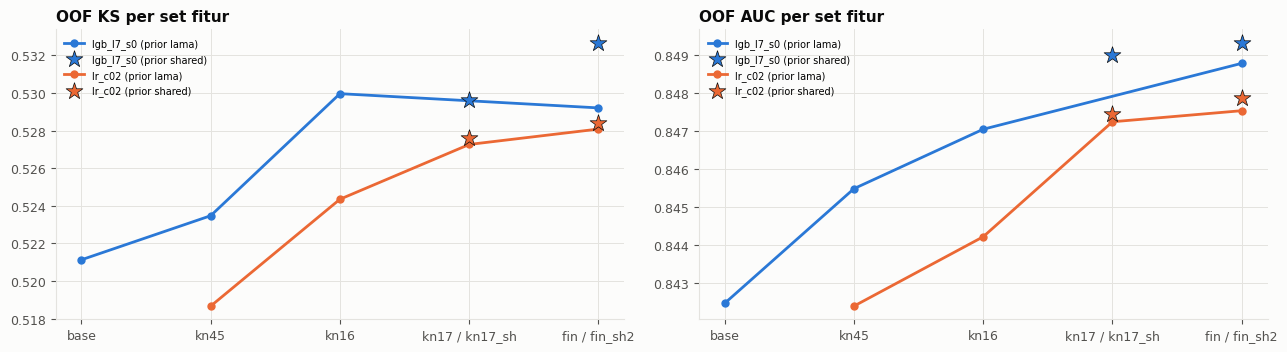

auc                                                 ks                                            
feature_set   base    fin fin_sh2   kn16   kn17 kn17_sh   kn45   base    fin fin_sh2   kn16   kn17 kn17_sh   kn45
model                                                                                                            
lgb_l7_s0   0.8425 0.8488  0.8493 0.8471    NaN  0.8490 0.8455 0.5211 0.5292  0.5327 0.5300    NaN  0.5296 0.5235
lr_c02         NaN 0.8475  0.8479 0.8442 0.8472  0.8474 0.8424    NaN 0.5281  0.5284 0.5243 0.5273  0.5276 0.5187

In [42]:
ORDER = ['base', 'kn45', 'kn16', 'kn17', 'fin']; SH_AT = {'kn17_sh': 'kn17', 'fin_sh2': 'fin'}     # *_sh drawn at its old twin
prog = LB[LB.model.isin(['lgb_l7_s0', 'lr_c02'])].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for mname, c_ in [('lgb_l7_s0', C_GOOD), ('lr_c02', C_BAD)]:
    p = prog[(prog.model == mname) & prog.feature_set.isin(ORDER)].copy(); p['x'] = p.feature_set.map(ORDER.index); p = p.sort_values('x')
    q = prog[(prog.model == mname) & prog.feature_set.isin(list(SH_AT))].copy(); q['x'] = q.feature_set.map(lambda v: ORDER.index(SH_AT[v]))
    for ax, met in zip(axes, ['ks', 'auc']):
        ax.plot(p.x, p[met], marker='o', color=c_, label=f'{mname} (prior lama)')
        ax.scatter(q.x, q[met], marker='*', s=160, color=c_, edgecolor=C_INK, linewidth=0.5, zorder=3, label=f'{mname} (prior shared)')
axes[0].set_title('OOF KS per set fitur'); axes[1].set_title('OOF AUC per set fitur')
for ax in axes: ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(['base', 'kn45', 'kn16', 'kn17 / kn17_sh', 'fin / fin_sh2']); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
display(prog.pivot_table(index='model', columns='feature_set', values=['ks', 'auc'], observed=True).round(4))

- Blok perilaku K/N (base → KN45) menaikkan AUC LightGBM sekitar +0,003; model struktural (KN45 → FIN) menambah sekitar
  +0,003 lagi beserta lompatan KS terbesar.
- Perbaikan prior θ (titik bintang) menaikkan lagi tanpa menambah fitur: leaves7 0,5292 / 0,8488 → 0,5327 / 0,8493 dan LR
  0,5281 / 0,8475 → 0,5284 / 0,8479 (FIN → `fin_sh2`); LR pada KN17 → `kn17_sh`: 0,5273 / 0,8472 → 0,5276 / 0,8474.
- LR paling diuntungkan model struktural (AUC KN45 → FIN +0,005, leaves7 +0,003), karena PD struktural adalah ringkasan
  risiko yang hampir linear.

### 5.3 ROC dan kurva KS (model tunggal acuan: LightGBM leaves7 pada set final `fin_sh2`)

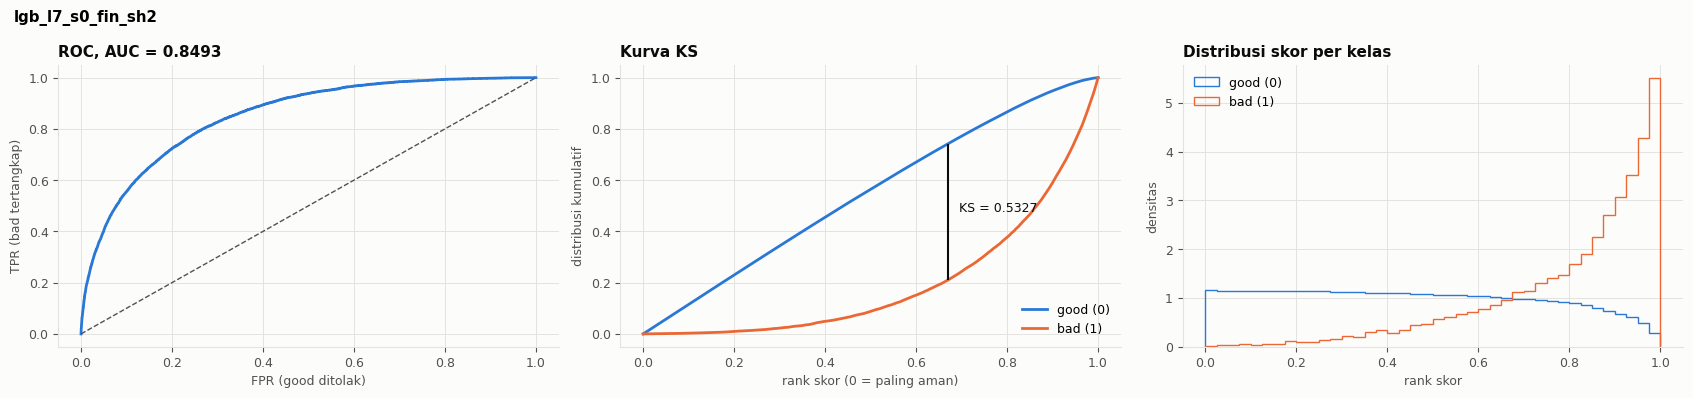

ambang KS di rank 0.670: 21.0% bad vs 74.2% good di bawahnya


In [43]:
def ks_curves(o, title):
    fpr, tpr, thr = roc_curve(y, o); i = np.argmax(tpr - fpr)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    axes[0].plot(fpr, tpr, color=C_MAIN); axes[0].plot([0, 1], [0, 1], ls='--', lw=1, color=C_INK2)
    axes[0].set_xlabel('FPR (good ditolak)'); axes[0].set_ylabel('TPR (bad tertangkap)')
    axes[0].set_title(f'ROC, AUC = {roc_auc_score(y, o):.4f}')
    r = rnk(o); grid = np.linspace(0, 1, 201)
    cb = np.searchsorted(np.sort(r[y == 1]), grid, side='right') / (y == 1).sum()
    cg = np.searchsorted(np.sort(r[y == 0]), grid, side='right') / (y == 0).sum()
    axes[1].plot(grid, cg, color=C_GOOD, label='good (0)'); axes[1].plot(grid, cb, color=C_BAD, label='bad (1)')
    j = np.argmax(cg - cb); axes[1].vlines(grid[j], cb[j], cg[j], color=C_INK, lw=1.5)
    axes[1].annotate(f'KS = {ks(y, o):.4f}', (grid[j], (cb[j] + cg[j]) / 2), xytext=(8, 0), textcoords='offset points', color=C_INK)
    axes[1].set_xlabel('rank skor (0 = paling aman)'); axes[1].set_ylabel('distribusi kumulatif'); axes[1].legend(loc='lower right')
    axes[1].set_title('Kurva KS')
    bins = np.linspace(0, 1, 41)
    axes[2].hist(r[y == 0], bins=bins, density=True, histtype='step', lw=2, color=C_GOOD, label='good (0)')
    axes[2].hist(r[y == 1], bins=bins, density=True, histtype='step', lw=2, color=C_BAD, label='bad (1)')
    axes[2].set_xlabel('rank skor'); axes[2].set_ylabel('densitas'); axes[2].legend(); axes[2].set_title('Distribusi skor per kelas')
    fig.suptitle(title, x=0.01, ha='left', fontweight='bold'); plt.tight_layout(); plt.show()
    print(f'ambang KS di rank {grid[j]:.3f}: {cb[j]:.1%} bad vs {cg[j]:.1%} good di bawahnya')


BEST_SINGLE = 'lgb_l7_s0_fin_sh2'
ks_curves(load_pred(BEST_SINGLE)[0], BEST_SINGLE)

### 5.4 Tabel desil (lift) dan kalibrasi

Desil 1 = 10% skor paling berisiko


,n,bads,bad_rate,mean_pred,lift,cum_bad_capture
decile,,,,,,
1,7000,3895,0.5564,0.5588,4.0970,0.4097
2,7000,2031,0.2901,0.2920,2.1363,0.6233
3,7000,1265,0.1807,0.1802,1.3306,0.7564
4,7000,880,0.1257,0.1228,0.9256,0.8490
5,7000,602,0.0860,0.0830,0.6332,0.9123
6,7000,369,0.0527,0.0540,0.3881,0.9511
7,7000,251,0.0359,0.0327,0.2640,0.9775
8,7000,120,0.0171,0.0184,0.1262,0.9901
9,7000,65,0.0093,0.0094,0.0684,0.9969


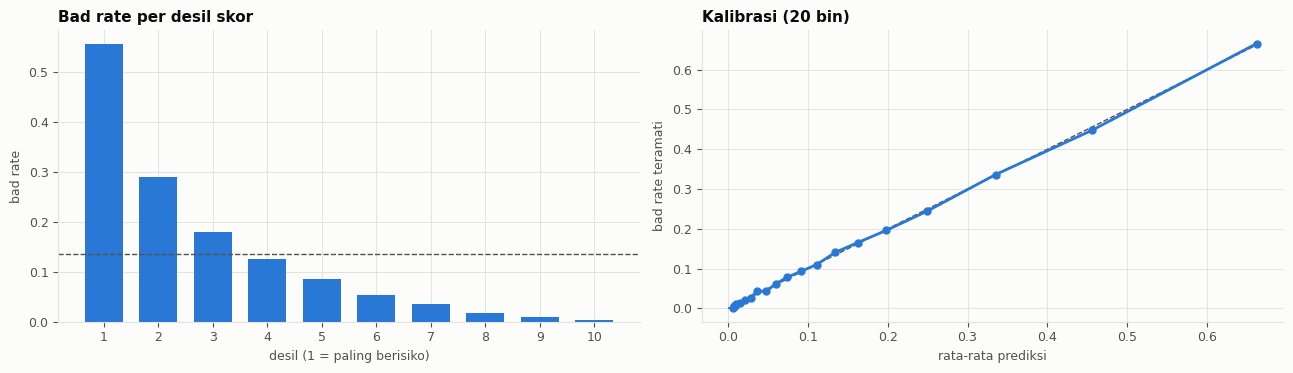

In [44]:
o = load_pred(BEST_SINGLE)[0]
dec = pd.qcut(rnk(o), 10, labels=False)
T = pd.DataFrame({'decile': 10 - dec, 'y': y, 'p': o}).groupby('decile').agg(n=('y', 'size'), bads=('y', 'sum'), bad_rate=('y', 'mean'), mean_pred=('p', 'mean'))
T['lift'] = T.bad_rate / BAD_RATE; T['cum_bad_capture'] = T.bads.cumsum() / T.bads.sum()
print('Desil 1 = 10% skor paling berisiko'); display(T)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(T.index, T.bad_rate, color=C_MAIN, width=0.7); axes[0].axhline(BAD_RATE, ls='--', lw=1, color=C_INK2)
axes[0].set_xticks(T.index); axes[0].set_xlabel('desil (1 = paling berisiko)'); axes[0].set_ylabel('bad rate'); axes[0].set_title('Bad rate per desil skor')
cb = pd.qcut(o, 20, labels=False); C_ = pd.DataFrame({'p': o, 'y': y}).groupby(cb).mean()
axes[1].plot([0, C_.p.max()], [0, C_.p.max()], ls='--', lw=1, color=C_INK2)
axes[1].plot(C_.p, C_.y, marker='o', color=C_MAIN); axes[1].set_xlabel('rata-rata prediksi'); axes[1].set_ylabel('bad rate teramati')
axes[1].set_title('Kalibrasi (20 bin)'); plt.tight_layout(); plt.show()

Desil paling berisiko punya bad rate sekitar 4× rata-rata, dan lima desil teratas menangkap sekitar 90% nasabah *bad*. Probabilitas LightGBM terkalibrasi baik (titik kalibrasi menempel di diagonal), walau untuk KS kalibrasi tidak berpengaruh (hanya urutan).

### 5.5 Kinerja per segmen

In [45]:
_E = load_events(); nev = _E.groupby('customer_id').size(); del _E
segv = pd.cut(key.customer_id[is_tr].map(nev).fillna(0).values, [-1, 0, 9, 19, 1e9], labels=['0 event', '1-9', '10-19', '>=20'])
rows = []
for nm in [BEST_SINGLE, 'lgb_l7_s0_fin', 'lr_c02_fin_sh2', 'lgb_l7_s0_base']:
    o = load_pred(nm)[0]
    for s_ in segv.categories:
        m = np.asarray(segv == s_)
        rows.append(dict(model=nm, segment=s_, n=int(m.sum()), bad_rate=y[m].mean(), ks=ks(y[m], o[m]), auc=roc_auc_score(y[m], o[m])))
SEG = pd.DataFrame(rows); display(SEG.pivot_table(index=['segment', 'n', 'bad_rate'], columns='model', values=['ks', 'auc'], observed=True).round(4))

auc                                                            ks                                               
model                  lgb_l7_s0_base lgb_l7_s0_fin lgb_l7_s0_fin_sh2 lr_c02_fin_sh2 lgb_l7_s0_base lgb_l7_s0_fin lgb_l7_s0_fin_sh2 lr_c02_fin_sh2
segment n     bad_rate                                                                                                                            
0 event 23688 0.1215           0.8274        0.8303            0.8313         0.8318         0.4936        0.5010            0.4999         0.4970
1-9     9328  0.1532           0.8315        0.8413            0.8404         0.8370         0.4938        0.5172            0.5135         0.5086
10-19   16056 0.1471           0.8529        0.8569            0.8583         0.8571         0.5429        0.5455            0.5516         0.5470
>=20    20928 0.1356           0.8529        0.8626            0.8626         0.8600         0.5466        0.5614            0.5633         0.5597

Model paling lemah pada nasabah tanpa riwayat cicilan (segmen 0 event, ~34% baris, KS ≈ 0,50): bagi mereka seluruh PD
struktural berasal dari prior θ, yang hanya memakai aplikasi, profil, biro, dan e-commerce. Makin panjang riwayat cicilan,
makin tinggi KS (0,50 → 0,51 → 0,55 → 0,56), karena θ nasabah makin pasti. Untuk leaves7 tunggal, perbaikan prior
(`lgb_l7_s0_fin_sh2` vs `lgb_l7_s0_fin`) menaikkan AUC di segmen 0 event (+0,0010) dan 10–19 event (+0,0014), sedangkan
segmen 1–9 event turun sedikit (−0,0009); selisih sebesar ini masih dalam noise satu model per segmen. Perbandingan per
segmen yang lebih andal (ensemble + bootstrap berpasangan) ada di bagian 6.5.

### 5.6 Feature importance (gain)

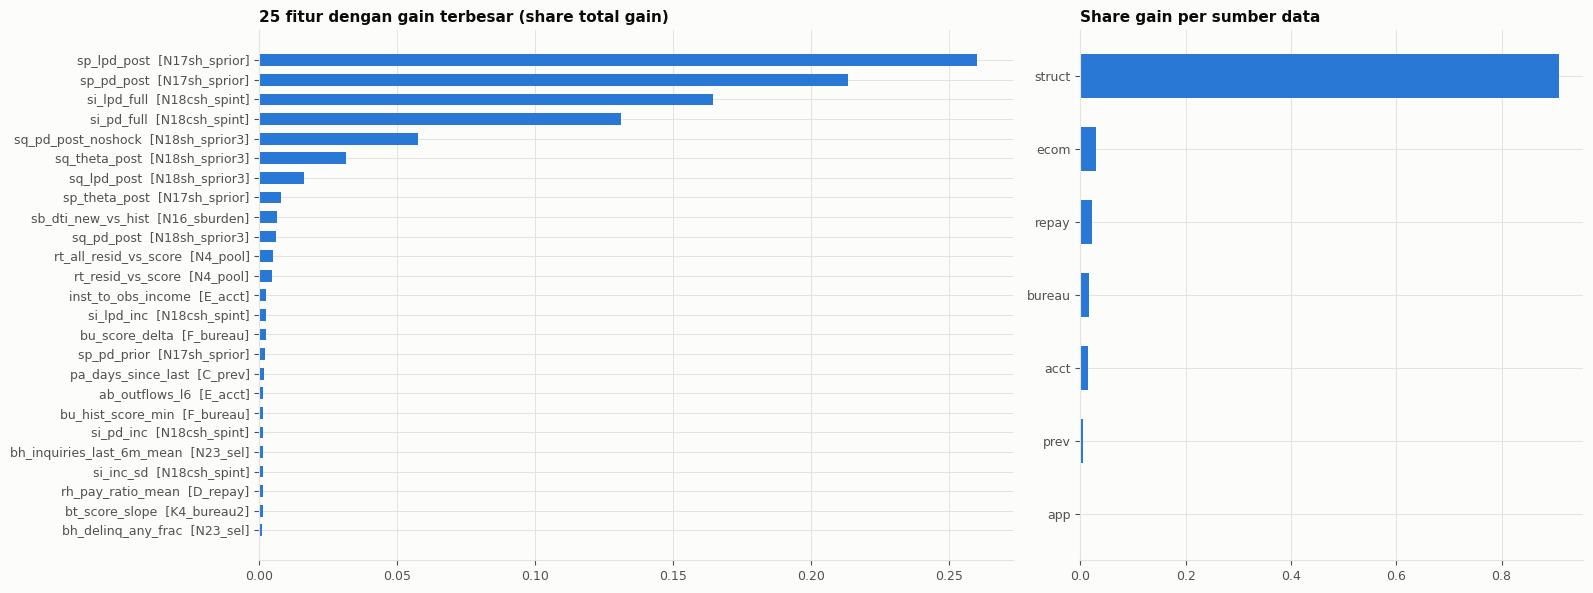

fold 0: 360 trees, valid AUC 0.8506
share gain per sumber: {'struct': 0.909, 'ecom': 0.03, 'repay': 0.023, 'bureau': 0.017, 'acct': 0.014, 'prev': 0.005, 'app': 0.002}


In [46]:
Xf = load_set('fin_sh2'); a, b = FOLDS[0]
Xtr_ = Xf[is_tr].reset_index(drop=True)
mdl = lgb.train(P_L7, lgb.Dataset(Xtr_.iloc[a], y[a]), 10000, valid_sets=[lgb.Dataset(Xtr_.iloc[b], y[b])],
                callbacks=[lgb.early_stopping(200, verbose=False)])
imp = pd.Series(mdl.feature_importance('gain'), index=Xf.columns).sort_values(ascending=False); imp = imp / imp.sum()
col_block = {c: b_ for b_ in BLOCKS + FS['fin_sh2'] for c in papq.read_schema(block_path(b_)).names if c != 'application_id'}
# every feature -> one data source (blocks that mix sources are split by column prefix)
SOURCE_OF_BLOCK = {'A_app': 'app', 'B_profile': 'app', 'C_prev': 'prev', 'D_repay': 'repay', 'K2_repay2': 'repay',
                   'E_acct': 'acct', 'F_bureau': 'bureau', 'K4_bureau2': 'bureau', 'G_ecom': 'ecom', 'H_surge': 'ecom',
                   'I_price': 'ecom', 'J_premium': 'ecom', 'K1_prem2': 'ecom', 'K3_shoptime': 'ecom',
                   'N16_sburden': 'struct', 'N16b_sburden2': 'struct', 'N17_sprior': 'struct', 'N18_sprior3': 'struct', 'N18c_spint': 'struct',
                   'N17sh_sprior': 'struct', 'N18sh_sprior3': 'struct', 'N18csh_spint': 'struct'}
SOURCE_OF_PREFIX = {'rt_': 'repay', 'rp_': 'repay', 'rs_': 'repay', 'ec_': 'ecom', 'ot_': 'ecom', 'ab_': 'acct', 'at_': 'acct', 'bh_': 'bureau'}
src_of = {c: SOURCE_OF_BLOCK.get(col_block[c]) or next(v for k_, v in SOURCE_OF_PREFIX.items() if c.startswith(k_)) for c in Xf.columns}
top = imp.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw=dict(width_ratios=[3, 2]))
axes[0].barh([f'{c}  [{col_block[c]}]' for c in top.index], top.values, color=C_MAIN, height=0.6)
axes[0].set_title('25 fitur dengan gain terbesar (share total gain)')
by_src = imp.groupby(imp.index.map(src_of)).sum().sort_values()
axes[1].barh(by_src.index, by_src.values, color=C_MAIN, height=0.6); axes[1].set_title('Share gain per sumber data')
plt.tight_layout(); plt.show()
print(f'fold 0: {mdl.best_iteration} trees, valid AUC {roc_auc_score(y[b], mdl.predict(Xtr_.iloc[b], num_iteration=mdl.best_iteration)):.4f}')
print('share gain per sumber:', by_src.sort_values(ascending=False).round(3).to_dict())
del Xtr_, mdl; _ = gc.collect()

Sumber: `app` = aplikasi + profil, `prev` = pengajuan lama, `repay` = fitur riwayat cicilan biasa, `struct` = model struktural N16–N18csh, `acct` = rekening, `bureau` = biro, `ecom` = e-commerce. Gain didominasi PD struktural: pohon memakai PD sebagai tulang punggung lalu mengoreksinya sedikit dengan e-commerce, biro, dan rekening. Gain mengukur **pemakaian**, bukan ketergantungan; untuk yang kedua, lihat ablasi di bawah.

### 5.7 Ablasi per sumber data
LightGBM leaves7 pada set final `fin_sh2` dilatih ulang tanpa satu sumber data (semua fitur dari sumber itu dibuang). Penurunan AUC/KS
menunjukkan informasi yang **hanya** dimiliki sumber tersebut. Gain importance di atas mengukur pemakaian, ablasi
mengukur ketergantungan.

fitur per sumber: {'ecom': 160, 'repay': 80, 'acct': 76, 'bureau': 59, 'struct': 39, 'prev': 29, 'app': 19}


,dropped,n_dropped,ks,auc,d_ks,d_auc
3,struct,39,0.5235,0.8455,-0.0092,-0.0038
2,repay,80,0.5322,0.8485,-0.0004,-0.0009
5,bureau,59,0.5312,0.8485,-0.0015,-0.0008
4,acct,76,0.5323,0.8490,-0.0003,-0.0003
6,ecom,160,0.5323,0.8491,-0.0003,-0.0002
1,prev,29,0.5313,0.8492,-0.0014,-0.0001
0,app,19,0.5332,0.8493,0.0005,-0.0000


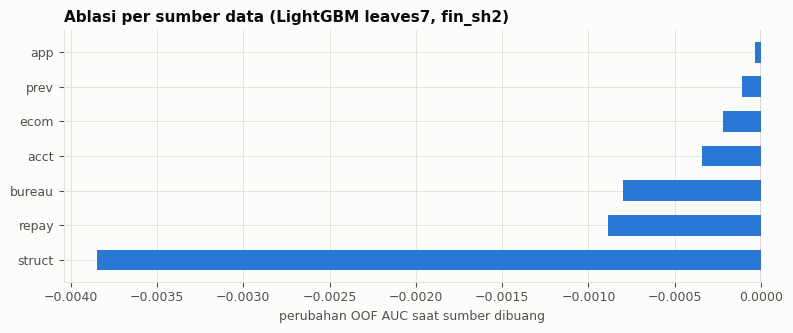

In [47]:
print('fitur per sumber:', pd.Series(src_of).value_counts().to_dict())
if RUN_ABLATION:
    ref = load_pred(BEST_SINGLE)[0]; rows = []
    for s_ in ['app', 'prev', 'repay', 'struct', 'acct', 'bureau', 'ecom']:
        n = f'abl_no_{s_}_l7_finsh'
        if not have_pred(n):
            o = cv_lgb(Xf[[c for c in Xf.columns if src_of[c] != s_]], P_L7, seed=0)[0]; save_pred(n, o)
        o = load_pred(n)[0]
        rows.append(dict(dropped=s_, n_dropped=sum(v == s_ for v in src_of.values()), ks=ks(y, o), auc=roc_auc_score(y, o),
                         d_ks=ks(y, o) - ks(y, ref), d_auc=roc_auc_score(y, o) - roc_auc_score(y, ref)))
    ABL = pd.DataFrame(rows).sort_values('d_auc'); display(ABL)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.barh(ABL.dropped, ABL.d_auc, color=C_MAIN, height=0.6); ax.axvline(0, color=C_INK2, lw=1)
    ax.set_xlabel('perubahan OOF AUC saat sumber dibuang'); ax.set_title('Ablasi per sumber data (LightGBM leaves7, fin_sh2)')
    plt.tight_layout(); plt.show()
del Xf; _ = gc.collect()

Membuang model struktural paling merugikan: ringkasan proses cicilan tidak tergantikan oleh fitur cicilan biasa. Sumber lain masing-masing jauh lebih kecil pengaruhnya, karena informasinya sebagian besar sudah masuk ke PD struktural (prior θ dibangun dari fitur aplikasi, profil, biro, dan e-commerce; riwayat cicilan masuk lewat θ posterior). Perubahan KS di bawah ~0,003 adalah noise (bagian 5.8).

### 5.8 Ketidakpastian: interval bootstrap OOF

In [48]:
def boot_ci(o, n=300, seed=0):
    rng = np.random.default_rng(seed); kk, aa = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); kk.append(ks(y[i], o[i])); aa.append(roc_auc_score(y[i], o[i]))
    return np.percentile(kk, [2.5, 97.5]), np.std(kk), np.percentile(aa, [2.5, 97.5])


k_ci, k_se, a_ci = boot_ci(load_pred(BEST_SINGLE)[0])
print(f'{BEST_SINGLE}: KS 95% CI {k_ci.round(4)} (SE {k_se:.4f}) | AUC 95% CI {a_ci.round(4)}')

lgb_l7_s0_fin_sh2: KS 95% CI [0.5249 0.5428] (SE 0.0047) | AUC 95% CI [0.8456 0.8532]


SE KS ≈ 0,005: selisih KS antar model lepas di bawah ~0,003 tidak bisa dibedakan dari noise sampel. Itulah sebabnya ide baru dinilai dengan AUC, jumlah fold yang naik, pengecekan ulang di seed fold lain (bagian 8), dan bootstrap **berpasangan** (bagian 6.4–6.5), yang menghilangkan noise bersama kedua model.

## 6. Ensemble
Model-model di zoo berbeda algoritma, seed, dan set fitur. Skor tiap model diubah ke **rank-normal (z)** supaya skalanya
sama, lalu digabung dengan bobot non-negatif (koefisien LR di atas z, dipotong ≥ 0, dinormalisasi).

Bobot ensemble dipelajari dari OOF, jadi OOF ensemble in-sample sedikit optimistis. Angka **nested** = bobot di-fit di
4/5 baris train dan dinilai di 1/5 sisanya (SKF seed 7): itulah skor ensemble yang jujur.

### 6.1 Blend → file submission
Tiga blend dari set baru ditulis sebagai file: **`sub_finsh_kn17sh_mix`** (final: 14 model `fin_sh2` + 4 model `kn17_sh` +
3 model `kn16`), `sub_finsh_zoo` (14 model `fin_sh2`), dan `sub_kn17sh_zoo` (14 model `kn17_sh`). Dua blend pembanding dari
set lama dengan model yang sama (`sub_fin_kn17_mix`, `sub_fin_zoo`) hanya dihitung OOF-nya untuk bagian 6.5. Skor nested
dicek dengan dua seed (7 dan 11). File submission berisi rank skor test (0–1) dalam urutan `sample_submission`.

In [49]:
def z(v): return norm.ppf((rankdata(v) - 0.5) / len(v))


def fit_lr(Z, yy, C=1.0):
    return LogisticRegression(C=C, max_iter=2000).fit(Z, yy)


def fit_w(Z, yy):
    """Non-negative weights on z-scores: LR coefficients clipped at 0, normalised to sum 1."""
    m = fit_lr(Z, yy); w = np.clip(m.coef_[0], 0, None)
    return w / w.sum() if w.sum() > 0 else np.ones(Z.shape[1]) / Z.shape[1]


def nested(Z, combiner, seed=7):
    o = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(Z, y):
        o[b] = combiner(Z[a], y[a], Z[b])
    return o


def make_blend(out, names, write=True):
    """Nested-scored (seeds 7 and 11) non-negative z-blend of saved predictions -> WORK_DIR/<out>.csv in sample_submission
    order; write=False for the comparison blends (OOF only)."""
    miss = [n for n in names if not have_pred(n)]
    if miss: print('missing (left out):', miss)
    names = [n for n in names if have_pred(n)]
    O = {n: load_pred(n) for n in names}
    Z = np.column_stack([z(O[n][0]) for n in names]); T = np.column_stack([z(O[n][1]) for n in names])
    w = fit_w(Z, y); oof = Z @ w; te = T @ w
    hon = nested(Z, lambda A, ya, B: B @ fit_w(A, ya)); hon11 = nested(Z, lambda A, ya, B: B @ fit_w(A, ya), seed=11)
    print(out, '| weights', {n: round(float(v), 3) for n, v in zip(names, w) if v > 0})
    log(summary(out + ' (in-sample weights)', oof))
    r = summary(out + ' (nested, honest)', hon); log(r)
    r11 = summary(out + ' (nested seed 11)', hon11); log(r11)
    save_pred(out, oof, te); path = None
    if write:
        smp = read_raw('sample_submission')
        sub = pd.DataFrame({'application_id': key.application_id[~is_tr].values, 'default_probability': rankdata(te) / len(te)})
        sub = smp[['application_id']].merge(sub, on='application_id', how='left')
        assert sub.default_probability.notna().all() and len(sub) == int((~is_tr).sum())
        path = os.path.join(WORK_DIR, f'{out}.csv'); sub.to_csv(path, index=False); print('wrote', path)
    print()
    return dict(r, ks11=r11['ks'], auc11=r11['auc'], n_models=len(names), file=path)


MIX_NEW = [f'{m}_fin_sh2' for m in FIN_ZOO] + [f'{m}_kn17_sh' for m in KN17_PART] + [f'{m}_kn16' for m in KN16_PART]
MIX_OLD = [f'{m}_fin' for m in FIN_ZOO] + [f'{m}_kn17' for m in KN17_PART] + [f'{m}_kn16' for m in KN16_PART]
BLENDS = {'sub_finsh_kn17sh_mix': MIX_NEW,                                   # final submission
          'sub_finsh_zoo': [f'{m}_fin_sh2' for m in FIN_ZOO],
          'sub_kn17sh_zoo': [f'{m}_kn17_sh' for m in KN16_ZOO]}
CONTROL = {'sub_fin_kn17_mix': MIX_OLD, 'sub_fin_zoo': [f'{m}_fin' for m in FIN_ZOO]}      # old prior, same models
res = {k: make_blend(k, v) for k, v in BLENDS.items()}
res.update({k: make_blend(k, v, write=False) for k, v in CONTROL.items()})
REFERENCE = {'sub_finsh_kn17sh_mix': (0.5346, 0.8506), 'sub_finsh_zoo': (0.5340, 0.8505), 'sub_kn17sh_zoo': (0.5325, 0.8498),
             'sub_fin_kn17_mix': (0.5317, 0.8500), 'sub_fin_zoo': (0.5315, 0.8498)}          # run 18 Okt 2026, Colab L4
print(pd.DataFrame([dict(blend=k, n_models=r['n_models'], nested_ks=r['ks'], nested_auc=r['auc'], ks_seed11=r['ks11'],
                         auc_seed11=r['auc11'], ref_ks=REFERENCE[k][0], ref_auc=REFERENCE[k][1],
                         file=os.path.basename(r['file']) if r['file'] else '-') for k, r in res.items()]).to_string(index=False))

sub_finsh_kn17sh_mix | weights {'lr_c02_fin_sh2': 0.143, 'lgb_extra_fin_sh2': 0.005, 'lgb_l7_off_fin_sh2': 0.071, 'lgb_l7_off_s1_fin_sh2': 0.113, 'lgb_extra_off_fin_sh2': 0.163, 'xgb_d4_s0_fin_sh2': 0.11, 'xgb_d4_s1_fin_sh2': 0.028, 'cat_d6_s2_fin_sh2': 0.107, 'cat_d6_s2_kn17_sh': 0.067, 'cat_d6_s1_kn17_sh': 0.045, 'lgb_extra_kn16': 0.119, 'lr_c02_kn16': 0.027}
{"name": "sub_finsh_kn17sh_mix (in-sample weights)", "ks": 0.5347, "auc": 0.8507, "fold_ks": [0.5308, 0.5468, 0.5491, 0.5295, 0.5308]}
{"name": "sub_finsh_kn17sh_mix (nested, honest)", "ks": 0.5346, "auc": 0.8506, "fold_ks": [0.5305, 0.5462, 0.5476, 0.5295, 0.5308]}
{"name": "sub_finsh_kn17sh_mix (nested seed 11)", "ks": 0.534, "auc": 0.8506, "fold_ks": [0.5314, 0.5455, 0.5485, 0.5292, 0.5303]}
wrote /content/drive/MyDrive/Dataset Logika UI/WORK/sub_finsh_kn17sh_mix.csv

sub_finsh_zoo | weights {'lr_c02_fin_sh2': 0.233, 'lgb_extra_fin_sh2': 0.045, 'lgb_l7_off_fin_sh2': 0.079, 'lgb_l7_off_s1_fin_sh2': 0.118, 'lgb_extra_off_fin_sh

### 6.2 Korelasi antar model

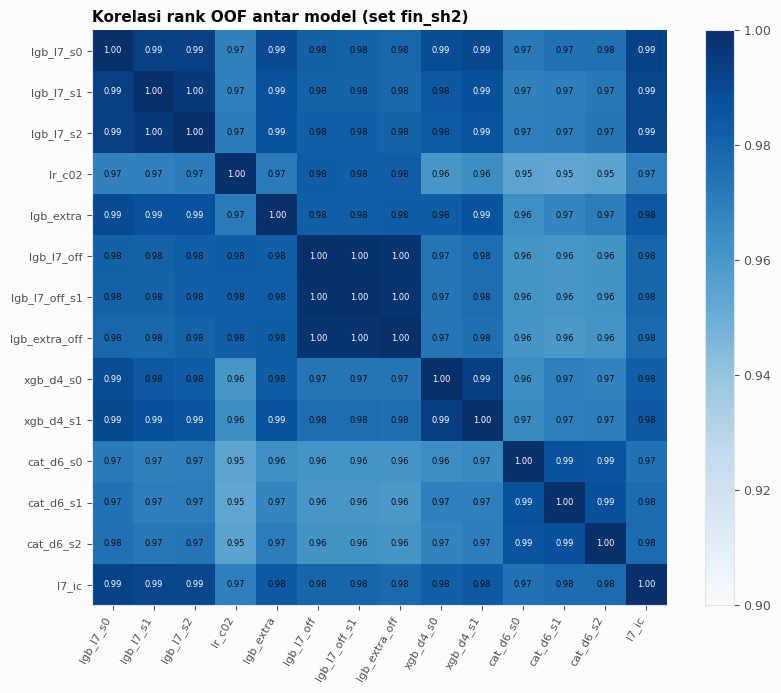

In [50]:
names = [f'{m}_fin_sh2' for m in FIN_ZOO if have_pred(f'{m}_fin_sh2')]
Zc = np.column_stack([z(load_pred(n)[0]) for n in names]); Cc = np.corrcoef(Zc.T)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(Cc, cmap='Blues', vmin=min(0.9, Cc.min()), vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels([n[:-8] for n in names], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels([n[:-8] for n in names], fontsize=8); ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{Cc[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if Cc[i, j] > 0.985 else C_INK)
plt.colorbar(im, fraction=0.046); ax.set_title('Korelasi rank OOF antar model (set fin_sh2)'); plt.tight_layout(); plt.show()

Seed berbeda dari model yang sama praktis identik; antar algoritma pohon sedikit lebih berbeda; LR dan CatBoost paling berbeda, karena itu keduanya mendapat bobot besar. Ruang diversitas kecil karena semua model memakai sinyal dominan yang sama (PD struktural), jadi gain ensemble di atas model tunggal hanya sekitar +0,001–0,002 KS / +0,001 AUC.

### 6.3 Bobot dan perbandingan metode penggabungan

,method,ks,auc
0,model tunggal terbaik (lgb_extra_off_fin_sh2),0.5332,0.8501
1,rata-rata z sama bobot,0.5339,0.8504
2,"bobot non-negatif, nested seed 7",0.5346,0.8506
3,"LR stacking C=0,05, nested seed 7",0.5339,0.8505
4,"bobot non-negatif, nested seed 11",0.5340,0.8506
5,"LR stacking C=0,05, nested seed 11",0.5341,0.8505


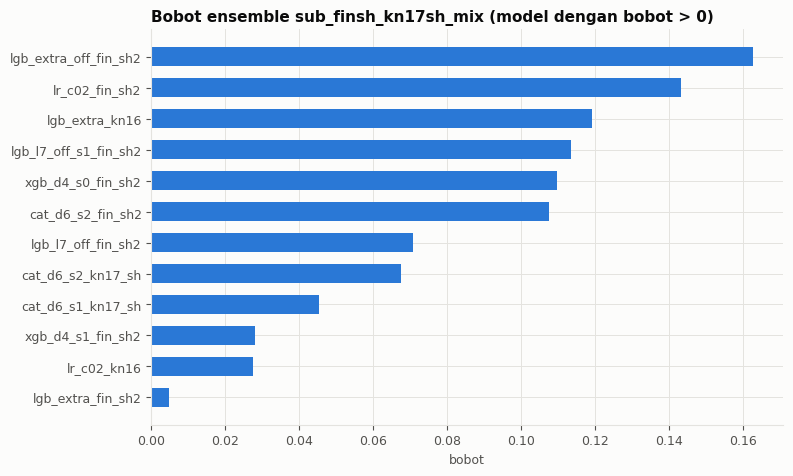

In [51]:
def compare_blends(names):
    Z = np.column_stack([z(load_pred(n)[0]) for n in names]); rows = []
    best = max(names, key=lambda n: roc_auc_score(y, load_pred(n)[0])); ob = load_pred(best)[0]
    rows.append(dict(method=f'model tunggal terbaik ({best})', ks=ks(y, ob), auc=roc_auc_score(y, ob)))
    eq = Z.mean(1); rows.append(dict(method='rata-rata z sama bobot', ks=ks(y, eq), auc=roc_auc_score(y, eq)))
    for s_ in (7, 11):
        o = nested(Z, lambda A_, ya, B_: B_ @ fit_w(A_, ya), seed=s_)
        rows.append(dict(method=f'bobot non-negatif, nested seed {s_}', ks=ks(y, o), auc=roc_auc_score(y, o)))
        o = nested(Z, lambda A_, ya, B_: fit_lr(A_, ya, C=0.05).decision_function(B_), seed=s_)
        rows.append(dict(method=f'LR stacking C=0,05, nested seed {s_}', ks=ks(y, o), auc=roc_auc_score(y, o)))
    w = fit_w(Z, y)
    return pd.DataFrame(rows), pd.Series(w, index=names).sort_values(ascending=False)


MIX = [n for n in BLENDS['sub_finsh_kn17sh_mix'] if have_pred(n)]
cmp_, W = compare_blends(MIX); display(cmp_)
Wp = W[W > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.32 * len(Wp) + 1))
ax.barh(Wp.index, Wp.values, color=C_MAIN, height=0.6); ax.set_xlabel('bobot'); ax.set_title('Bobot ensemble sub_finsh_kn17sh_mix (model dengan bobot > 0)')
plt.tight_layout(); plt.show()

Bobot non-negatif (nested 0,5346 / 0,8506) sedikit lebih baik daripada rata-rata sama bobot (0,5339 / 0,8504) dan setara LR
stacking (0,5339–0,5341 / 0,8505), dengan bobot yang lebih mudah dibaca; metode ini dipakai untuk final. Sebagai acuan, model
tunggal terbaik `lgb_extra_off_fin_sh2` mendapat 0,5332 / 0,8501.

### 6.4 Apakah ensemble benar-benar lebih baik dari model tunggal? (bootstrap berpasangan)

,compare,d_ks,p_ks_gain,d_auc,p_auc_gain
0,sub_finsh_kn17sh_mix (nested) vs lgb_l7_s0_fin...,0.0019,0.8900,0.0012,1.0000
1,sub_finsh_kn17sh_mix (nested) vs lgb_l7_s0_bas...,0.0138,1.0000,0.0081,1.0000


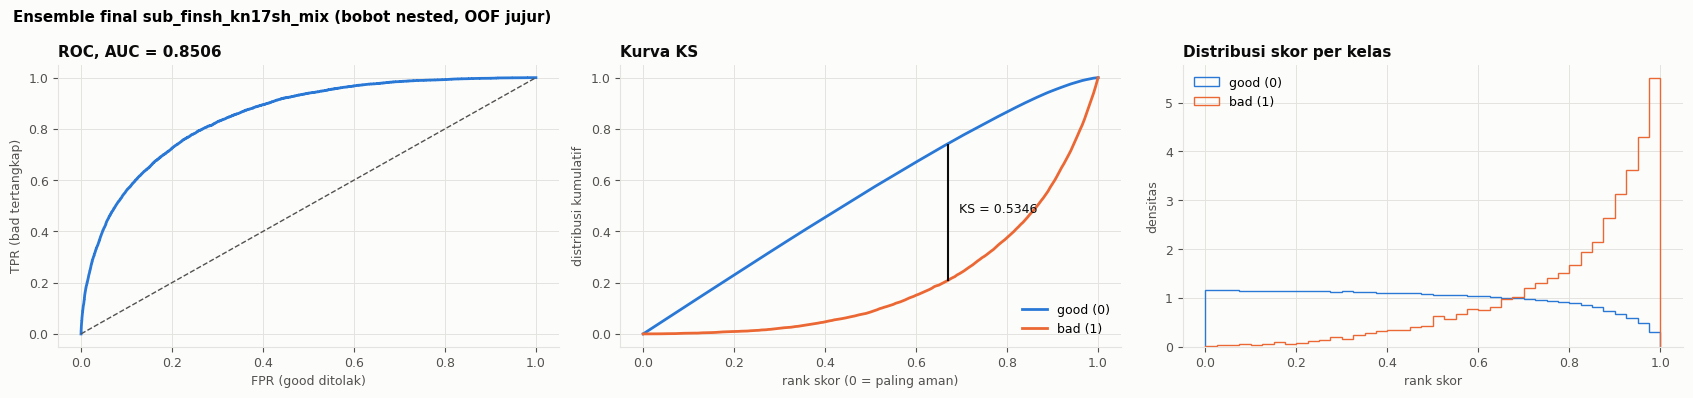

ambang KS di rank 0.670: 20.8% bad vs 74.3% good di bawahnya


In [52]:
def paired_boot(o1, o0, n=300, seed=0):
    rng = np.random.default_rng(seed); dk, da = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        dk.append(ks(y[i], o1[i]) - ks(y[i], o0[i])); da.append(roc_auc_score(y[i], o1[i]) - roc_auc_score(y[i], o0[i]))
    return dict(d_ks=np.mean(dk), p_ks_gain=np.mean(np.array(dk) > 0), d_auc=np.mean(da), p_auc_gain=np.mean(np.array(da) > 0))


Zm = np.column_stack([z(load_pred(n)[0]) for n in MIX])
hon = nested(Zm, lambda A_, ya, B_: B_ @ fit_w(A_, ya))
rows = [dict(compare=f'sub_finsh_kn17sh_mix (nested) vs {BEST_SINGLE}', **paired_boot(hon, load_pred(BEST_SINGLE)[0]))]
if have_pred('lgb_l7_s0_base'):
    rows.append(dict(compare='sub_finsh_kn17sh_mix (nested) vs lgb_l7_s0_base (A-J)', **paired_boot(hon, load_pred('lgb_l7_s0_base')[0])))
display(pd.DataFrame(rows))
ks_curves(hon, 'Ensemble final sub_finsh_kn17sh_mix (bobot nested, OOF jujur)')

Ensemble final menaikkan AUC sekitar +0,0013 di atas leaves7 tunggal pada set yang sama (0,8506 vs 0,8493), konsisten di sampel bootstrap; kenaikan KS (+0,002) masih di dalam noise. Ensemble tetap dipakai karena lebih stabil: risiko satu model yang kebetulan buruk di data test berkurang.

### 6.5 Sebelum vs sesudah perbaikan prior θ (bootstrap berpasangan)
Pembanding yang adil: ensemble dengan model, seed, dan cara blend yang sama persis, hanya prior θ yang berbeda (set lama
`fin`/`kn17` vs set baru `fin_sh2`/`kn17_sh`), dihitung di run yang sama. Bobot dinilai nested (seed 7 dan 11); bootstrap
berpasangan 300× pada baris train. Di bawahnya: setiap model tunggal dibandingkan dengan kembarannya di set lama.

In [53]:
def blend_nested(names, seed=7):
    Z = np.column_stack([z(load_pred(n)[0]) for n in names])
    return nested(Z, lambda A, ya, B: B @ fit_w(A, ya), seed=seed)


SEGM = {'riwayat cicilan': g_hist[is_tr], 'baru': g_new[is_tr], 'lama tanpa cicilan': g_oldnr[is_tr]}
rows, srows = [], []
for new_, old_ in [('sub_finsh_kn17sh_mix', 'sub_fin_kn17_mix'), ('sub_finsh_zoo', 'sub_fin_zoo')]:
    for s_ in (7, 11):
        o1, o0 = blend_nested(BLENDS[new_], s_), blend_nested(CONTROL[old_], s_)
        fa = [roc_auc_score(y[b], o1[b]) - roc_auc_score(y[b], o0[b]) for _, b in FOLDS]
        rows.append(dict(baru=new_, lama=old_, nested_seed=s_, ks_lama=ks(y, o0), ks_baru=ks(y, o1), auc_lama=roc_auc_score(y, o0),
                         auc_baru=roc_auc_score(y, o1), fold_auc_naik=f'{sum(d > 0 for d in fa)}/5', **paired_boot(o1, o0)))
        if s_ == 7:
            for sg, m_ in SEGM.items():
                srows.append(dict(blend=new_, segmen=sg, n=int(m_.sum()), auc_lama=roc_auc_score(y[m_], o0[m_]), auc_baru=roc_auc_score(y[m_], o1[m_]),
                                  ks_lama=ks(y[m_], o0[m_]), ks_baru=ks(y[m_], o1[m_])))
display(pd.DataFrame(rows).round(4)); display(pd.DataFrame(srows).round(4))
pairs = [(f'{m}_fin_sh2', f'{m}_fin') for m in FIN_ZOO] + [(f'{m}_kn17_sh', f'{m}_kn17') for m in KN17_PART]
D_ = pd.DataFrame([dict(model=a_, auc_lama=roc_auc_score(y, load_pred(b_)[0]), auc_baru=roc_auc_score(y, load_pred(a_)[0]),
                        ks_lama=ks(y, load_pred(b_)[0]), ks_baru=ks(y, load_pred(a_)[0])) for a_, b_ in pairs if have_pred(a_) and have_pred(b_)])
D_['d_auc'] = D_.auc_baru - D_.auc_lama; D_['d_ks'] = D_.ks_baru - D_.ks_lama
print(f'model tunggal: AUC naik di {int((D_.d_auc > 0).sum())}/{len(D_)} pasangan, rata-rata {D_.d_auc.mean():+.4f}; '
      f'KS naik di {int((D_.d_ks > 0).sum())}/{len(D_)}, rata-rata {D_.d_ks.mean():+.4f}')
display(D_.round(4))

,baru,lama,nested_seed,ks_lama,ks_baru,auc_lama,auc_baru,fold_auc_naik,d_ks,p_ks_gain,d_auc,p_auc_gain
0,sub_finsh_kn17sh_mix,sub_fin_kn17_mix,7,0.5317,0.5346,0.8500,0.8506,4/5,0.0026,0.9533,0.0006,0.9867
1,sub_finsh_kn17sh_mix,sub_fin_kn17_mix,11,0.5317,0.5340,0.8501,0.8506,3/5,0.0021,0.9167,0.0005,0.9733
2,sub_finsh_zoo,sub_fin_zoo,7,0.5315,0.5340,0.8498,0.8505,4/5,0.0026,0.9433,0.0007,0.9900
3,sub_finsh_zoo,sub_fin_zoo,11,0.5312,0.5343,0.8498,0.8505,3/5,0.0028,0.9400,0.0007,0.9833


,blend,segmen,n,auc_lama,auc_baru,ks_lama,ks_baru
0,sub_finsh_kn17sh_mix,riwayat cicilan,46312,0.8574,0.8577,0.5461,0.5490
1,sub_finsh_kn17sh_mix,baru,21000,0.8315,0.8328,0.5006,0.5027
2,sub_finsh_kn17sh_mix,lama tanpa cicilan,2688,0.8328,0.8326,0.5185,0.5090
3,sub_finsh_zoo,riwayat cicilan,46312,0.8572,0.8577,0.5456,0.5488
4,sub_finsh_zoo,baru,21000,0.8314,0.8327,0.5010,0.5031
5,sub_finsh_zoo,lama tanpa cicilan,2688,0.8313,0.8316,0.5157,0.5068


model tunggal: AUC naik di 18/18 pasangan, rata-rata +0.0008; KS naik di 16/18, rata-rata +0.0018


,model,auc_lama,auc_baru,ks_lama,ks_baru,d_auc,d_ks
0,lgb_l7_s0_fin_sh2,0.8488,0.8493,0.5292,0.5327,0.0005,0.0035
1,lgb_l7_s1_fin_sh2,0.8486,0.8493,0.5312,0.5313,0.0007,0.0001
2,lgb_l7_s2_fin_sh2,0.8486,0.8493,0.5298,0.5323,0.0006,0.0025
3,lr_c02_fin_sh2,0.8475,0.8479,0.5281,0.5284,0.0003,0.0003
4,lgb_extra_fin_sh2,0.8485,0.8495,0.5308,0.5322,0.0010,0.0014
5,lgb_l7_off_fin_sh2,0.8488,0.8499,0.5296,0.5330,0.0011,0.0034
6,lgb_l7_off_s1_fin_sh2,0.8490,0.8499,0.5313,0.5323,0.0009,0.0009
7,lgb_extra_off_fin_sh2,0.8490,0.8501,0.5283,0.5332,0.0011,0.0048
8,xgb_d4_s0_fin_sh2,0.8484,0.8494,0.5301,0.5336,0.0009,0.0035
9,xgb_d4_s1_fin_sh2,0.8481,0.8491,0.5299,0.5318,0.0010,0.0019


Dengan model dan cara blend yang sama, perbaikan prior menaikkan ensemble:
- **Mix** (nested seed 7): KS 0,5317 → **0,5346**, AUC 0,8500 → **0,8506**; seed 11: KS 0,5317 → 0,5340, AUC 0,8501 → 0,8506.
  Bootstrap berpasangan: P(KS naik) 0,95, P(AUC naik) 0,99; AUC naik di 3–4 dari 5 fold.
- **Zoo FIN saja**: +0,0026–0,0028 KS, +0,0007 AUC (P 0,94 / 0,99).
- **Per segmen** (mix): kenaikan terbesar pada nasabah baru (AUC 0,8315 → 0,8328, KS 0,5006 → 0,5027) dan nasabah dengan
  riwayat (KS 0,5461 → 0,5490). Di segmen kecil nasabah lama tanpa cicilan (±2.700 baris train) AUC tetap (0,8328 → 0,8326)
  dan KS turun 0,009, masih dalam noise segmen sekecil itu (SE KS ≈ 0,02).
- **Model tunggal**: 18 dari 18 lebih baik AUC-nya daripada kembarannya di set lama (+0,0002 s.d. +0,0011).

### 6.6 Skor public leaderboard dan pemilihan submission final
Public leaderboard dihitung dari 30% test (~9.000 baris); private dari 70% sisanya. Semua submission mendapat skor publik
≈ OOF + 0,04. Subset publik kebetulan "mudah" untuk semua model sekaligus (prediksinya berkorelasi ≥ 0,99, jadi ini satu
kejadian bersama, bukan keunggulan model tertentu), dan keberuntungan itu tidak terbawa ke baris private.

| Submission | OOF KS nested | OOF AUC nested | Public | Public − OOF KS |
|---|---|---|---|---|
| `submission_final.csv` (versi awal, A–J) | 0,5220 | 0,8440 | 0,55978 | +0,038 |
| `sub_kn16_zoo.csv` | 0,5326 | 0,8487 | 0,56994 | +0,037 |
| `sub_fin_kn17_mix.csv` (prior lama) | 0,5320 | 0,8499 | 0,57305 | +0,041 |
| `sub_kn17_zoo.csv` (prior lama) | 0,5325 | 0,8494 | 0,57530 | +0,043 |
| `sub_finsh_zoo.csv` | 0,5340 | 0,8505 | 0,57206 | +0,038 |
| `sub_kn17sh_zoo.csv` | 0,5325 | 0,8498 | **0,57788** | +0,045 |
| `sub_finsh_kn17sh_mix.csv` (mix, versi zoo) | 0,5346 | 0,8506 | 0,57487 | +0,040 |
| **`sub_final_inference.csv`** (mix yang sama, dilatih ulang di bagian 10) | **0,5346** | **0,8506** | 0,57449 | +0,040 |

OOF empat baris pertama dari log run sebelumnya, sisanya dari run ini. Pertanyaannya: apakah keunggulan publik
`sub_kn17sh_zoo` (+0,003) mengalahkan keunggulan OOF mix (+0,002 KS, +0,0008 AUC, dari data hampir 8× lebih banyak)? Sel di
bawah mengukur sebaran selisih KS berpasangan pada subset acak 9.000 baris dan pada OOF penuh, lalu menggabungkan kedua bukti
dengan bobot invers-varians.

In [54]:
PUBLIC = {'sub_finsh_kn17sh_mix': 0.57487, 'sub_kn17sh_zoo': 0.57788, 'sub_finsh_zoo': 0.57206}     # Kaggle public LB, 18 Okt 2026
o_ = {k: blend_nested(BLENDS[k], 7) for k in PUBLIC}
rng_ = np.random.default_rng(0)


def paired_ks_diffs(o1, o0, n, reps=1500, replace=False):
    d = []
    for _ in range(reps):
        i = rng_.choice(len(y), n, replace=replace); d.append(ks(y[i], o1[i]) - ks(y[i], o0[i]))
    return np.array(d)


base_ = 'sub_finsh_kn17sh_mix'; rows = []
for a_ in ['sub_kn17sh_zoo', 'sub_finsh_zoo']:
    d_oof = ks(y, o_[a_]) - ks(y, o_[base_]); d_pub = PUBLIC[a_] - PUBLIC[base_]
    sd_oof = paired_ks_diffs(o_[a_], o_[base_], len(y), replace=True).std()     # sampling SD of the OOF difference (70k rows)
    sim9 = paired_ks_diffs(o_[a_], o_[base_], 9000); sd_pub = sim9.std()       # the same difference on a random 9k subset
    tail = (sim9 - sim9.mean() + d_oof >= d_pub) if d_pub > d_oof else (sim9 - sim9.mean() + d_oof <= d_pub)
    w1, w2 = sd_oof ** -2, sd_pub ** -2; comb = (d_oof * w1 + d_pub * w2) / (w1 + w2); sd_c = (w1 + w2) ** -0.5
    rows.append(dict(pembanding=f'{a_} − {base_}', korelasi_rank=np.corrcoef(rankdata(o_[a_]), rankdata(o_[base_]))[0, 1],
                     selisih_oof=d_oof, sd_oof=sd_oof, selisih_publik=d_pub, sd_publik_9k=sd_pub, p_publik_seekstrem_ini=tail.mean(),
                     gabungan=comb, sd_gabungan=sd_c, p_lebih_baik_dari_mix=1 - norm.cdf(0, comb, sd_c)))
display(pd.DataFrame(rows).round(4))
print('AUC OOF nested:', {k: round(roc_auc_score(y, v), 4) for k, v in o_.items()})

,pembanding,korelasi_rank,selisih_oof,sd_oof,selisih_publik,sd_publik_9k,p_publik_seekstrem_ini,gabungan,sd_gabungan,p_lebih_baik_dari_mix
0,sub_kn17sh_zoo − sub_finsh_kn17sh_mix,0.9977,-0.0021,0.0013,0.0030,0.0027,0.0280,-0.0012,0.0012,0.1464
1,sub_finsh_zoo − sub_finsh_kn17sh_mix,0.9996,-0.0006,0.0007,-0.0028,0.0017,0.0873,-0.0009,0.0007,0.0867


AUC OOF nested: {'sub_finsh_kn17sh_mix': np.float64(0.8506), 'sub_kn17sh_zoo': np.float64(0.8498), 'sub_finsh_zoo': np.float64(0.8505)}


- Selisih publik `sub_kn17sh_zoo` − mix (+0,0030) cukup jarang bila OOF benar (p ≈ 0,03), tetapi sebaran selisih di subset
  9.000 baris (SD ≈ 0,0027) dua kali sebaran di OOF penuh (SD ≈ 0,0013).
- Digabung dengan bobot invers-varians, mix tetap unggul sekitar 0,001 KS; peluang `sub_kn17sh_zoo` sebenarnya lebih baik
  hanya ±15% (di bawah 40% bahkan bila noise OOF diasumsikan lebih besar). AUC OOF mix juga lebih tinggi (0,8506 vs 0,8498).
- Untuk `sub_finsh_zoo`, OOF dan publik sepakat mix lebih baik.

**Keputusan: final = ensemble mix.** Selisih harapan antar kandidat di private hanya ±0,001, jauh di bawah noise private
(±0,009), jadi pilihan mana pun bukan kesalahan besar, tetapi mix punya peluang terbaik. File yang dikumpulkan adalah versi
mix yang dilatih ulang dengan bobot tersimpan, `sub_final_inference.csv` (bagian 10).

## 7. Submission
Sel ini memeriksa kewajaran tiga file blend dari zoo: jumlah baris, urutan sesuai `sample_submission`, ID sama dengan test,
tanpa nilai kosong, rentang 0–1. `default_probability` adalah rank skor test (0–1); untuk KS hanya urutan yang penting.

**Submission final yang dikumpulkan: `sub_final_inference.csv`** (bagian 10), yaitu ensemble yang sama dengan
`sub_finsh_kn17sh_mix.csv` (14 model `fin_sh2` + 4 `kn17_sh` + 3 `kn16`), dilatih ulang sambil menyimpan bobot: OOF nested
KS 0,5346 / AUC 0,8506, public 0,57449. Baris `FILE FINAL` di output sel ini menunjuk versi zoo, sebelum ekspor; alasan
kedua file sedikit berbeda dijelaskan di bagian 10. Di Kaggle file final dipilih (*Select*) secara manual, karena tanpa
pilihan Kaggle memakai submission dengan skor publik tertinggi.

In [55]:
smp = read_raw('sample_submission'); te_ids = set(key.application_id[~is_tr])
rows = []
for nm in BLENDS:
    p_ = os.path.join(WORK_DIR, f'{nm}.csv'); s_ = pd.read_csv(p_)
    rows.append(dict(file=p_, rows=len(s_), order_matches_sample=bool((s_.application_id.values == smp.application_id.values).all()),
                     ids_match_test=set(s_.application_id) == te_ids, n_null=int(s_.default_probability.isna().sum()),
                     min=s_.default_probability.min(), max=s_.default_probability.max()))
display(pd.DataFrame(rows))
a_ = pd.read_csv(os.path.join(WORK_DIR, 'sub_finsh_kn17sh_mix.csv')); b_ = pd.read_csv(os.path.join(WORK_DIR, 'sub_kn17sh_zoo.csv'))
print('korelasi rank test sub_finsh_kn17sh_mix vs sub_kn17sh_zoo:', round(np.corrcoef(rnk(a_.default_probability), rnk(b_.default_probability))[0, 1], 4))
print('FILE FINAL:', os.path.join(WORK_DIR, 'sub_finsh_kn17sh_mix.csv'))
display(a_.head())

,file,rows,order_matches_sample,ids_match_test,n_null,min,max
0,/content/drive/MyDrive/Dataset Logika UI/WORK/...,30000,True,True,0,0.0000,1.0000
1,/content/drive/MyDrive/Dataset Logika UI/WORK/...,30000,True,True,0,0.0000,1.0000
2,/content/drive/MyDrive/Dataset Logika UI/WORK/...,30000,True,True,0,0.0000,1.0000


korelasi rank test sub_finsh_kn17sh_mix vs sub_kn17sh_zoo: 0.9981
FILE FINAL: /content/drive/MyDrive/Dataset Logika UI/WORK/sub_finsh_kn17sh_mix.csv


,application_id,default_probability
0,A_a4f0104b642c9af0,0.0929
1,A_08d66c9e92ab0b7d,0.4868
2,A_9a520f63bdee8684,0.9564
3,A_7ccd9c4aa0f036b1,0.0563
4,A_559cc08a9c7fa719,0.0898


## 8. Menguji ide baru dan rangkuman eksperimen

### 8.1 Alat uji ide baru
Cara kerja yang dipakai selama ini (dan yang menemukan N16–N18 serta perbaikan prior di 3.6):
1. Cari dulu **mekanisme** di data mentah (tanpa target), misalnya "skip naik saat beban DTI tinggi di dalam nasabah
   yang sama". Fitur tanpa alasan yang jelas hampir selalu gagal.
2. Buat blok fitur: fungsi yang menghasilkan DataFrame ber-index `customer_id` (hanya data sebelum `cut[customer]`),
   simpan dengan `save_idx(df, 'NAMA')`.
3. `quick_eval(['NAMA'])`: tambahkan blok ke set final `fin_sh2`, latih LGB leaves7 + LR + blend 50:50, bandingkan dengan set itu pada
   fold yang sama (~2 menit). Lihat `dauc` dan `folds_up`, bukan hanya KS.
4. Kalau AUC naik (sekitar ≥ +0,0005, mayoritas fold), cek ulang di seed fold lain: `verify_seeds(['NAMA'])`.
5. Kalau konsisten, buat set fitur baru di `FS`, jalankan `run_zoo`, lalu `make_blend` (nested).

Screening cepat yang hanya "boost dari OOF blend" meremehkan nilai blok baru; selalu uji di model penuh seperti di bawah.

In [56]:
def quick_eval(cand, ref='fin_sh2', fold_seed=42, tag=None):
    """Feature set `ref` + candidate blocks vs `ref` alone on the same folds: LGB leaves7 (seed 0), LR (C=0.02) and
    their 50:50 rank blend (dks / dauc / folds_up are relative to `ref`). Returns the blend summary."""
    fl = folds(fold_seed)
    Xr = load_set(ref)
    if fold_seed == 42 and have_pred(f'lgb_l7_s0_{ref}') and have_pred(f'lr_c02_{ref}'):
        r7, rlr = load_pred(f'lgb_l7_s0_{ref}')[0], load_pred(f'lr_c02_{ref}')[0]
    else:
        r7, rlr = cv_lgb(Xr, P_L7, fl=fl)[0], cv_lr(Xr, fl=fl)[0]
    X = pd.concat([Xr, load_blocks(cand)], axis=1); del Xr
    dup = X.columns[X.columns.duplicated()].tolist()
    if dup: print('dropping duplicated columns:', dup); X = X.loc[:, ~X.columns.duplicated()]
    t0 = time.time(); o7 = cv_lgb(X, P_L7, fl=fl)[0]; olr = cv_lr(X, fl=fl)[0]
    tag = tag or f'{ref}+' + '+'.join(cand) + ('' if fold_seed == 42 else f' [folds {fold_seed}]')
    out = {}
    for part, a, b in [('l7', o7, r7), ('lr', olr, rlr), ('blend', 0.5 * rnk(o7) + 0.5 * rnk(olr), 0.5 * rnk(r7) + 0.5 * rnk(rlr))]:
        out[part] = summary(f'{tag} | {part}', a, fl=fl, ref=b); log(out[part])
    print(f'{X.shape[1]} features, {time.time() - t0:.0f}s')
    return out['blend']


def verify_seeds(cand, ref='fin_sh2', seeds=(7, 99, 2024)):
    """The same comparison on other fold splits (the selection above was made on seed 42)."""
    return [quick_eval(cand, ref, fold_seed=s) for s in seeds]


if RUN_DEMO:
    # Example: the N9 premium variants as MODEL features on top of the final set (a dead end on KN45; expect ~0 here).
    quick_eval(['N9_prem3'])
    verify_seeds(['N9_prem3'], seeds=(7,))

In [57]:
# Template for a new block (fill in, then uncomment the calls):
#
# def build_MY_BLOCK():
#     """Rationale: which mechanism this measures and why the current features miss it (checked on raw data, no target)."""
#     rh = read_raw('repayment_history')            # any raw table; every table is already cut at the decision time
#     N = pd.DataFrame(index=idx)                   # one row per customer, key order
#     N['my_feature'] = rh.groupby('customer_id').amount_paid.sum()   # placeholder
#     save_idx(N, 'MY_BLOCK')
#
# run_block('MY_BLOCK', build_MY_BLOCK)
# quick_eval(['MY_BLOCK'])
# verify_seeds(['MY_BLOCK'])
# FS['fin_my'] = FS['fin_sh2'] + ['MY_BLOCK']
# run_zoo('fin_my', FIN_ZOO)
# make_blend('sub_fin_my', [f'{m}_fin_my' for m in FIN_ZOO])

### 8.2 Eksperimen 15 Okt 2026 (tidak ada yang menambah)
Ide: beberapa model GBDT diberi **set fitur berbeda** supaya pola error-nya berbeda dan ensemble membaik, plus tiga ide
fitur baru dari data mentah. Base = 21 model `sub_fin_kn17_mix` (nested KS 0,5320 / AUC 0,8499). Skrip eksperimen ini
dijalankan terpisah dan tidak termasuk notebook; hasilnya dicatat di sini.

| Ide | Isi | Hasil |
|---|---|---|
| Zoo *feature view* | 27 model: buang satu sumber data, view kecil (`core`, `behav`), subspace sumber/kolom acak, model offset | view kuat berkorelasi 0,98–0,995 dengan model penuh; view tanpa riwayat lemah (AUC 0,81–0,83) → bobot ~0. Blend nested KS 0,5316–0,5333, AUC +0,0000–0,0001, bootstrap P(KS naik) ≤ 0,79 |
| Prior θ per sumber data | prior N18 dilatih dari satu sumber (app / ecom / rekening / biro) | segmen tanpa riwayat: AUC 0,67 / 0,78 / 0,57 / 0,68 vs prior gabungan 0,83. Sebagai fitur: blend KS −0,001; sebagai model beragam: korelasi 0,98, blend tidak berubah |
| Ko-gerak pendapatan–belanja | apakah belanja e-com bulanan mengikuti pendapatan bulanan nasabah | korelasi dalam nasabah +0,001: mekanismenya tidak ada |
| Dekomposisi outflow rekening | outflows = 1,00·belanja e-com + 0,87·cicilan dibayar + 0,45·pendapatan + konstanta + sisa (R² 0,85) | 27 fitur N25_flow: blend KS −0,0015, AUC −0,0001 |
| Utang biro sebagai beban di model event | laporan biro terakhir sebelum tiap jatuh tempo, efek dalam nasabah | utang eksternal −0,02 logit (log-lik +0,8 dari 1,36 juta event): tidak berpengaruh |

Kesimpulan: semua model yang kuat bergantung pada sinyal yang sama, dan model yang benar-benar berbeda selalu jauh
lebih lemah. Sisa error adalah noise setelah keputusan (lihat perkiraan plafon di bagian 9).

### 8.3 Eksperimen 18 Okt 2026: prior θ dari kovariat shared (dipakai)
Diagnosis dan perbaikan ada di bagian 3.6. Sebelum zoo dibangun, perbaikan diuji dengan protokol 8.1: set lama vs set baru pada
fold yang sama, LightGBM leaves7 + LR + blend 50:50, di empat seed fold (selisih baru − lama):

| Varian | Model | Δ AUC seed 42 / 7 / 99 / 2024 | Δ AUC rata-rata | Δ KS rata-rata |
|---|---|---|---|---|
| ganti N17 + N18 + N18c (`fin_sh2`) | leaves7 | +0,0005 / +0,0002 / +0,0005 / +0,0004 | +0,0004 | +0,0015 |
| | LR | +0,0004 / +0,0003 / +0,0003 / +0,0002 | +0,0003 | +0,0011 |
| | blend | +0,0004 / +0,0002 / +0,0004 / +0,0002 | +0,0003 | +0,0005 |
| ganti N18 + N18c saja | blend | +0,0004 / +0,0003 / +0,0004 / +0,0002 | +0,0003 | +0,0002 |
| tambah kolom prior shared ke FIN (tanpa mengganti) | blend | +0,0004 (seed 42) | – | +0,0006 |

AUC naik di keempat seed untuk ketiga model (per fold 12/20 untuk blend). Di level zoo kenaikannya lebih besar (+0,0002 s.d.
+0,0011 AUC per model; model `_off` paling diuntungkan karena offset `si_lpd_full` ikut membaik) dan ensemble naik sekitar
+0,0026 KS / +0,0006 AUC (bagian 6.5). Sel di bawah mengulang uji set-vs-set (`RUN_DEMO`, ~5 menit per seed).

In [58]:
def compare_sets(ref_fs, cand_fs, fold_seed=42):
    """Two feature sets with the same columns (e.g. old vs shared prior) on the same folds: leaves7 + LR + 50:50 blend."""
    fl = folds(fold_seed); Xr, Xn = load_set(ref_fs), load_set(cand_fs)
    r7, rlr = cv_lgb(Xr, P_L7, fl=fl)[0], cv_lr(Xr, fl=fl)[0]; o7, olr = cv_lgb(Xn, P_L7, fl=fl)[0], cv_lr(Xn, fl=fl)[0]
    for part, a, b in [('l7', o7, r7), ('lr', olr, rlr), ('blend', 0.5 * rnk(o7) + 0.5 * rnk(olr), 0.5 * rnk(r7) + 0.5 * rnk(rlr))]:
        log(summary(f'{cand_fs} vs {ref_fs} | {part} [folds {fold_seed}]', a, fl=fl, ref=b))


if RUN_DEMO:
    for s_ in (42, 7):
        compare_sets('fin', 'fin_sh2', s_)

## 9. Kesimpulan dan catatan untuk melanjutkan

### Kesimpulan
- **Pipeline**: EDA menemukan bahwa target dibangkitkan oleh proses bayar/lewati bulanan yang sama dengan riwayat cicilan
  lama; fitur dibuat dari mekanisme itu (model struktural + perilaku menjelang keputusan), lalu zoo GBDT + LR dan ensemble
  yang dinilai nested CV.
- **Perbaikan terakhir** (bagian 3.6): prior θ hanya dari kovariat yang tersedia untuk semua nasabah. Dengan model yang sama,
  ensemble naik dari nested KS 0,5317 / AUC 0,8500 ke **0,5346 / 0,8506** (bootstrap berpasangan: P(KS naik) ≈ 0,95,
  P(AUC naik) ≈ 0,99), dan 18 dari 18 model tunggal naik AUC-nya.
- **Submission final**: **`sub_final_inference.csv`** (public 0,57449), yaitu ensemble mix yang dilatih ulang dengan bobot
  tersimpan (bagian 10). Perkiraan private ≈ OOF ≈ 0,535 ± 0,009; turun sekitar 0,04 dari skor publik itu wajar karena
  subset publik kebetulan "mudah".
- **Plafon**: simulasi dari model struktural menunjukkan skor ini dekat batas informasi data; sisa error berasal dari
  kejadian setelah keputusan (pinjaman baru, guncangan pendapatan, 12 undian bayar/lewati).

### Fakta tentang data / generator yang ditemukan
- Pembayaran = keputusan bulanan bayar/lewati. Pembayaran jatuh di timestamp jatuh tempo, keterlambatan berupa kelipatan
  satu bulan, dan cicilan mencapai 90 DPD tepat jika belum dibayar di akhir hari jatuh tempo + 90.
- Peluang skip bergantung pada: kecenderungan nasabah θ (konstan, tanpa drift; τ² ≈ 0,8); beban total cicilan /
  pendapatan deklarasi (cekung: DTI + DTI²; pinjaman sendiri dan pinjaman lain berkoefisien sama); cicilan ke-1 dan
  ke-2 lebih sering di-skip; guncangan pendapatan bulan itu dan bulan sebelumnya; bulan-sebelum-keputusan (efek
  seleksi persetujuan). Setelah θ dikontrol, status backlog hampir tidak berpengaruh. Tidak ada musiman kalender.
- θ bisa diprediksi dari fitur non-cicilan (varians residual 0,27 vs 0,81 tanpa kovariat; 0,32 bila hanya kovariat shared).
- Prior θ yang dilatih di event cicilan hanya melihat nasabah lama, yang semuanya punya pengajuan lama dan rekening;
  kovariat yang kosong untuk nasabah baru dibaca LightGBM sebagai 0 (bagian 3.6). Prior dari kovariat shared lebih baik di
  semua segmen.
- Untuk nasabah dengan ≥ 20 event cicilan, PD struktural hampir tidak menyisakan sinyal bagi fitur lain (kecuali
  volatilitas pendapatan): target memang dimediasi oleh proses cicilan.
- Biro: provider bisa dipertukarkan; setiap laporan adalah bacaan bernoise (reliabilitas 0,81) dari trait konstan.
- Price premium: noise per item Gaussian (sd 0,652), trait unimodal.
- E-commerce: jumlah order bad dan good sama, tetapi order bad bergeser mendekati keputusan; seminggu sebelum
  keputusan bad rata-rata 1,60 order vs 0,68.
- Rekening: arus keluar *bad* naik tajam sejak ±6 bulan sebelum keputusan; saldonya setara *good* lalu tertinggal pada 2–3
  bulan terakhir.
- Segmen terlemah: 30% nasabah baru tanpa pengajuan lama, cicilan, maupun rekening (AUC ensemble final 0,833, KS ≈ 0,50).
- Public LB: semua submission ≈ OOF + 0,04; selisih publik antar submission yang berkorelasi ≥ 0,99 bisa sekitar ±0,003
  hanya karena kebetulan subset (bagian 6.6). Pilih final berdasarkan OOF, bukan skor publik.

### Sudah dicoba, tidak membantu
- **Tuning & arsitektur**: random search / Optuna (maks +0,001 AUC, rawan overfit ke noise CV); pohon lebih dalam
  (leaves 63, XGB depth 6) lebih buruk; MLP, RandomForest, ExtraTrees, NN tabular torch (KS 0,48–0,50; gain NN di blend
  tidak bertahan di nested CV).
- **Objective**: rank_xendcg −0,0054, lambdarank −0,0016, linear_tree −0,0069, `scale_pos_weight` 3 −0,038 KS; monotone
  constraints dan one-hot kategori ±0.
- **Ensemble**: stacking 35 model ≈ blend biasa; model per segmen, rekalibrasi per segmen, LR slope per segmen, GAM murni,
  pseudo-label; zoo *feature view* dan prior per sumber data (bagian 8.2).
- **Fitur lain**: seleksi null-importance; residual pricing; *teacher feature* (label bantu dari pinjaman lama); fitur
  relatif terhadap peer; delta biro; pola mentah e-commerce per minggu/kategori/jam/metode bayar (korelasi residual
  ≤ 0,007); label positif berbobot IPCW untuk jendela parsial; augmentasi pinjaman lama sebagai baris train tambahan;
  residual per event (MIL). Tidak ada sinyal residual yang tersisa di tabel mana pun.
- **Blok N lain**: N1 (premium detrended), N6 (jendela disjoint), N7 (belanja vs pendapatan), N8 (belanja saat pengajuan
  pending), N9 sebagai fitur model, N10–N14 (antrean cicilan, marginal), N15 (waktu order skala log), N19 (beban pinjaman
  masa depan), N22 (step seleksi 30 hari), N23_sclean (prior tanpa variabel harga), N25 (dekomposisi outflow).
- **Model event**: offset bulan keputusan, musiman kalender pada skip, θ berbobot waktu (lebih buruk).

**Perkiraan plafon.** Bootstrap SE OOF KS ≈ 0,005. Simulasi target dari model struktural: kalau model benar dan tidak ada
pinjaman baru setelah keputusan, informasi yang ada memberi AUC ~0,856 / KS ~0,55; dengan pinjaman masa depan acak (laju
dan ukuran teramati) AUC 0,846–0,849 / KS 0,526–0,535, setara angka riil. Kenaikan besar butuh informasi baru, bukan model
yang lebih rumit.

### Arah yang belum dieksplor
- Prior θ hibrida: kovariat shared untuk semua nasabah ditambah kovariat lama yang bukan fungsi event cicilan (misalnya
  pendapatan rekening), dengan *masking* blok saat training supaya pola kosong nasabah baru ikut dipelajari.
- Guncangan pendapatan asimetris di rantai Markov (log-lik event +417, belum dipasang); interaksi θ × guncangan pendapatan;
  model mengejar tunggakan yang lebih kaya. (Catatan: perbaikan model event sejauh ini jarang menaikkan AUC target.)
- Efek tunggakan pinjaman lain terhadap pinjaman baru (*contagion*): +0,15 logit setelah θ dikontrol di level event, belum
  dimasukkan ke rantai.

## 10. Ekspor bobot model untuk notebook inference
Run penuh tanpa cache memakan ±2–2,5 jam (> 30 menit), jadi pengumpulan memakai metode **Inference-Only**: bobot model
disimpan sebagai berkas, lalu `logika_ui_2026_inference.ipynb` memuat bobot itu dan menghasilkan submission tanpa melatih
ulang.

Zoo di bagian 4 hanya menyimpan prediksi OOF/test (`.npy`), bukan objek model. Bagian ini melatih ulang **21 model ensemble
final** (`MIX_NEW`: 14 model `fin_sh2` + 4 `kn17_sh` + 3 `kn16`) dengan resep, fold, seed, dan early stopping yang sama
dengan bagian 4.1, sambil menyimpan setiap model fold:

| Jenis model | Berkas per fold |
|---|---|
| LightGBM (`lgb_l7_s*`, `lgb_extra`, `l7_ic`) | `fold{k}.txt` (dipotong di iterasi early stopping) |
| LightGBM `*_off` | `fold{k}.txt` + `fold{k}_cal.joblib` (kalibrasi logistik offset struktural) |
| Logistic Regression | `fold{k}.joblib` (QuantileTransformer, daftar kolom missing, StandardScaler, LogisticRegression) |
| XGBoost | `fold{k}.json` |
| CatBoost | `fold{k}.cbm` |

Langkah:
1. **Latih ulang + simpan** ke `WORK_DIR/export` (cache per model; kalau runtime putus, run ulang melanjutkan yang belum
   selesai). Log membandingkan OOF hasil latih ulang dengan prediksi zoo (`max_diff_oof`).
2. **Bobot ensemble** di-fit ulang dari OOF hasil latih ulang (metode `make_blend`), dinilai nested CV.
3. **Bundle** `WORK_DIR/inference_bundle`: model berbobot > 0, fitur baris test per blok, urutan `sample_submission`, dan
   `manifest.json` (model, set fitur, bobot, iterasi per fold, versi library).
4. **Submission dibuat dari bundle** dengan fungsi yang sama persis dengan notebook inference (`run_inference`), lalu
   disimpan sebagai `expected_submission.csv` di bundle dan `WORK_DIR/sub_final_inference.csv`.
5. Bundle di-zip: `WORK_DIR/logika_ui_2026_inference_bundle.zip` (dibagikan lewat Google Drive).

Fitur test ikut di bundle karena blok fitur struktural (prior θ N17sh/N18sh, GLM random intercept N16–N18csh) juga berisi
model yang di-fit (±20 menit per versi prior); menghitungnya ulang berarti melatih ulang. Kode pembuatan fiturnya ada di
bagian 3.

Butuh runtime GPU (XGBoost/CatBoost seperti run referensi). Run referensi: 19 menit di Colab L4.

In [59]:
import joblib, shutil, hashlib, platform, scipy, sklearn
import pyarrow as _pyarrow
EXPORT_DIR = os.path.join(WORK_DIR, 'export')                    # retrained OOF/test predictions + fold models of all 21
EXP_PRED, EXP_MODELS = os.path.join(EXPORT_DIR, 'preds'), os.path.join(EXPORT_DIR, 'models')
BUNDLE_DIR = os.path.join(WORK_DIR, 'inference_bundle')          # what the inference notebook loads
BUNDLE_ZIP = os.path.join(WORK_DIR, 'logika_ui_2026_inference_bundle.zip')
FINAL_SUB = os.path.join(WORK_DIR, 'sub_final_inference.csv')    # final submission, produced from the bundle
EXPORT_SETS = ['fin_sh2', 'kn17_sh', 'kn16']
MIX_SPEC = [(m, 'fin_sh2') for m in FIN_ZOO] + [(m, 'kn17_sh') for m in KN17_PART] + [(m, 'kn16') for m in KN16_PART]
assert [f'{m}_{fs}' for m, fs in MIX_SPEC] == MIX_NEW
for d in [EXP_PRED, EXP_MODELS]: os.makedirs(d, exist_ok=True)


def model_spec(m):
    """Training recipe of a zoo model name: the same as ZOO in section 4.2."""
    exact = {'lgb_extra': ('lgb', dict(P_L7, **EXTRA), 0), 'l7_ic': ('lgb_ic', P_L7, 0),
             'lgb_l7_off': ('lgb_off', P_L7, 0), 'lgb_l7_off_s1': ('lgb_off', P_L7, 1),
             'lgb_extra_off': ('lgb_off', dict(P_L7, **EXTRA), 0), 'lr_c02': ('lr', dict(C=0.02), 0)}
    if m in exact:
        kind, p, s = exact[m]; return dict(kind=kind, params=p, seed=s)
    for pre, kind, p in [('lgb_l7_s', 'lgb', P_L7), ('xgb_d4_s', 'xgb', dict(max_depth=4)), ('cat_d6_s', 'cat', dict(depth=6))]:
        if m.startswith(pre): return dict(kind=kind, params=p, seed=int(m[len(pre):]))
    raise KeyError(m)


def ic_groups(X, blocks):
    """Interaction constraints of l7_ic (= cv_l7_ic): a tree combines features of one block, plus pa_n and rh_n_inst."""
    cols = list(X.columns); groups = {}
    for b in blocks:
        for c in papq.read_schema(block_path(b)).names:
            if c != 'application_id' and c in cols: groups.setdefault(b, []).append(cols.index(c))
    seg = [cols.index('pa_n'), cols.index('rh_n_inst')]
    return [sorted(set(v) | set(seg)) for v in groups.values()]


def jsonable(p):
    return {k: v for k, v in p.items() if k != 'interaction_constraints'}


def train_export(m, fs, X, mdir):
    """Fold loop of cv_lgb / cv_l7_ic / cv_lgb_off / cv_lr / cv_xgb / cv_cat (section 4.1), unchanged, plus saving every
    fold model to mdir. Returns OOF, the in-memory test prediction and the manifest entry of the model."""
    sp = model_spec(m); kind, seed = sp['kind'], sp['seed']
    os.makedirs(mdir, exist_ok=True)
    Xtr = X[is_tr].reset_index(drop=True); Xte = X[~is_tr].reset_index(drop=True)
    oof = np.zeros(len(Xtr)); pte = np.zeros(len(Xte)); folds_info = []; used_params = sp['params']
    if kind in ('lgb', 'lgb_ic'):
        params = sp['params'] if kind == 'lgb' else dict(P_L7, interaction_constraints=ic_groups(X, BLOCKS + FS[fs]))
        used_params = dict(params, seed=seed)
        for k, (a, b) in enumerate(FOLDS):
            mdl = lgb.train(dict(params, seed=seed), lgb.Dataset(Xtr.iloc[a], y[a]), 10000,
                            valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b])], callbacks=[lgb.early_stopping(200, verbose=False)])
            it = mdl.best_iteration
            oof[b] = mdl.predict(Xtr.iloc[b], num_iteration=it); pte += mdl.predict(Xte, num_iteration=it) / len(FOLDS)
            mdl.save_model(os.path.join(mdir, f'fold{k}.txt'), num_iteration=it)
            folds_info.append(dict(file=f'fold{k}.txt', n_iter=int(it)))
    elif kind == 'lgb_off':
        offcols = offcol(X); used_params = dict(sp['params'], seed=seed, offcols=offcols)
        for k, (a, b) in enumerate(FOLDS):
            cal = LogisticRegression(C=100, max_iter=2000).fit(Xtr[offcols].values[a], y[a])
            ia, ib, it_ = (cal.decision_function(M) for M in (Xtr[offcols].values[a], Xtr[offcols].values[b], Xte[offcols].values))
            mdl = lgb.train(dict(sp['params'], seed=seed), lgb.Dataset(Xtr.iloc[a], y[a], init_score=ia), 10000,
                            valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b], init_score=ib)], callbacks=[lgb.early_stopping(200, verbose=False)])
            it = mdl.best_iteration
            oof[b] = ib + mdl.predict(Xtr.iloc[b], num_iteration=it, raw_score=True)
            pte += (it_ + mdl.predict(Xte, num_iteration=it, raw_score=True)) / len(FOLDS)
            mdl.save_model(os.path.join(mdir, f'fold{k}.txt'), num_iteration=it)
            joblib.dump(dict(cal=cal, offcols=offcols), os.path.join(mdir, f'fold{k}_cal.joblib'))
            folds_info.append(dict(file=f'fold{k}.txt', cal=f'fold{k}_cal.joblib', n_iter=int(it)))
    elif kind == 'lr':
        Xtr = Xtr.astype('float64'); Xte = Xte.astype('float64')
        for k, (a, b) in enumerate(FOLDS):
            A = Xtr.iloc[a]
            miss = [c for c in A.columns if A[c].isna().any()]
            qt = QuantileTransformer(n_quantiles=1000, output_distribution='normal', subsample=10**9, random_state=0).fit(A.values)
            mats = [lr_matrix(qt, miss, M) for M in (A, Xtr.iloc[b], Xte)]
            sc = StandardScaler().fit(mats[0]); mats = [sc.transform(M) for M in mats]
            lr = LogisticRegression(C=sp['params']['C'], max_iter=3000).fit(mats[0], y[a])
            oof[b] = lr.decision_function(mats[1]); pte += lr.decision_function(mats[2]) / len(FOLDS)
            joblib.dump(dict(qt=qt, miss=miss, scaler=sc, lr=lr), os.path.join(mdir, f'fold{k}.joblib'))
            folds_info.append(dict(file=f'fold{k}.joblib', n_missing_indicators=len(miss)))
    elif kind == 'xgb':
        import xgboost as xgb
        p = dict(objective='binary:logistic', eval_metric='auc', learning_rate=0.03, max_depth=6, min_child_weight=10,
                 subsample=0.8, colsample_bytree=0.6, reg_lambda=5.0, max_bin=256, verbosity=0,
                 device='cuda' if HAS_GPU else 'cpu', tree_method='hist')
        p.update(sp['params']); p['seed'] = seed; used_params = p
        Xa = X[is_tr].values; dte = xgb.DMatrix(X[~is_tr].values)
        for k, (a, b) in enumerate(FOLDS):
            dtr = xgb.DMatrix(Xa[a], label=y[a]); dva = xgb.DMatrix(Xa[b], label=y[b])
            bst = xgb.train(p, dtr, 10000, evals=[(dva, 'val')], early_stopping_rounds=200, verbose_eval=False)
            rng = (0, bst.best_iteration + 1)
            oof[b] = bst.predict(dva, iteration_range=rng); pte += bst.predict(dte, iteration_range=rng) / len(FOLDS)
            bst.save_model(os.path.join(mdir, f'fold{k}.json'))
            folds_info.append(dict(file=f'fold{k}.json', n_iter=int(bst.best_iteration) + 1))
    elif kind == 'cat':
        from catboost import CatBoostClassifier
        p = dict(loss_function='Logloss', iterations=10000, learning_rate=0.05, depth=6, l2_leaf_reg=5, border_count=254,
                 od_type='Iter', od_wait=200, use_best_model=True, verbose=0, allow_writing_files=False)
        p.update(dict(task_type='GPU', devices='0') if HAS_GPU else dict(task_type='CPU', thread_count=os.cpu_count()))
        p.update(sp['params']); p['random_seed'] = seed; used_params = p
        for k, (a, b) in enumerate(FOLDS):
            mdl = CatBoostClassifier(**p); mdl.fit(Xtr.iloc[a], y[a], eval_set=(Xtr.iloc[b], y[b]))
            oof[b] = mdl.predict_proba(Xtr.iloc[b])[:, 1]; pte += mdl.predict_proba(Xte)[:, 1] / len(FOLDS)
            mdl.save_model(os.path.join(mdir, f'fold{k}.cbm'))
            folds_info.append(dict(file=f'fold{k}.cbm', n_iter=int(mdl.tree_count_)))
    else:
        raise ValueError(kind)
    entry = dict(name=f'{m}_{fs}', model=m, feature_set=fs, kind=kind, params=jsonable(used_params), folds=folds_info)
    return oof, pte, entry

In [60]:
# ---- inference core: identical in pipeline section 10 and in logika_ui_2026_inference.ipynb ----
def z(v): return norm.ppf((rankdata(v) - 0.5) / len(v))


def lr_matrix(qt, miss, M):
    """LR input (= prep_quantile): quantile-normal transform with NaN -> 0, plus missing indicators of the columns
    that had NaN in the training fold."""
    return np.hstack([np.nan_to_num(qt.transform(M.values), nan=0.0), M[miss].isna().values.astype(float)])


def load_test_blocks(blocks, fdir):
    """Test feature matrix of the given blocks, built exactly like load_blocks (float32, +-inf -> NaN), test-file order."""
    parts, ids = [], None
    for b in blocks:
        d = pd.read_parquet(os.path.join(fdir, b + '.parquet'))
        if ids is None: ids = d.application_id.values
        assert (d.application_id.values == ids).all(), b
        parts.append(d.drop(columns='application_id'))
    return pd.concat(parts, axis=1).replace([np.inf, -np.inf], np.nan).astype('float32'), ids


def predict_model(entry, X, mdir):
    """Test prediction of one zoo model = mean of its fold models, accumulated in fold order as in the training loop."""
    kind, folds = entry['kind'], entry['folds']; n = len(folds); pte = np.zeros(len(X))
    if kind == 'lr': Xf = X.astype('float64')
    if kind == 'xgb':
        import xgboost as xgb
        dte = xgb.DMatrix(X.values)
    if kind == 'cat':
        from catboost import CatBoostClassifier
    for f in folds:
        path = os.path.join(mdir, f['file'])
        if kind in ('lgb', 'lgb_ic'):
            pte += lgb.Booster(model_file=path).predict(X, num_iteration=f['n_iter']) / n
        elif kind == 'lgb_off':
            c = joblib.load(os.path.join(mdir, f['cal']))
            pte += (c['cal'].decision_function(X[c['offcols']].values)
                    + lgb.Booster(model_file=path).predict(X, num_iteration=f['n_iter'], raw_score=True)) / n
        elif kind == 'lr':
            a = joblib.load(path)
            pte += a['lr'].decision_function(a['scaler'].transform(lr_matrix(a['qt'], a['miss'], Xf))) / n
        elif kind == 'xgb':
            bst = xgb.Booster(); bst.load_model(path)
            try:
                bst.set_param({'device': 'cpu'})        # inference always on CPU: same numbers on any machine
            except Exception:
                pass
            pte += bst.predict(dte, iteration_range=(0, f['n_iter'])) / n
        elif kind == 'cat':
            m = CatBoostClassifier(); m.load_model(path)
            pte += m.predict_proba(X)[:, 1] / n
        else:
            raise ValueError(kind)
    return pte


def run_inference(bundle_dir, verbose=True):
    """Bundle -> test prediction of every model with weight > 0 -> z-rank blend -> submission in sample_submission order.
    No model is trained here."""
    with open(os.path.join(bundle_dir, 'manifest.json')) as fh: man = json.load(fh)
    fdir = os.path.join(bundle_dir, 'features_test')
    used = [e for e in man['models'] if e['weight'] > 0]
    preds, test_ids = {}, None
    for fs, blocks in man['feature_sets'].items():
        todo = [e for e in used if e['feature_set'] == fs]
        if not todo: continue
        X, ids = load_test_blocks(blocks, fdir)
        assert X.shape == (man['n_test'], man['n_features'][fs]), (fs, X.shape)
        if test_ids is None: test_ids = ids
        assert (ids == test_ids).all(), fs
        if verbose: print(f'feature set {fs}: {X.shape[1]} features', flush=True)
        for e in todo:
            t0 = time.time(); preds[e['name']] = predict_model(e, X, os.path.join(bundle_dir, 'models', e['name']))
            if verbose: print(f"  {e['name']:24s} weight {e['weight']:.4f} | {len(e['folds'])} folds | {time.time() - t0:5.1f}s", flush=True)
        del X; gc.collect()
    te = np.zeros(len(test_ids))
    for e in used: te += e['weight'] * z(preds[e['name']])          # manifest order
    order = pd.read_csv(os.path.join(bundle_dir, 'submission_order.csv')).application_id.values
    sub = pd.DataFrame({'application_id': test_ids, 'default_probability': rankdata(te) / len(te)})
    sub = pd.DataFrame({'application_id': order}).merge(sub, on='application_id', how='left')
    assert sub.default_probability.notna().all() and len(sub) == len(test_ids) == man['n_test']
    return sub, preds, man


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()


def compare_submissions(path_a, path_b, label_a='a', label_b='b'):
    """Identical ids + identical default_probability values? Otherwise how far apart (ranks)."""
    a, b = pd.read_csv(path_a), pd.read_csv(path_b)
    same_ids = len(a) == len(b) and bool((a.application_id.values == b.application_id.values).all())
    same = same_ids and bool(np.array_equal(a.default_probability.values, b.default_probability.values))
    r = dict(identical=same, same_ids_and_order=same_ids)
    if same_ids and not same:
        va, vb = a.default_probability.values, b.default_probability.values
        r.update(rows_equal=int((va == vb).sum()), rank_corr=round(float(np.corrcoef(va, vb)[0, 1]), 6),
                 max_abs_diff=float(np.max(np.abs(va - vb))), mean_abs_diff=float(np.mean(np.abs(va - vb))))
    print(f'{label_a} vs {label_b}:', r)
    return r

In [61]:
def exp_have(name):
    files = [os.path.join(EXP_MODELS, name, 'entry.json'), os.path.join(EXP_PRED, f'{name}_oof.npy'),
             os.path.join(EXP_PRED, f'{name}_test.npy')]
    return name not in FORCE and 'export' not in FORCE and all(os.path.exists(p) for p in files)


def export_train():
    """Step 1: retrain the 21 final-mix models, saving every fold model (cached per model)."""
    assert RUN_XGB and RUN_CAT, 'ekspor butuh XGBoost + CatBoost seperti run referensi: pakai runtime GPU dan ZOO_MODE = full'
    for fs in EXPORT_SETS:
        todo = [m for m, f in MIX_SPEC if f == fs and not exp_have(f'{m}_{fs}')]
        if not todo:
            print('cached:', fs); continue
        X = load_set(fs); print(f'feature set {fs}: {X.shape[1]} features', flush=True)
        for m in todo:
            name = f'{m}_{fs}'; mdir = os.path.join(EXP_MODELS, name); t0 = time.time()
            if os.path.isdir(mdir): shutil.rmtree(mdir)
            o, t, entry = train_export(m, fs, X, mdir)
            np.save(os.path.join(EXP_PRED, f'{name}_oof.npy'), o); np.save(os.path.join(EXP_PRED, f'{name}_test.npy'), t)
            with open(os.path.join(mdir, 'entry.json'), 'w') as fh: json.dump(entry, fh, indent=1)
            FORCE.discard(name)
            r = dict(name=name, ks=round(ks(y, o), 4), auc=round(roc_auc_score(y, o), 4), sec=round(time.time() - t0))
            if have_pred(name):                                  # the zoo prediction of the same model (section 4)
                oz, tz = load_pred(name)
                r.update(ks_zoo=round(ks(y, oz), 4), auc_zoo=round(roc_auc_score(y, oz), 4),
                         max_diff_oof=float(np.max(np.abs(o - oz))))
                if tz is not None: r['max_diff_test'] = float(np.max(np.abs(t - tz)))
            print(json.dumps(r), flush=True)
        del X; gc.collect()
    FORCE.discard('export')


def export_weights():
    """Step 2: blend weights re-fitted on the retrained OOF (same method as make_blend) + honest nested scores."""
    Z = np.column_stack([z(np.load(os.path.join(EXP_PRED, f'{n}_oof.npy'))) for n in MIX_NEW])
    w = fit_w(Z, y)
    hon = nested(Z, lambda A, ya, B: B @ fit_w(A, ya)); hon11 = nested(Z, lambda A, ya, B: B @ fit_w(A, ya), seed=11)
    scores = dict(in_sample=summary('retrained mix (in-sample weights)', Z @ w),
                  nested=summary('retrained mix (nested, honest)', hon), nested_seed11=summary('retrained mix (nested seed 11)', hon11))
    print('weights', {n: round(float(v), 3) for n, v in zip(MIX_NEW, w) if v > 0})
    for v in scores.values(): log(v)
    print('referensi bagian 6.1 (zoo lama): nested KS 0.5346 / AUC 0.8506')
    return w, scores


def lib_versions():
    import xgboost, catboost
    return dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
                sklearn=sklearn.__version__, lightgbm=lgb.__version__, xgboost=xgboost.__version__,
                catboost=catboost.__version__, pyarrow=_pyarrow.__version__, joblib=joblib.__version__)


def export_bundle(w, scores):
    """Steps 3-5: bundle (models with weight > 0, test features, submission order, manifest), submission produced FROM the
    bundle with run_inference (the inference notebook's code), zip."""
    if os.path.isdir(BUNDLE_DIR): shutil.rmtree(BUNDLE_DIR)
    fdir = os.path.join(BUNDLE_DIR, 'features_test'); os.makedirs(fdir); os.makedirs(os.path.join(BUNDLE_DIR, 'models'))
    sets = {fs: BLOCKS + FS[fs] for fs in EXPORT_SETS}
    test_ids = key.application_id[~is_tr].values
    for b in dict.fromkeys(sum(sets.values(), [])):             # every block once
        d = pd.read_parquet(block_path(b))
        assert (d.application_id.values == key.application_id.values).all(), b
        d = d.loc[~is_tr].reset_index(drop=True); assert (d.application_id.values == test_ids).all(), b
        d.to_parquet(os.path.join(fdir, b + '.parquet'), index=False)
    read_raw('sample_submission')[['application_id']].to_csv(os.path.join(BUNDLE_DIR, 'submission_order.csv'), index=False)
    models = []
    for n, wi in zip(MIX_NEW, w):
        with open(os.path.join(EXP_MODELS, n, 'entry.json')) as fh: e = json.load(fh)
        e.update(weight=float(wi), in_bundle=bool(wi > 0)); models.append(e)
        if wi > 0: shutil.copytree(os.path.join(EXP_MODELS, n), os.path.join(BUNDLE_DIR, 'models', n))
    n_feat = {fs: int(sum(len(papq.read_schema(block_path(b)).names) - 1 for b in bl)) for fs, bl in sets.items()}
    man = dict(final_blend='sub_finsh_kn17sh_mix', created=time.strftime('%Y-%m-%d %H:%M'), n_test=int((~is_tr).sum()),
               folds='StratifiedKFold(5, shuffle=True, random_state=42); test prediction = mean of the 5 fold models',
               blend='per model z = norm.ppf((rank - 0.5) / n) over the test rows; score = sum(weight * z) over the models '
                     'with weight > 0 in manifest order; default_probability = rank(score) / n, rows in submission_order.csv order',
               feature_sets=sets, n_features=n_feat, scores_oof=scores, versions=lib_versions(), models=models)
    man_path = os.path.join(BUNDLE_DIR, 'manifest.json')
    with open(man_path, 'w') as fh: json.dump(man, fh, indent=1)
    print(f'bundle: {sum(e["in_bundle"] for e in models)} of {len(models)} models have weight > 0 and are bundled')
    # submission from the bundle, with exactly the code of the inference notebook
    sub, preds, _ = run_inference(BUNDLE_DIR)
    for n, p in preds.items():
        t_mem = np.load(os.path.join(EXP_PRED, f'{n}_test.npy'))
        print(f'  {n:24s} bundle vs in-memory test prediction: max |diff| {np.max(np.abs(p - t_mem)):.2e}')
    exp_path = os.path.join(BUNDLE_DIR, 'expected_submission.csv')
    sub.to_csv(exp_path, index=False); shutil.copyfile(exp_path, FINAL_SUB)
    man['expected_sha256'] = file_sha256(exp_path)
    with open(man_path, 'w') as fh: json.dump(man, fh, indent=1)
    if os.path.exists(BUNDLE_ZIP): os.remove(BUNDLE_ZIP)
    shutil.make_archive(BUNDLE_ZIP[:-4], 'zip', root_dir=BUNDLE_DIR)
    print('wrote', FINAL_SUB, '| sha256', man['expected_sha256'][:16])
    print(f'wrote {BUNDLE_ZIP} ({os.path.getsize(BUNDLE_ZIP) / 2**20:.0f} MB)')
    return sub

In [62]:
if RUN_EXPORT:
    t_exp = time.time()
    export_train()                                   # step 1 (~30 min on Colab L4)
    W_EXPORT, SCORES_EXPORT = export_weights()       # step 2
    sub_export = export_bundle(W_EXPORT, SCORES_EXPORT)   # steps 3-5
    print(f'ekspor selesai dalam {(time.time() - t_exp) / 60:.1f} menit\n')
    old_sub = os.path.join(WORK_DIR, 'sub_finsh_kn17sh_mix.csv')
    if os.path.exists(old_sub):
        cmp = compare_submissions(FINAL_SUB, old_sub, 'sub_final_inference.csv', 'sub_finsh_kn17sh_mix.csv (sudah di-submit)')
        if cmp['identical']:
            print('IDENTIK: file yang sudah di-submit = output notebook inference. Tidak perlu submit ulang.')
        else:
            print('TIDAK IDENTIK (latih ulang tidak bit-identik, biasanya karena CatBoost GPU). Submit sub_final_inference.csv '
                  'ke Kaggle, pilih (Select) sebagai final, dan kumpulkan file itu ke panitia.')
    display(sub_export.head())
else:
    print('RUN_EXPORT = False: bagian 10 dilewati')

feature set fin_sh2: 462 features
{"name": "lgb_l7_s0_fin_sh2", "ks": 0.5327, "auc": 0.8493, "sec": 44, "ks_zoo": 0.5327, "auc_zoo": 0.8493, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lgb_l7_s1_fin_sh2", "ks": 0.5313, "auc": 0.8493, "sec": 51, "ks_zoo": 0.5313, "auc_zoo": 0.8493, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lgb_l7_s2_fin_sh2", "ks": 0.5323, "auc": 0.8493, "sec": 46, "ks_zoo": 0.5323, "auc_zoo": 0.8493, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lr_c02_fin_sh2", "ks": 0.5284, "auc": 0.8479, "sec": 99, "ks_zoo": 0.5284, "auc_zoo": 0.8479, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lgb_extra_fin_sh2", "ks": 0.5322, "auc": 0.8495, "sec": 58, "ks_zoo": 0.5322, "auc_zoo": 0.8495, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lgb_l7_off_fin_sh2", "ks": 0.533, "auc": 0.8499, "sec": 46, "ks_zoo": 0.533, "auc_zoo": 0.8499, "max_diff_oof": 0.0, "max_diff_test": 0.0}
{"name": "lgb_l7_off_s1_fin_sh2", "ks": 0.5323, "auc": 0.8499, "sec": 

,application_id,default_probability
0,A_a4f0104b642c9af0,0.0927
1,A_08d66c9e92ab0b7d,0.4872
2,A_9a520f63bdee8684,0.9564
3,A_7ccd9c4aa0f036b1,0.0561
4,A_559cc08a9c7fa719,0.0899


### Hasil ekspor (run 28 Okt 2026)
- **LightGBM, LR, XGBoost**: OOF dan prediksi test hasil latih ulang identik dengan zoo (`max_diff 0`).
- **CatBoost (GPU)** tidak deterministik: tiga model berubah sangat kecil (selisih ≤ 3·10⁻⁴), tiga lainnya lebih jelas
  (`cat_d6_s1_fin_sh2`, `cat_d6_s2_fin_sh2`, `cat_d6_s2_kn16`), tetapi skornya setara (KS berubah ≤ 0,001, AUC ≤ 0,0001).
- **Ensemble**: bobot di-fit ulang (13 dari 21 model berbobot > 0; `lgb_l7_s0_fin_sh2` kini mendapat 0,001). Skor nested
  sama dengan zoo: KS 0,5346 / AUC 0,8506 (seed 11: 0,5342 / 0,8506).
- **Bundle**: prediksi dari bundle sama dengan prediksi di memori (selisih 0; XGBoost ≤ 5·10⁻⁷ karena inferensi di CPU);
  zip 91 MB.
- **Submission**: `sub_final_inference.csv` tidak identik dengan `sub_finsh_kn17sh_mix.csv` (korelasi rank 0,999999), jadi
  file inilah yang di-submit dan dipilih sebagai final: **public 0,57449** (vs 0,57487; selisih jauh di bawah noise publik
  ±0,003). Notebook inference menghasilkan file yang identik dengannya.

### 10.1 Bobot dan submission yang dikumpulkan
- **Tautan bobot** (zip bundle, akses *Anyone with the link*): https://drive.google.com/file/d/17TGK0hVucm9TEjB3SBrgcVADiSBMgXyc/view?usp=sharing
- **Notebook inference**: `logika_ui_2026_inference.ipynb`, dengan `BUNDLE_URL` berisi tautan di atas. Sudah diuji di runtime
  Colab baru: unduhan berhasil tanpa izin tambahan dan output **identik** dengan `expected_submission.csv` (nilai dan sha256).
- **Submission**: `sub_final_inference.csv`.

Jangan menjalankan ulang bagian 10 di Drive ini dengan `RUN_EXPORT = True`. Model di `WORK_DIR/export` memang di-cache, tetapi
bundle dan zip tetap dibuat ulang. Zip yang dibuat ulang menjadi file Drive baru dengan link berbeda, sehingga tautan di atas
tidak berlaku lagi. Alternatif Kaggle Dataset: unggah isi folder `inference_bundle` sebagai dataset publik tim, lalu isi
`BUNDLE_DIR = '/kaggle/input/<nama-dataset>'` di notebook inference.